# StudyMate: Beginner ML Tutor

**Goal:** Answer beginner and moderate machine learning questions with a simple explanation, a real-life example, a memory trick, a flashcard question, and a whiteboard picture for demo lessons.

**Data sources:**
- **Core ML lessons** (`ml_lessons.csv`): 50 beginner topics written by our team.
- **AI Dictionary of Terms** (Alex Nubla, Hugging Face `alexnubla/ai-dictionary-terms`, MIT license): simple and detailed explanations of AI terms.

## 1. Setup: Project Folder and Libraries

**Purpose:** Connect Google Drive, create the project folders, and install the libraries.

**Why:** A dedicated project folder keeps raw data, processed data, and evaluation files organized.

In [33]:
# CODE CELL 1 — SETUP: PROJECT FOLDER AND LIBRARIES
!pip install -q datasets sentence-transformers

from google.colab import drive
drive.mount("/content/drive")

import os
import pandas as pd

project_path = "/content/drive/MyDrive/StudyMate_v2"
for sub in ["data/raw", "data/processed", "data/evaluation"]:
    os.makedirs(os.path.join(project_path, sub), exist_ok=True)

print("Project folder ready:", project_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folder ready: /content/drive/MyDrive/StudyMate_v2


## 2. Load and Explore the Data

**Purpose:** Load both data sources, save an untouched copy of the AI dictionary, and check size, columns, empty cells, duplicates, and text length.

**Why:** We need to understand the data before building lessons from it.

**Output:** Basic facts about the core lessons and the AI dictionary, plus 3 sample dictionary terms.

In [34]:
# CODE CELL 2 — LOAD AND EXPLORE THE DATA
from datasets import load_dataset

# Core ML lessons (our team)
core = pd.read_csv(os.path.join(project_path, "data", "raw", "ml_lessons.csv")).fillna("")

# AI Dictionary of Terms (Hugging Face, MIT license)
lessons_raw = load_dataset("alexnubla/ai-dictionary-terms", split="train").to_pandas()
lessons_raw.to_csv(os.path.join(project_path, "data", "raw", "ai_dictionary_raw.csv"), index=False)

for name, df, key in [("Core lessons", core, "title"), ("AI dictionary", lessons_raw, "term")]:
    empty = df.isna() | df.astype(str).apply(lambda c: c.str.strip().eq(""))
    print(f"=== {name} ===")
    print("Rows:", len(df), "| Columns:", len(df.columns))
    print("Empty cells:", int(empty.sum().sum()), "| Duplicate names:", df[key].duplicated().sum())

print("\nAI dictionary terms per category:")
print(lessons_raw["category"].value_counts())

print("\nAverage words per field:")
print("  Core simple_explanation:", round(core["simple_explanation"].str.split().str.len().mean()))
for col in ["simple_version", "detailed_explanation"]:
    print(f"  Dictionary {col}:", round(lessons_raw[col].str.split().str.len().mean()))

display(lessons_raw.sample(3, random_state=1)[["term", "category", "simple_version"]])

=== Core lessons ===
Rows: 50 | Columns: 11
Empty cells: 0 | Duplicate names: 0
=== AI dictionary ===
Rows: 211 | Columns: 7
Empty cells: 0 | Duplicate names: 1

AI dictionary terms per category:
category
Architecture              51
Training                  43
Healthcare AI             28
Deployment                27
Legal AI                  20
Ethics & Safety           19
Enterprise AI & Agents    15
Evaluation                 8
Name: count, dtype: int64

Average words per field:
  Core simple_explanation: 46
  Dictionary simple_version: 21
  Dictionary detailed_explanation: 90


,term,category,simple_version
44,Computer-Aided Detection (CAD),Healthcare AI,AI that helps radiologists by automatically pointing out potential problems in medical...
189,Systemic Risk,Legal AI,The risk that very powerful AI could cause large-scale harm to society — like threaten...
51,Cross-Validation,Evaluation,A method of testing an AI by training it on different portions of data multiple times ...


## 3. Build the Lesson Library

**Finding from exploration:** The AI dictionary covers modern AI broadly, but only about 12 of our 50 core ML topics. Classic ML (regression, classifiers, metrics, clustering, preprocessing) is missing. The core lessons also contain 3 template sentences repeated in every lesson.

**How the library is built:**
1. Start with the 50 core lessons and remove the repeated template sentences.
2. For the ~12 topics found in both sources, add the dictionary's richer explanation to the core lesson (no duplicate lessons).
3. Add about 20 hand-picked dictionary terms that beginner and moderate learners ask about, skipping near-duplicates.
4. Build one search text per lesson, with similar length for both sources.

**Output:** `lessons_v2.csv` saved to Drive, with counts by source and any picks that were not found.

In [35]:
# CODE CELL 3 — BUILD THE LESSON LIBRARY
import re

def norm(t):
    """Lowercase and drop brackets: 'Machine Learning (ML)' -> 'machine learning'."""
    return re.sub(r"\s*\(.*?\)", "", str(t)).lower().strip()

def as_text(x):
    return x if isinstance(x, str) else ", ".join(list(x))

d = lessons_raw.drop_duplicates("term").copy()          # removes the duplicate "Distillation"
d.index = d["term"].apply(norm)

# 1. Core ML lessons, repeated template sentences removed
template = ["This idea is useful when working with real data.",
            "It helps us understand how a machine learning system works and how it can solve a problem.",
            "The example below shows how the concept connects to everyday life."]
def remove_template(text):
    for s in template:
        text = str(text).replace(s, "")
    return " ".join(text.split())

lib = pd.DataFrame({
    "title": core["title"], "topic": core["topic"], "source": "core",
    "simple_explanation": core["simple_explanation"].apply(remove_template),
    "short_detail": core["technical_explanation"],
    "detailed_explanation": core["technical_explanation"],
    "real_world_example": core["real_world_example"],
    "related_terms": core["next_lesson"],
    "extra_simple": "",
})

# 2. Enrich shared topics with dictionary text (no duplicate lessons)
shared = {
    "What is Machine Learning?": "machine learning", "Supervised Learning": "supervised learning",
    "Unsupervised Learning": "unsupervised learning", "Reinforcement Learning": "reinforcement learning",
    "Overfitting": "overfitting / underfitting", "Underfitting": "overfitting / underfitting",
    "Cross-Validation": "cross-validation", "Regularization": "regularization",
    "Neural Network Basics": "neural network", "Neurons and Weights": "weights",
    "Activation Functions": "activation function", "Loss and Optimizers": "optimizer",
}
for title, key in shared.items():
    if key not in d.index:
        print("Shared topic not found:", key)
        continue
    i = lib.index[lib["title"] == title][0]
    lib.at[i, "extra_simple"] = d.at[key, "simple_version"]
    lib.at[i, "short_detail"] += " " + d.at[key, "description"]
    lib.at[i, "detailed_explanation"] += " " + d.at[key, "detailed_explanation"]

# 3. Add hand-picked dictionary terms (beginner/moderate, no near-duplicates)
picks = ["deep learning", "gradient descent", "learning rate", "backpropagation", "dropout",
         "transfer learning", "fine-tuning", "self-supervised learning", "softmax function",
         "convolutional neural network", "recurrent neural network", "transformer", "attention",
         "embedding", "large language model", "tokenization", "hyperparameter",
         "data augmentation", "hallucination", "generative ai"]

def find(pick):
    if pick in d.index:
        return pick
    close = [k for k in d.index if k.startswith(pick) or pick.startswith(k.rstrip("s"))]
    return close[0] if close else None

used, new_rows, not_found = set(shared.values()), [], []
for p in picks:
    k = find(p)
    if k is None or k in used:
        not_found.append(p)
        continue
    used.add(k)
    r = d.loc[k]
    new_rows.append({"title": r["term"], "topic": r["category"], "source": "dictionary",
                     "simple_explanation": r["simple_version"], "short_detail": r["description"],
                     "detailed_explanation": r["detailed_explanation"], "real_world_example": "",
                     "related_terms": as_text(r["related_terms"]), "extra_simple": ""})
lib = pd.concat([lib, pd.DataFrame(new_rows)], ignore_index=True)

# 4. One search text per lesson
lib["search_text"] = (lib["title"] + " " + lib["topic"] + " " + lib["simple_explanation"] + " "
                      + lib["short_detail"] + " " + lib["real_world_example"] + " "
                      + lib["extra_simple"]).str.split().str.join(" ")
lib.insert(0, "lesson_id", range(1, len(lib) + 1))

out = os.path.join(project_path, "data", "processed", "lessons_v2.csv")
lib.to_csv(out, index=False)

print("Lessons by source:")
print(lib["source"].value_counts())
print("\nShared topics enriched:", (lib["extra_simple"] != "").sum(), "of", len(shared))
print("Picks not found (or duplicates):", not_found if not_found else "none")
print("\nAverage search words by source:")
print(lib.groupby("source")["search_text"].apply(lambda s: s.str.split().str.len().mean()).round(0))
print("\nLessons added from the dictionary:")
display(lib[lib["source"] == "dictionary"][["lesson_id", "title", "topic"]])
print("Saved:", out)

Lessons by source:
source
core          50
dictionary    16
Name: count, dtype: int64

Shared topics enriched: 12 of 12
Picks not found (or duplicates): ['dropout', 'convolutional neural network', 'recurrent neural network', 'large language model']

Average search words by source:
source
core          38.0
dictionary    45.0
Name: search_text, dtype: float64

Lessons added from the dictionary:


,lesson_id,title,topic
50,51,Deep Learning,Architecture
51,52,Gradient Descent,Training
52,53,Learning Rate,Training
53,54,Backpropagation,Training
54,55,Transfer Learning,Training
55,56,Fine-tuning,Training
56,57,Self-Supervised Learning,Training
57,58,Softmax Function,Architecture
58,59,Transformer,Architecture
59,60,Attention Mechanism,Architecture


Saved: /content/drive/MyDrive/StudyMate_v2/data/processed/lessons_v2.csv


## Step 3b: Data quality, before vs after
**What this checks:** whether our cleaning made the lesson data better.
We measure the two raw sources (our core ML lessons and the AI Dictionary), then measure our processed lesson library on:
- **Empty cells**: missing or blank text
- **Duplicate titles**: the same lesson twice
- **Repeated template sentences**: the same sentence copied into 3 or more lessons
- **Words per lesson**: how much real teaching text each lesson has

**Why it matters:** the search can only be as good as the lessons it searches. Empty, duplicate, or copy-paste text
makes lessons look alike, so the search picks the wrong one.

=== Data quality: before vs after ===


,Core lessons (raw),AI Dictionary (raw),Lesson library (processed)
Rows,50.0,211.0,66.0
Empty cells,0.0,0.0,70.0
Duplicate titles,0.0,1.0,0.0
Repeated template sentences,241.0,15.0,0.0
Avg words per lesson,138.0,140.7,87.8


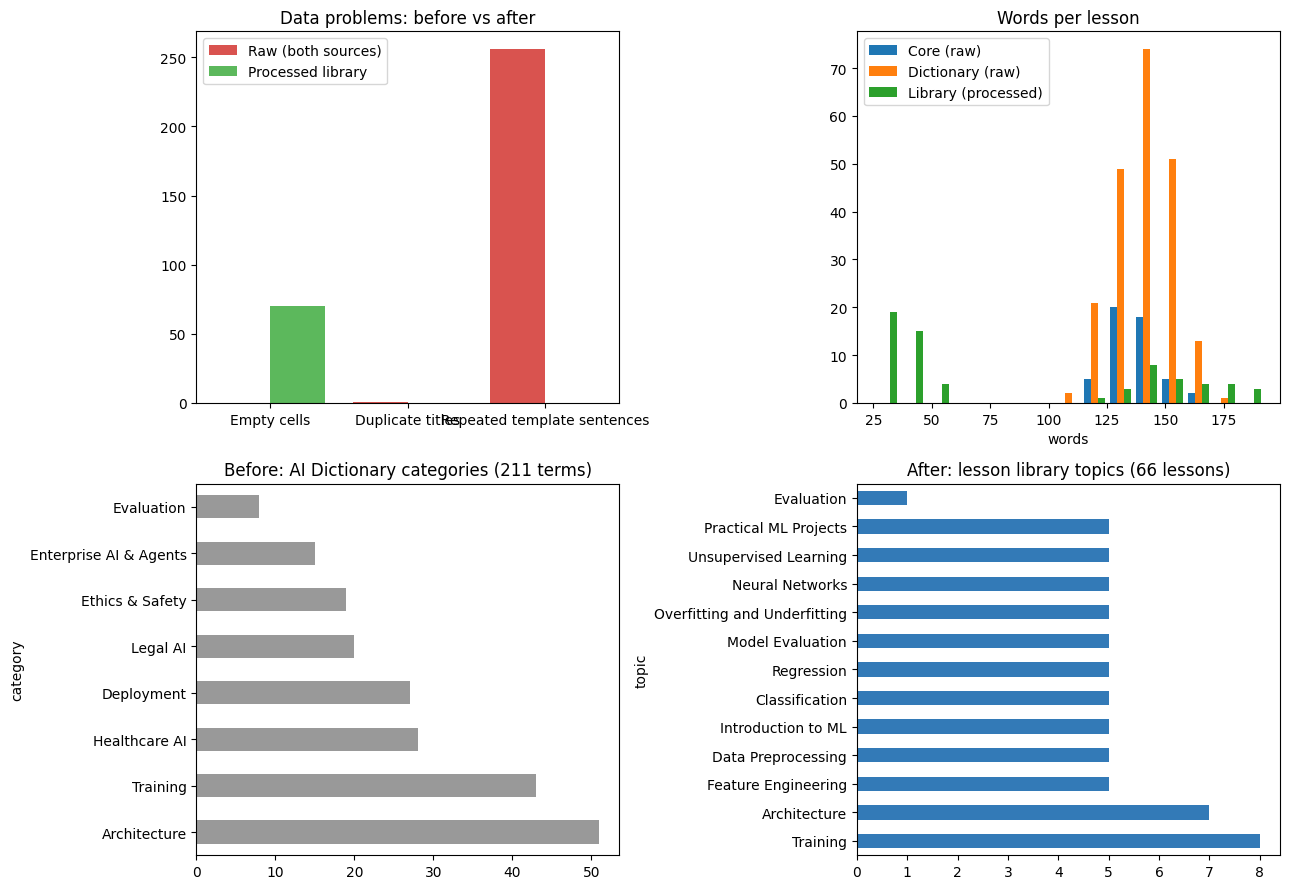


=== Sample of processed data that feeds the assistant ===


,lesson_id,title,topic,source,simple_explanation
54,55,Transfer Learning,Training,dictionary,Taking what an AI learned from one task and applying it to a different but related tas...
62,63,Hyperparameter,Training,dictionary,Settings you choose before training an AI — like how fast it learns or how many exampl...
0,1,What is Machine Learning?,Introduction to ML,core,ML learns patterns from data to make predictions.
45,46,ML Project Workflow,Practical ML Projects,core,"An ML project involves defining a problem, preparing data, training, and evaluating."
5,6,Data Cleaning,Data Preprocessing,core,"Cleaning fixes missing values, duplicates, and inconsistent records."


In [36]:
# CELL 3b — DATA QUALITY: BEFORE vs AFTER
import re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

fig_dir = f"{project_path}/figures"
os.makedirs(fig_dir, exist_ok=True)
SKIP_COLS = {"lesson_id", "url", "search_text", "source"}   # ids, links and the search field are not lesson text

def text_columns(df):
    """All text columns that hold lesson content."""
    return [c for c in df.columns if df[c].dtype == object and c not in SKIP_COLS]

def quality_report(df):
    """Measure 5 quality numbers for one table, and return words per lesson for the histogram."""
    cols = text_columns(df)
    title_col = "title" if "title" in df.columns else "term"

    # 1) empty cells: missing (NaN) or blank text
    empty = sum(int((df[c].isna() | (df[c].astype(str).str.strip() == "")).sum()) for c in cols)

    # 2) duplicate titles: the same lesson name appears twice
    dups = int(df[title_col].astype(str).str.lower().str.strip().duplicated().sum())

    # 3) template sentences: a sentence (4+ words) copied word-for-word into 3+ lessons
    seen = Counter()
    for _, row in df[cols].iterrows():
        sents = set()
        for v in row.dropna().astype(str):
            sents |= {s.strip() for s in re.split(r"(?<=[.!?])\s+", v) if len(s.split()) >= 4}
        seen.update(sents)
    template = sum(n for n in seen.values() if n >= 3)

    # 4) words per lesson: all lesson text joined together
    words = df[cols].fillna("").astype(str).agg(" ".join, axis=1).str.split().str.len()

    return {"Rows": len(df), "Empty cells": empty, "Duplicate titles": dups,
            "Repeated template sentences": template,
            "Avg words per lesson": round(words.mean(), 1)}, words

# ---- measure the raw sources and the processed library ----
q_core, w_core = quality_report(core)          # our 50 core ML lessons (raw)
q_dict, w_dict = quality_report(lessons_raw)   # AI Dictionary, 211 terms (raw)
q_lib,  w_lib  = quality_report(lib)           # processed library, 66 lessons

quality = pd.DataFrame({"Core lessons (raw)": q_core,
                        "AI Dictionary (raw)": q_dict,
                        "Lesson library (processed)": q_lib})
print("=== Data quality: before vs after ===")
display(quality)
quality.to_csv(f"{project_path}/data/processed/data_quality_before_after.csv")

# ---- 4 charts: before vs after ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# Chart 1: data problems, raw vs processed (grouped bars)
m = ["Empty cells", "Duplicate titles", "Repeated template sentences"]
before = [q_core[k] + q_dict[k] for k in m]
after  = [q_lib[k] for k in m]
x = np.arange(len(m))
ax[0, 0].bar(x - 0.2, before, 0.4, label="Raw (both sources)", color="#d9534f")
ax[0, 0].bar(x + 0.2, after,  0.4, label="Processed library", color="#5cb85c")
ax[0, 0].set_xticks(x, m)
ax[0, 0].set_title("Data problems: before vs after")
ax[0, 0].legend()

# Chart 2: words per lesson (histogram)
ax[0, 1].hist([w_core, w_dict, w_lib], bins=15,
              label=["Core (raw)", "Dictionary (raw)", "Library (processed)"])
ax[0, 1].set_title("Words per lesson")
ax[0, 1].set_xlabel("words")
ax[0, 1].legend()

# Chart 3: before, AI Dictionary categories
lessons_raw["category"].value_counts().plot.barh(ax=ax[1, 0], color="#999999")
ax[1, 0].set_title(f"Before: AI Dictionary categories ({len(lessons_raw)} terms)")

# Chart 4: after, lesson library topics
lib["topic"].value_counts().plot.barh(ax=ax[1, 1], color="#337ab7")
ax[1, 1].set_title(f"After: lesson library topics ({len(lib)} lessons)")

plt.tight_layout()
plt.savefig(f"{fig_dir}/data_quality_before_after.png", dpi=150)
plt.show()

# ---- sample of processed data that feeds the assistant ----
print("\n=== Sample of processed data that feeds the assistant ===")
display(lib[["lesson_id", "title", "topic", "source", "simple_explanation"]].sample(5, random_state=42))

## 4. Search: Hybrid Retrieval + Reranker

**Purpose:** Find the best lessons for a student's question.

**How it works (two-stage retrieval):**
1. **Stage 1, hybrid search:** TF-IDF (word matching, 30%) + MiniLM embeddings (meaning matching, 70%) find the top 5 lessons.
2. **Stage 2, reranker:** A cross-encoder (`cross-encoder/ms-marco-MiniLM-L-6-v2`) reads the question together with each of the 5 lessons.
3. **Score fusion:** Both scores are scaled to 0–1 and mixed 50/50 to pick the final top 3.

**Settings** (30/70 hybrid, top-5 pool, 50/50 fusion) are based on our earlier testing.

**Output:** The top 3 lessons for 3 demo questions.

In [37]:
# CODE CELL 4 — SEARCH: HYBRID RETRIEVAL + RERANKER
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer, CrossEncoder

texts = lib["search_text"].tolist()

# Stage 1: TF-IDF + embeddings
tfidf_vectorizer = TfidfVectorizer(stop_words="english", ngram_range=(1, 2))
tfidf_matrix = tfidf_vectorizer.fit_transform(texts)
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")
lesson_embeddings = embedding_model.encode(texts, convert_to_numpy=True, normalize_embeddings=True)

# Stage 2: reranker
reranker = CrossEncoder("cross-encoder/ms-marco-MiniLM-L-6-v2")

def minmax(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min()) if x.max() > x.min() else np.ones_like(x)

def hybrid_scores(question):
    tfidf = cosine_similarity(tfidf_vectorizer.transform([question]), tfidf_matrix).flatten()
    q_emb = embedding_model.encode([question], convert_to_numpy=True, normalize_embeddings=True)
    emb = cosine_similarity(q_emb, lesson_embeddings).flatten()
    return 0.30 * tfidf + 0.70 * emb

def search(question, top_n=3, pool=5, w_rerank=0.5):
    scores = hybrid_scores(question)
    top = np.argsort(-scores)[:pool]                                   # stage 1: top 5
    finalists = lib.iloc[top].copy()
    finalists["hybrid_score"] = scores[top]
    pairs = [(question, t) for t in finalists["search_text"]]
    finalists["rerank_score"] = reranker.predict(pairs)                # stage 2: careful judge
    finalists["final_score"] = ((1 - w_rerank) * minmax(finalists["hybrid_score"])
                                + w_rerank * minmax(finalists["rerank_score"]))
    return finalists.sort_values("final_score", ascending=False).head(top_n).reset_index(drop=True)

# Demo
for q in ["What is the difference between precision and recall?",
          "How does gradient descent help a model learn?",
          "Why does my model do well on training data but badly on new data?"]:
    print(f"\nQ: {q}")
    display(search(q)[["title", "topic", "final_score"]].round(3))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


Q: What is the difference between precision and recall?


,title,topic,final_score
0,F1 Score,Model Evaluation,1.000
1,Recall,Model Evaluation,0.869
2,Precision,Model Evaluation,0.833



Q: How does gradient descent help a model learn?


,title,topic,final_score
0,Gradient Descent,Training,1.000
1,Loss and Optimizers,Neural Networks,0.335
2,Backpropagation,Training,0.176



Q: Why does my model do well on training data but badly on new data?


,title,topic,final_score
0,Overfitting,Overfitting and Underfitting,1.000
1,Underfitting,Overfitting and Underfitting,0.411
2,Data Leakage,Overfitting and Underfitting,0.356


## 5. Answer Cards with Qwen (RAG: Retrieve, Then Generate)

**Purpose:** Turn the best lesson into a beginner-friendly answer card.

**How it works:**
1. `search()` finds the top 3 lessons for the question.
2. The #1 lesson's text is given to **Qwen2.5-1.5B-Instruct** as the only facts it may use.
3. Qwen writes a card with: simple explanation, real-life example, memory trick, and flashcard.
4. The other 2 lessons are shown as related lessons.

**Honesty rules:** Qwen must use only the lesson's facts, and must say so when the lesson doesn't answer the question. Greedy decoding (no random sampling) keeps answers steady and reduces invented details.

**Output:** Answer cards for 3 ML questions, plus 1 off-topic question to test the honesty rule.


In [38]:
# CODE CELL 5 — ANSWER CARDS WITH QWEN (RAG)
import re, time, torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import Markdown, display

assert torch.cuda.is_available(), "No GPU. Runtime → Change runtime type → T4 GPU, then re-run Cells 1–4."

llm_name = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(llm_name)
llm = AutoModelForCausalLM.from_pretrained(llm_name, torch_dtype=torch.float16, device_map="auto")

# Off-topic guard: "Sorry" only if BOTH scores are low (thresholds set from the dev questions)
HYBRID_MIN = 0.18
RERANK_MIN = -9.0
SORRY = "Sorry, StudyMate doesn't have a lesson on that yet. Try asking about a machine learning topic!"
SECTIONS = ["Simple explanation", "Real-life example", "Memory trick", "Flashcard"]

SYSTEM = (
    "You are StudyMate, a friendly machine learning tutor for beginners. "
    "Use ONLY the facts in the lessons provided. Use mainly the MAIN lesson; use the RELATED lesson "
    "only if the question also asks about it. Do not add facts or numbers that are not in the lessons. "
    "Write in simple English for an 8th-grade student, but keep correct technical terms.\n\n"
    "Answer in exactly this format, with every section included:\n"
    "**Simple explanation:** 2-3 sentences.\n"
    "**Real-life example:** 1-2 sentences from healthcare, retail, or everyday life.\n"
    "**Memory trick:** one short, catchy line about this topic.\n"
    "**Flashcard:** Q: one short question A: one short answer"
)

def is_off_topic(question, top3=None):
    """Returns (blocked?, best hybrid score, best reranker score)."""
    top3 = search(question) if top3 is None else top3
    h = float(hybrid_scores(question).max())
    r = float(top3["rerank_score"].max())
    return (h < HYBRID_MIN and r < RERANK_MIN), h, r

def lesson_context(row):
    parts = [f"Title: {row['title']}",
             f"Simple explanation: {row['simple_explanation']} {row['extra_simple']}".strip(),
             f"Details: {row['detailed_explanation']}"]
    if row["real_world_example"]:
        parts.append(f"Example: {row['real_world_example']}")
    return "\n".join(parts)

def tidy(card):
    """Put each section on its own line and the flashcard answer on a new line."""
    card = re.sub(r"\s*(\*\*(?:Real-life example|Memory trick|Flashcard):\*\*)", r"\n\n\1", card)
    card = re.sub(r"\s+A:", "  \nA:", card)
    return card.strip()

def answer(question):
    top3 = search(question)                                   # retrieve (Cell 4)
    blocked, h, r = is_off_topic(question, top3)              # off-topic guard
    if blocked:
        return {"question": question, "lesson": "—", "card": SORRY, "related": [],
                "hybrid_max": h, "rerank_max": r, "missing": []}

    main, related = top3.iloc[0], top3.iloc[1]
    user_msg = (f"Student question: {question}\n\nMAIN lesson:\n{lesson_context(main)}"
                f"\n\nRELATED lesson:\n{lesson_context(related)}")
    messages = [{"role": "system", "content": SYSTEM}, {"role": "user", "content": user_msg}]
    prompt = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(prompt, return_tensors="pt").to(llm.device)
    with torch.no_grad():                                     # generate
        out = llm.generate(**inputs, max_new_tokens=350, do_sample=False, repetition_penalty=1.1)
    card = tidy(tokenizer.decode(out[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True))
    missing = [s for s in SECTIONS if f"**{s}:**" not in card]
    return {"question": question, "lesson": main["title"], "card": card,
            "related": top3["title"].tolist()[1:], "hybrid_max": h, "rerank_max": r, "missing": missing}

def show_answer(r):
    warn = f"\n\n⚠️ **Missing:** {', '.join(r['missing'])}" if r["missing"] else ""
    rel = f"\n\n**🔗 Related lessons:** {', '.join(r['related'])}" if r["related"] else ""
    display(Markdown(f"### ❓ {r['question']}\n**📘 Lesson used:** {r['lesson']}\n\n{r['card']}{warn}{rel}"))

# Demo: 3 ML questions + 1 off-topic question
for q in ["What is the difference between precision and recall?",
          "How does gradient descent help a model learn?",
          "How do I turn a column of city names into numbers?",
          "What is the capital of France?"]:
    start = time.time()
    r = answer(q)
    show_answer(r)
    print(f"Hybrid max: {r['hybrid_max']:.3f} | Reranker max: {r['rerank_max']:.2f} | "
          f"⏱ {time.time() - start:.1f} seconds\n")

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

### ❓ What is the difference between precision and recall?
**📘 Lesson used:** F1 Score

**Simple explanation:** Precision is how many true positive results there are compared to all positive results given by the test, while recall is how many of the actual positives were found by the test.

**Real-life example:** In a medical test for a disease, high precision means few patients who don't have the disease are incorrectly diagnosed as having it, whereas high recall means most people who actually have the disease are correctly identified.

**Memory trick:** "Precision checks if you caught the right bad guys, recall counts all the bad guys."

**Flashcard:** Q: What does precision measure?  
A: How many true positive results there are compared to all positive results given by the test.

**🔗 Related lessons:** Recall, Precision

Hybrid max: 0.473 | Reranker max: 3.85 | ⏱ 17.2 seconds



### ❓ How does gradient descent help a model learn?
**📘 Lesson used:** Gradient Descent

**Simple explanation:** Gradient Descent helps a model learn by making tiny changes to its settings over many tries, just like a ball rolls down a hill to reach the bottom. It keeps trying different paths until it finds the best way to make predictions without making too many mistakes.

**Real-life example:** In healthcare, doctors might tweak a medical diagnosis tool using Gradient Descent to improve accuracy. They start with initial guesses and then test them against patient data, adjusting the tool slightly each time to see if it gets better at predicting outcomes.

**Memory trick:** "Gradient Descent rolls down hills to win!"

**Flashcard:** Q: What does Gradient Descent do?  
A: It makes tiny changes to model settings to reduce errors.

**🔗 Related lessons:** Loss and Optimizers, Backpropagation

Hybrid max: 0.613 | Reranker max: 7.11 | ⏱ 19.2 seconds



### ❓ How do I turn a column of city names into numbers?
**📘 Lesson used:** Embedding

**Simple explanation:** To turn a column of city names into numbers, we can create a special dictionary where each unique city name gets a different number. This way, instead of having text, we have numbers that represent those cities.

**Real-life example:** In a retail store, they might use city names to track customer locations. By turning these city names into numbers, they can easily sort or group customers based on their location without needing to understand the actual city names.

**Memory trick:** "City Names Turn Into Numbers, Just Like Red Blue Green!"

**Flashcard:**
Q: How can you convert city names into numbers?  
A: Create a dictionary where each city name maps to a unique number.

**🔗 Related lessons:** One-Hot Encoding, Text Features

Hybrid max: 0.213 | Reranker max: -10.47 | ⏱ 14.8 seconds



### ❓ What is the capital of France?
**📘 Lesson used:** —

Sorry, StudyMate doesn't have a lesson on that yet. Try asking about a machine learning topic!

Hybrid max: 0.079 | Reranker max: -11.09 | ⏱ 0.1 seconds



## 6. Dev Questions (for Improving StudyMate)

**Purpose:** A labeled practice set to compare search options and check the off-topic guard.

**What's in it:**
- 46 beginner questions: one for each of the 16 dictionary lessons and 30 of the core lessons, written in beginner wording (not copied from the lessons).
- 4 off-topic questions labeled `NONE`, to test whether StudyMate correctly says "Sorry."
- `also_acceptable` lists a second lesson when it is also a fair answer.

**Note:** These questions were drafted with AI assistance and checked by our team. They are used only for development. The final test uses real questions from Data Science Stack Exchange.

**Output:** `dev_questions.csv` saved to Drive, plus a check that every label matches a real lesson title.

In [39]:
# CODE CELL 6 — DEV QUESTIONS
dev_rows = [
    # Dictionary lessons
    ("What makes deep learning different from regular machine learning?", "Deep Learning", "Neural Network Basics"),
    ("Which method lowers a model's error by taking small steps in the direction that improves it?", "Gradient Descent", ""),
    ("What happens if my model takes steps that are too big while it trains?", "Learning Rate", "Gradient Descent"),
    ("How does a neural network figure out which weights caused its mistake?", "Backpropagation", ""),
    ("Can I reuse a model trained on one task to help with a new task?", "Transfer Learning", "Fine-tuning"),
    ("How do I adjust a pretrained model a little bit using my own small dataset?", "Fine-tuning", "Transfer Learning"),
    ("How can a model learn without human labels by hiding parts of the data and guessing them?", "Self-Supervised Learning", "Unsupervised Learning"),
    ("How does a classifier turn its raw scores into probabilities that add up to 1?", "Softmax Function", "Activation Functions"),
    ("What neural network design reads a whole sentence at once instead of word by word?", "Transformer", "Attention Mechanism"),
    ("How does a model decide which words in a sentence matter most to each other?", "Attention Mechanism", "Transformer"),
    ("How can words be turned into lists of numbers so similar words end up close together?", "Embedding", ""),
    ("Why does a language model split text into small pieces before reading it?", "Token", ""),
    ("What are the settings I choose before training, like the number of layers?", "Hyperparameter", "Model Improvement"),
    ("How can I make more training images by flipping or rotating the ones I already have?", "Data Augmentation", ""),
    ("Why does a chatbot sometimes make up facts that sound true?", "Hallucination", ""),
    ("What kind of AI creates new text, images, or music?", "Generative AI", ""),
    # Core lessons
    ("What does it mean when we say a computer learns from data?", "What is Machine Learning?", ""),
    ("Is every AI system a machine learning system?", "AI vs ML", ""),
    ("What kind of learning uses examples that already have the correct answers?", "Supervised Learning", ""),
    ("How can a model find patterns when the data has no answers at all?", "Unsupervised Learning", "Clustering"),
    ("How can a game-playing AI learn from rewards and penalties?", "Reinforcement Learning", ""),
    ("How should I fix typos and duplicate rows before training?", "Data Cleaning", "Missing Values"),
    ("What should I do with empty cells in my dataset?", "Missing Values", "Data Cleaning"),
    ("Why should I put my columns on similar number ranges?", "Feature Scaling", ""),
    ("Why do we keep some data aside and never train on it?", "Train-Test Split", ""),
    ("What should I do with values that are far away from the rest?", "Outliers", ""),
    ("How do I turn a column of city names into numbers?", "One-Hot Encoding", ""),
    ("Which model fits a straight line to predict a price?", "Linear Regression", "Building a Regression Model"),
    ("Which simple model predicts the chance of a yes or no answer?", "Logistic Regression", ""),
    ("Which model asks a series of yes/no questions to reach a decision?", "Decision Trees", ""),
    ("How can a model classify something by looking at its closest examples?", "K-Nearest Neighbors", ""),
    ("What do we call many decision trees voting together?", "Random Forest", ""),
    ("What share of all predictions did my model get right?", "Accuracy", ""),
    ("When my model says 'spam', how often is it really spam?", "Precision", ""),
    ("How many of the real fraud cases did my model catch?", "Recall", ""),
    ("Which single score balances precision and recall?", "F1 Score", ""),
    ("How can I see all four kinds of right and wrong predictions in one table?", "Confusion Matrix", ""),
    ("My model memorized the training data. What is this problem called?", "Overfitting", ""),
    ("My model is too simple and performs badly everywhere. What's wrong?", "Underfitting", ""),
    ("How can I test my model on several different splits of the data?", "Cross-Validation", ""),
    ("What technique keeps model weights small to reduce overfitting?", "Regularization", "Overfitting"),
    ("Why is my test score unrealistically high when test information slipped into training?", "Data Leakage", ""),
    ("Which algorithm groups data into K clusters using center points?", "K-Means", "Clustering"),
    ("How can I reduce 50 columns to just a few while keeping the important information?", "PCA", ""),
    ("Why do neural networks use functions like ReLU?", "Activation Functions", ""),
    ("What is one full pass through all the training data called?", "Epochs and Batches", ""),
    # Off-topic (StudyMate should say "Sorry")
    ("How do I bake chocolate chip cookies?", "NONE", ""),
    ("Who won the last soccer World Cup?", "NONE", ""),
    ("What is a good name for a pet cat?", "NONE", ""),
    ("How do I fix a flat bike tire?", "NONE", ""),
]

dev = pd.DataFrame(dev_rows, columns=["question", "expected_lesson", "also_acceptable"])
dev.insert(0, "question_id", [f"D{i+1:02d}" for i in range(len(dev))])

# Check: every label must match a real lesson title
titles = set(lib["title"])
labels = set(dev["expected_lesson"]) | set(dev["also_acceptable"])
unknown = labels - titles - {"NONE", ""}
print("Unknown lesson labels:", unknown if unknown else "none")

dev.to_csv(os.path.join(project_path, "data", "evaluation", "dev_questions.csv"), index=False)
print(f"Saved {len(dev)} dev questions: {(dev['expected_lesson'] != 'NONE').sum()} ML + "
      f"{(dev['expected_lesson'] == 'NONE').sum()} off-topic")

Unknown lesson labels: none
Saved 50 dev questions: 46 ML + 4 off-topic


## 7. Compare Search Options on the Dev Questions

**Purpose:** Decide which search design StudyMate should use, and check the off-topic guard.

**Options compared (on the 46 ML dev questions):**
- **A. Hybrid only:** TF-IDF (30%) + embeddings (70%) → top 3.
- **B. Two-stage:** hybrid top 5 → cross-encoder reranker → 50/50 score fusion → top 3.
- **C. Reranker on all lessons:** the cross-encoder scores all 66 lessons → top 3.

**Decision rules (set before running):** Start with the simplest option (A). Use B only if it beats A by at least 2 questions on Top-1. Use C only if it beats the chosen option by at least 2 questions.

**Guard check:** Off-topic questions should score below the threshold (0), and ML questions above it.

**Output:** Top-1, Recall@3, lenient Top-1, and average time for each option; the decision; the guard scores; and the remaining mistakes.

In [40]:
# CODE CELL 7 — COMPARE SEARCH OPTIONS ON THE DEV QUESTIONS
def top3_hybrid(q):
    s = hybrid_scores(q)
    return lib["title"].iloc[np.argsort(-s)[:3]].tolist()

def top3_two_stage(q):
    return search(q)["title"].tolist()

def top3_rerank_all(q):
    s = reranker.predict([(q, t) for t in lib["search_text"]])
    return lib["title"].iloc[np.argsort(-s)[:3]].tolist()

options = {"A. Hybrid only": top3_hybrid,
           "B. Two-stage": top3_two_stage,
           "C. Reranker on all": top3_rerank_all}

ml_dev = dev[dev["expected_lesson"] != "NONE"]
rows = []
for name, fn in options.items():
    for _, q in ml_dev.iterrows():
        start = time.time()
        top3 = fn(q["question"])
        ok = [q["expected_lesson"]] + [a for a in [q["also_acceptable"]] if a]
        rows.append({"Option": name, "Question": q["question"], "Expected": q["expected_lesson"],
                     "Predicted": top3[0], "Top-1": int(top3[0] == q["expected_lesson"]),
                     "Recall@3": int(q["expected_lesson"] in top3),
                     "Top-1 (lenient)": int(top3[0] in ok), "Seconds": time.time() - start})

results = pd.DataFrame(rows)
summary = results.groupby("Option").agg(**{
    "Top-1 %": ("Top-1", lambda x: round(x.mean() * 100, 1)),
    "Recall@3 %": ("Recall@3", lambda x: round(x.mean() * 100, 1)),
    "Top-1 lenient %": ("Top-1 (lenient)", lambda x: round(x.mean() * 100, 1)),
    "Top-1 correct": ("Top-1", "sum"),
    "Avg seconds": ("Seconds", lambda x: round(x.mean(), 2))})
print(f"=== Dev evaluation: {len(ml_dev)} ML questions ===")
display(summary)

# Decision rules (set before running)
n = summary["Top-1 correct"]
choice = "A. Hybrid only"
if n["B. Two-stage"] - n[choice] >= 2:
    choice = "B. Two-stage"
if n["C. Reranker on all"] - n[choice] >= 2:
    choice = "C. Reranker on all"
print(f"\nDecision: {choice}")

# Off-topic guard check (same rule as answer() in Cell 5)
guard = pd.DataFrame([{"Question": q["question"], "Off-topic?": q["expected_lesson"] == "NONE",
                       "Blocked?": is_off_topic(q["question"])[0]} for _, q in dev.iterrows()])
off, on = guard[guard["Off-topic?"]], guard[~guard["Off-topic?"]]
print(f"\nGuard: off-topic blocked {off['Blocked?'].sum()} of {len(off)} | "
      f"ML questions wrongly blocked {on['Blocked?'].sum()} of {len(on)}")

print(f"\nRemaining mistakes for {choice}:")
display(results[(results["Option"] == choice) & (results["Top-1"] == 0)]
        [["Question", "Expected", "Predicted", "Recall@3", "Top-1 (lenient)"]])

results.to_csv(os.path.join(project_path, "data", "evaluation", "dev_option_results.csv"), index=False)

=== Dev evaluation: 46 ML questions ===


,Top-1 %,Recall@3 %,Top-1 lenient %,Top-1 correct,Avg seconds
Option,,,,,
A. Hybrid only,65.2,95.7,67.4,30,0.05
B. Two-stage,71.7,95.7,76.1,33,0.06
C. Reranker on all,71.7,84.8,76.1,33,0.15



Decision: B. Two-stage

Guard: off-topic blocked 4 of 4 | ML questions wrongly blocked 0 of 46

Remaining mistakes for B. Two-stage:


,Question,Expected,Predicted,Recall@3,Top-1 (lenient)
49,How does a neural network figure out which weights caused its mistake?,Backpropagation,Neurons and Weights,1,0
52,How can a model learn without human labels by hiding parts of the data and guessing them?,Self-Supervised Learning,Unsupervised Learning,1,1
54,What neural network design reads a whole sentence at once instead of word by word?,Transformer,Token,1,0
63,Is every AI system a machine learning system?,AI vs ML,What is Machine Learning?,1,0
68,What should I do with empty cells in my dataset?,Missing Values,Data Cleaning,1,1
69,Why should I put my columns on similar number ranges?,Feature Scaling,Embedding,1,0
71,What should I do with values that are far away from the rest?,Outliers,Missing Values,1,0
72,How do I turn a column of city names into numbers?,One-Hot Encoding,Embedding,1,0
73,Which model fits a straight line to predict a price?,Linear Regression,R-Squared,1,0
74,Which simple model predicts the chance of a yes or no answer?,Logistic Regression,Accuracy,0,0


## Step 7b: Feature importance — which signals find the right lesson?
**Our engineered features:**
1. **`search_text`**: one combined text field per lesson (title + topic + explanations + related terms)
2. **TF-IDF score**: word matching (do the question and the lesson share exact words?)
3. **Embedding score**: meaning matching (all-MiniLM-L6-v2, 384 numbers per text)
4. **Hybrid score**: 30% words + 70% meaning (Judge 1)
5. **Reranker score**: the cross-encoder reads the question and the lesson together (Judge 2)
6. **`final_score`**: 50% hybrid + 50% reranker, each scaled 0–1 (min-max normalization)

**How we measure importance:** we use each signal alone and then combined on the 46 dev ML questions, and check
how often the right lesson comes first (Top-1) or lands in the top 3 (Recall@3). We also test different weights.
**Note:** this is analysis only. No settings are changed, because the final exam (Cell 10) is already done.

ML dev questions: 46
Rebuilt hybrid matches Cell 4: True

=== Feature importance: each signal alone vs combined ===


,Top-1 %,Recall@3 %
TF-IDF only (words),54.3,69.6
Embedding only (meaning),65.2,89.1
Hybrid 30/70 (Judge 1),65.2,95.7
Two-stage (final_score),71.7,95.7


TF-IDF weight test (Top-1 %):   {0: 65.2, 0.3: 65.2, 0.5: 69.6, 0.7: 63.0, 1.0: 54.3}
Reranker weight test (Top-1 %): {0: 65.2, 0.25: 67.4, 0.5: 71.7, 0.75: 76.1, 1.0: 71.7}

Normalization example:


,title,rerank_score,scaled_0_to_1
0,F1 Score,3.852513,1.000
1,Recall,0.997756,0.809
2,Precision,1.128170,0.817
3,Accuracy,-5.635601,0.364
4,Confusion Matrix,-11.072486,0.000


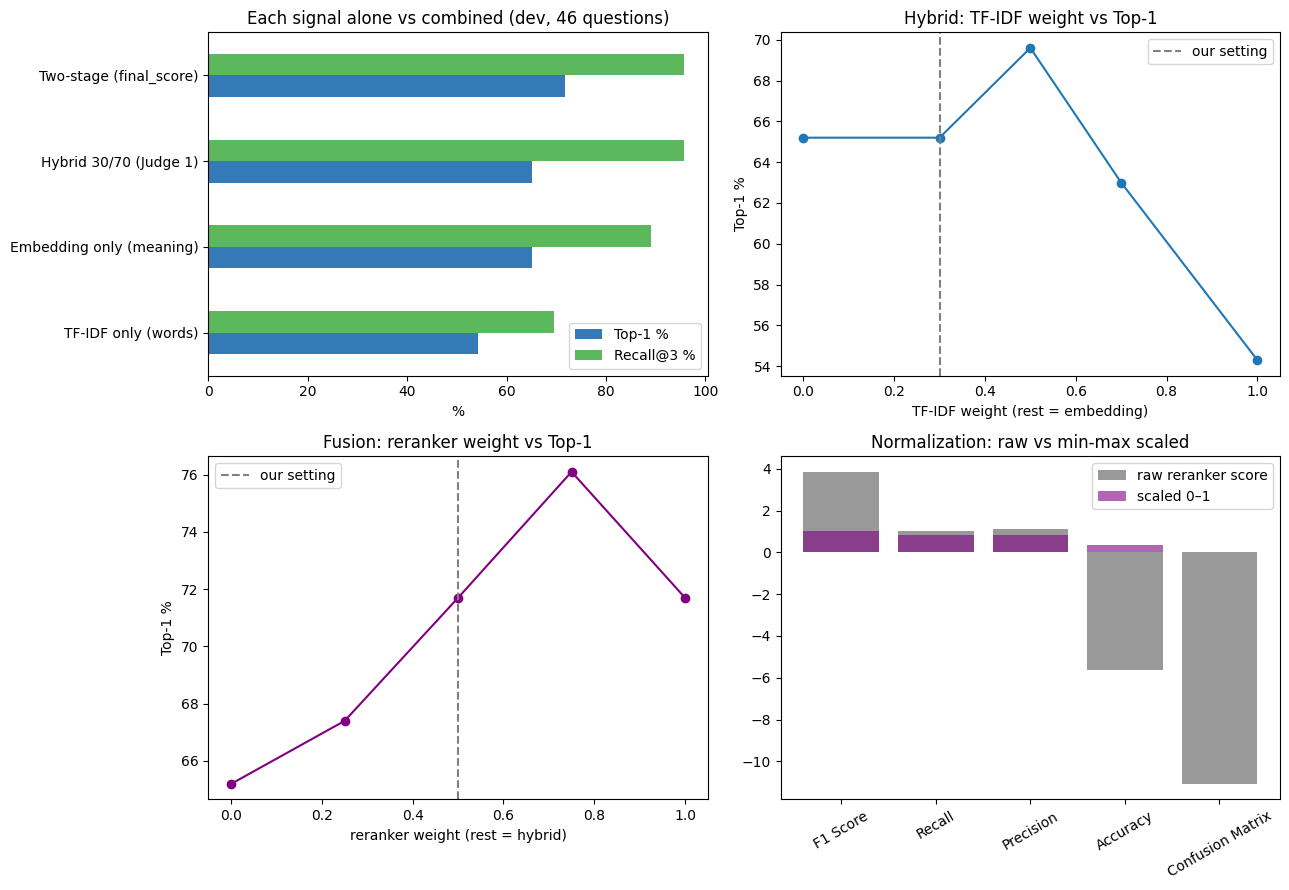

In [41]:
# CELL 7b — FEATURE IMPORTANCE (analysis only, dev questions)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

fig_dir = f"{project_path}/figures"

# ---- load the 46 dev ML questions (skip the 4 off-topic ones) ----
dev = pd.read_csv(f"{project_path}/data/evaluation/dev_questions.csv")
ml_dev = dev[dev["expected_lesson"] != "NONE"].reset_index(drop=True)
print("ML dev questions:", len(ml_dev))
titles = lib["title"].values

# ---- features 2 and 3: TF-IDF and embedding scores (same as Cell 4) ----
cache = {}
def tf_em(q):
    """Return (TF-IDF scores, embedding scores) for one question against all 66 lessons."""
    if q not in cache:
        tf = cosine_similarity(tfidf_vectorizer.transform([q]), tfidf_matrix).flatten()
        q_emb = embedding_model.encode([q], convert_to_numpy=True, normalize_embeddings=True)
        em = cosine_similarity(q_emb, lesson_embeddings).flatten()
        cache[q] = (tf, em)
    return cache[q]

# safety check: 0.3 × TF-IDF + 0.7 × embedding must equal the real hybrid from Cell 4
q0 = ml_dev["question"][0]
tf0, em0 = tf_em(q0)
print("Rebuilt hybrid matches Cell 4:", np.allclose(0.3 * tf0 + 0.7 * em0, hybrid_scores(q0), atol=1e-6))

# ---- grading helper: Top-1 % and Recall@3 % ----
top3 = lambda s: list(titles[np.argsort(-np.asarray(s))[:3]])
def grade(rank_fn):
    hits1 = hits3 = 0
    for q, exp in zip(ml_dev["question"], ml_dev["expected_lesson"]):
        t3 = rank_fn(q)
        hits1 += t3[0] == exp
        hits3 += exp in t3
    n = len(ml_dev)
    return round(100 * hits1 / n, 1), round(100 * hits3 / n, 1)

# ---- A) each signal alone vs combined ----
ablation = pd.DataFrame({
    "TF-IDF only (words)":      grade(lambda q: top3(tf_em(q)[0])),
    "Embedding only (meaning)": grade(lambda q: top3(tf_em(q)[1])),
    "Hybrid 30/70 (Judge 1)":   grade(lambda q: top3(hybrid_scores(q))),
    "Two-stage (final_score)":  grade(lambda q: list(search(q)["title"])),
}, index=["Top-1 %", "Recall@3 %"]).T
print("\n=== Feature importance: each signal alone vs combined ===")
display(ablation)

# ---- B) weight tests: how much say should each signal get? ----
tf_w = [0, 0.3, 0.5, 0.7, 1.0]          # TF-IDF weight inside hybrid (we use 0.3)
tf_sweep = [grade(lambda q, a=a: top3(a * tf_em(q)[0] + (1 - a) * tf_em(q)[1]))[0] for a in tf_w]
rr_w = [0, 0.25, 0.5, 0.75, 1.0]        # reranker weight in fusion (we use 0.5)
rr_sweep = [grade(lambda q, w=w: list(search(q, w_rerank=w)["title"]))[0] for w in rr_w]
print("TF-IDF weight test (Top-1 %):  ", dict(zip(tf_w, tf_sweep)))
print("Reranker weight test (Top-1 %):", dict(zip(rr_w, rr_sweep)))

# ---- C) normalization example: raw reranker scores vs 0–1 scaled ----
ex = search("What is the difference between precision and recall?", top_n=5)
print("\nNormalization example:")
display(ex[["title", "rerank_score"]].assign(scaled_0_to_1=minmax(ex["rerank_score"].values).round(3)))

# ---- 4 charts ----
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

ablation.plot.barh(ax=ax[0, 0], color=["#337ab7", "#5cb85c"])
ax[0, 0].set_title("Each signal alone vs combined (dev, 46 questions)"); ax[0, 0].set_xlabel("%")

ax[0, 1].plot(tf_w, tf_sweep, "o-")
ax[0, 1].axvline(0.3, ls="--", c="gray", label="our setting")
ax[0, 1].set_title("Hybrid: TF-IDF weight vs Top-1")
ax[0, 1].set_xlabel("TF-IDF weight (rest = embedding)"); ax[0, 1].set_ylabel("Top-1 %"); ax[0, 1].legend()

ax[1, 0].plot(rr_w, rr_sweep, "o-", c="purple")
ax[1, 0].axvline(0.5, ls="--", c="gray", label="our setting")
ax[1, 0].set_title("Fusion: reranker weight vs Top-1")
ax[1, 0].set_xlabel("reranker weight (rest = hybrid)"); ax[1, 0].set_ylabel("Top-1 %"); ax[1, 0].legend()

ax[1, 1].bar(ex["title"], ex["rerank_score"], color="#999999", label="raw reranker score")
ax[1, 1].bar(ex["title"], minmax(ex["rerank_score"].values), color="purple", alpha=0.6, label="scaled 0–1")
ax[1, 1].set_title("Normalization: raw vs min-max scaled")
ax[1, 1].tick_params(axis="x", rotation=30); ax[1, 1].legend()

plt.tight_layout()
plt.savefig(f"{fig_dir}/feature_importance.png", dpi=150)
plt.show()
ablation.to_csv(f"{project_path}/data/evaluation/feature_importance.csv")


## 8. Final Test, Part 1: Pick Real Questions for Labeling

**Purpose:** Build a fair final test from real questions asked by people on Data Science Stack Exchange.

**Data source:** Hugging Face `mgp123/datascience-stackexchange-with-similar-questions` (Data Science Stack Exchange posts, CC BY-SA license).

**How questions are picked:**
1. Keep question titles about ML topics (by tag), phrased as questions, 5–20 words long.
2. Remove coding and tool questions (Python errors, libraries, installation), since StudyMate teaches concepts.
3. Take a random sample of 120 (fixed seed, so the sample doesn't depend on StudyMate's performance).
4. For each question, list 5 possible lessons **in alphabetical order** (not ranked), so the labeler isn't pushed toward StudyMate's first choice.

**Labeling:** Our team labels each question with the correct lesson, or SKIP if no lesson fits. About 30 labeled questions are kept for the final test.

**Output:** `holdout_to_label.csv` and `lesson_titles.csv` in the evaluation folder.

In [42]:
# CODE CELL 8 — FINAL TEST, PART 1: PICK REAL QUESTIONS FOR LABELING
import re
from datasets import load_dataset

se = load_dataset("mgp123/datascience-stackexchange-with-similar-questions", split="train").to_pandas()
print("Stack Exchange rows:", len(se))

def tag_list(t):
    if t is None:
        return []
    return re.findall(r"[\w\-\.]+", t) if isinstance(t, str) else list(t)

ml_tags = {"machine-learning", "deep-learning", "neural-network", "classification", "regression",
           "clustering", "model-evaluations", "overfitting", "cross-validation", "nlp",
           "feature-selection", "feature-engineering", "preprocessing", "data-cleaning", "pca",
           "decision-trees", "random-forest", "logistic-regression", "linear-regression", "k-means",
           "gradient-descent", "transformer", "attention-mechanism", "word-embeddings",
           "transfer-learning", "hyperparameter-tuning", "accuracy", "metric", "confusion-matrix",
           "supervised-learning", "unsupervised-learning", "reinforcement-learning",
           "activation-function", "backpropagation", "dropout", "data-augmentation",
           "one-hot-encoding", "missing-data", "outlier", "generative-models", "bert", "tokenization"}
code_words = ["error", "keras", "tensorflow", "pytorch", "sklearn", "scikit", "pandas", "numpy",
              "python", " r ", "install", "code", "gpu", "spark", "sql", "excel", "matlab", "java"]
question_starts = ("what", "why", "how", "when", "which", "is ", "are ", "can ", "does ", "do ", "should ")

se["title"] = se["Title"].fillna("").str.strip()
words = se["title"].str.split().str.len()
is_ml = se["Tags"].apply(lambda t: bool(set(tag_list(t)) & ml_tags))
is_question = se["title"].str.lower().str.startswith(question_starts) | se["title"].str.endswith("?")
is_concept = ~se["title"].str.lower().apply(lambda s: any(w in f" {s} " for w in code_words))

pool = se[is_ml & is_question & is_concept & words.between(5, 20)].drop_duplicates("title")
print("Questions after filtering:", len(pool))

cand = pool.sample(n=min(120, len(pool)), random_state=42).reset_index(drop=True)

def five_suggestions(q):
    top5 = np.argsort(-hybrid_scores(q))[:5]
    return sorted(lib["title"].iloc[top5].tolist())      # alphabetical, not ranked

sheet = pd.DataFrame({"question_id": [f"H{i+1:03d}" for i in range(len(cand))],
                      "question": cand["title"]})
sugg = sheet["question"].apply(five_suggestions)
for k in range(5):
    sheet[f"suggestion_{k+1}"] = sugg.str[k]
sheet["expected_lesson"] = ""
sheet["also_acceptable"] = ""

eval_dir = os.path.join(project_path, "data", "evaluation")
sheet.to_csv(os.path.join(eval_dir, "holdout_to_label.csv"), index=False)
lib[["title", "topic"]].to_csv(os.path.join(eval_dir, "lesson_titles.csv"), index=False)
print(f"Saved {len(sheet)} questions to label, plus the list of {len(lib)} lesson titles.")
display(sheet.head(5))

Stack Exchange rows: 9172
Questions after filtering: 3188
Saved 120 questions to label, plus the list of 66 lesson titles.


,question_id,question,suggestion_1,suggestion_2,suggestion_3,suggestion_4,suggestion_5,expected_lesson,also_acceptable
0,H001,Gradient descent multidimensional linear regression - does learning rate affects concu...,Gradient Descent,Learning Rate,Linear Regression,Regularization,Transfer Learning,,
1,H002,Why is it bad to use the same test dataset over and over again?,Cross-Validation,Data Cleaning,Data Leakage,Overfitting,Train-Test Split,,
2,H003,Why use Gradient Descent when Gradient just solve the problem? (With Neural Nets),Activation Functions,Backpropagation,Gradient Descent,Loss and Optimizers,Neurons and Weights,,
3,H004,Ad click prediction: what are the negative examples?,Confusion Matrix,Features and Targets,R-Squared,Supervised Learning,Unsupervised Learning,,
4,H005,What is the significance of underflow during parameter update using stochastic gradien...,Backpropagation,Data Leakage,Gradient Descent,Learning Rate,Loss and Optimizers,,


## 9. Final Test, Part 2: Load and Check the Labels

**Purpose:** Load the labeled real questions, catch typos in lesson names, and show every question next to its label for a final review before the exam.

**Labeling:** Each of the 120 sampled questions was labeled with the lesson that answers it, or SKIP if no lesson really answers it (too advanced, too specific, or about code). Labels were drafted with AI assistance and reviewed and corrected by our team.

**Output:** Counts of labeled and skipped questions, any unknown lesson names, and the full list of labeled questions.

In [43]:
# CODE CELL 9 — FINAL TEST, PART 2: LOAD AND CHECK THE LABELS
eval_dir = os.path.join(project_path, "data", "evaluation")
labeled = pd.read_csv(os.path.join(eval_dir, "holdout_labeled.csv")).fillna("")
labeled["expected_lesson"] = labeled["expected_lesson"].astype(str).str.strip()
labeled["also_acceptable"] = labeled["also_acceptable"].astype(str).str.strip()

# Fix the one typo found in review, and save the corrected file
labeled["also_acceptable"] = labeled["also_acceptable"].str.replace("Embeeding", "Embedding")
labeled.to_csv(os.path.join(eval_dir, "holdout_labeled.csv"), index=False)

done = labeled[labeled["expected_lesson"] != ""]
skipped = done[done["expected_lesson"].str.upper() == "SKIP"]
holdout = done[done["expected_lesson"].str.upper() != "SKIP"].copy()

# Check: every lesson name must match a real title (catches typos)
titles = set(lib["title"])
backups = {b.strip() for s in holdout["also_acceptable"] for b in s.split(";") if b.strip()}
unknown = (set(holdout["expected_lesson"]) | backups) - titles

print(f"Reviewed: {len(done)} | Labeled: {len(holdout)} | SKIP: {len(skipped)} "
      f"({len(skipped) / len(done):.0%} of real questions are outside the library)")
print("Unknown lesson names (typos):", unknown if unknown else "none")

pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 80)
display(holdout[["question_id", "question", "expected_lesson", "also_acceptable"]])

Reviewed: 120 | Labeled: 53 | SKIP: 67 (56% of real questions are outside the library)
Unknown lesson names (typos): none


,question_id,question,expected_lesson,also_acceptable
0,H001,Gradient descent multidimensional linear regression - does learning rate affects concu...,Learning Rate,Gradient Descent
1,H002,Why is it bad to use the same test dataset over and over again?,Data Leakage,Overfitting
2,H003,Why use Gradient Descent when Gradient just solve the problem? (With Neural Nets),Gradient Descent,Loss and Optimizers
3,H004,Ad click prediction: what are the negative examples?,Features and Targets,
5,H006,What are differentiable modules used in deep learning,Activation Functions,Softmax Function
6,H007,What does discriminator of a GAN should do?,Generative AI,
7,H008,Is converting a numerical target to binary helpful?,Classification Basics,Features and Targets
9,H010,Why/When should I use VGG16 to do fine-tuning?,Fine-tuning,Transfer Learning
12,H013,Output a word instead of a vector after word embedding?,Embedding,Token
13,H014,How is the cross-product transformation defined for binary features?,Derived Features,


## 10. Final Exam on Real Questions (Run Once)

**Purpose:** Measure StudyMate on 53 real Data Science Stack Exchange questions it was never tuned on.

**What is tested:**
- **B. Two-stage search** (our final design) and **A. Hybrid only** (for comparison).
- **Off-topic guard:** how many real ML questions are wrongly blocked (same rule as Cell 5: block only if hybrid max < 0.18 AND reranker max < −9).

**Rule:** This cell is run once. No settings are changed after seeing these results; we only report them.

**Output:** Top-1, Recall@3, and lenient Top-1 for each option, the guard result, the remaining mistakes, and a saved results file.

In [44]:
# CODE CELL 10 — FINAL EXAM ON REAL QUESTIONS (RUN ONCE)
HYBRID_MIN, RERANK_MIN = 0.18, -9.0                      # same guard rule as Cell 5

def top3_hybrid(q):
    return lib["title"].iloc[np.argsort(-hybrid_scores(q))[:3]].tolist()

rows, blocked = [], 0
for _, q in holdout.iterrows():
    exp = q["expected_lesson"]
    ok = [exp] + [b.strip() for b in q["also_acceptable"].split(";") if b.strip()]
    two = search(q["question"])                          # B. two-stage
    hyb3 = top3_hybrid(q["question"])                    # A. hybrid only
    blocked += int(hybrid_scores(q["question"]).max() < HYBRID_MIN and two["rerank_score"].max() < RERANK_MIN)
    for name, top3 in [("A. Hybrid only", hyb3), ("B. Two-stage", two["title"].tolist())]:
        rows.append({"Option": name, "question_id": q["question_id"], "Question": q["question"],
                     "Expected": exp, "Predicted": top3[0],
                     "Top-1": int(top3[0] == exp), "Recall@3": int(exp in top3),
                     "Top-1 (lenient)": int(top3[0] in ok)})

final = pd.DataFrame(rows)
summary = final.groupby("Option").agg(**{
    "Top-1 %": ("Top-1", lambda x: round(x.mean() * 100, 1)),
    "Recall@3 %": ("Recall@3", lambda x: round(x.mean() * 100, 1)),
    "Top-1 lenient %": ("Top-1 (lenient)", lambda x: round(x.mean() * 100, 1)),
    "Top-1 correct": ("Top-1", "sum")})
print(f"=== FINAL EXAM: {len(holdout)} real questions ===")
display(summary)
print(f"\nGuard: real ML questions wrongly blocked = {blocked} of {len(holdout)}")

print("\nRemaining mistakes (B. Two-stage):")
display(final[(final["Option"] == "B. Two-stage") & (final["Top-1"] == 0)]
        [["question_id", "Question", "Expected", "Predicted", "Recall@3", "Top-1 (lenient)"]])

final.to_csv(os.path.join(eval_dir, "final_exam_results.csv"), index=False)
summary.to_csv(os.path.join(eval_dir, "final_exam_summary.csv"))
print("Saved: final_exam_results.csv and final_exam_summary.csv")

=== FINAL EXAM: 53 real questions ===


,Top-1 %,Recall@3 %,Top-1 lenient %,Top-1 correct
Option,,,,
A. Hybrid only,52.8,83.0,71.7,28
B. Two-stage,56.6,81.1,75.5,30



Guard: real ML questions wrongly blocked = 0 of 53

Remaining mistakes (B. Two-stage):


,question_id,Question,Expected,Predicted,Recall@3,Top-1 (lenient)
1,H001,Gradient descent multidimensional linear regression - does learning rate affects concu...,Learning Rate,Gradient Descent,1,1
3,H002,Why is it bad to use the same test dataset over and over again?,Data Leakage,Train-Test Split,0,0
7,H004,Ad click prediction: what are the negative examples?,Features and Targets,Supervised Learning,1,0
9,H006,What are differentiable modules used in deep learning,Activation Functions,Deep Learning,0,0
13,H008,Is converting a numerical target to binary helpful?,Classification Basics,Features and Targets,0,1
19,H014,How is the cross-product transformation defined for binary features?,Derived Features,Features and Targets,1,0
21,H017,What is an expert system,AI vs ML,Fine-tuning,0,0
25,H022,IS there any way we can add range in hyperparameter tuning of Decision Tree?,Hyperparameter,Model Improvement,1,1
27,H023,Does MLP always find local minimum,Gradient Descent,AI vs ML,0,0
33,H031,How to optimize XGBoost performance accuracy?,Model Improvement,Accuracy,1,0


Saved: final_exam_results.csv and final_exam_summary.csv


## 11. Whiteboard Engine

**Purpose:** A reusable kit that draws hand-drawn lesson scenes step by step, with narration captions.

**Why:** Beginners understand faster from pictures. Each demo lesson gets a short drawn story instead of a chart.

**How it works:** Each doodle (person, paper, thought cloud, arrow, lightbulb) is added to a timeline. When played, the lines draw themselves in order and the narration changes in sync. `show()` plays it in the notebook; `iframe()` wraps it so it can play inside the app.

In [45]:
# CODE CELL 11 — WHITEBOARD ENGINE
import uuid, html
from IPython.display import HTML, display

INK, BLUE, GREEN, RED, GOLD = "#2B2B2B", "#1F5FA8", "#2E7D32", "#C0392B", "#E0A800"

class Whiteboard:
    """Collects hand-drawn pieces and narration on one timeline."""
    def __init__(self, title, step=0.3):
        self.items, self.lines, self.t, self.step = [], [], 0.2, step
        self.text(40, 56, title, size=34)
        end = 40 + len(title) * 12.5                     # underline as long as the title
        self.stroke(f"M40 66 Q{(40 + end) / 2:.0f} 73 {end:.0f} 64", BLUE, 3)
        self.t += 0.6

    def say(self, words):                      # narration starts at the current time
        self.lines.append((int(self.t * 1000), words))

    def pause(self, seconds):
        self.t += seconds

    def stroke(self, d, color=INK, width=2.5):
        self.items.append(f'<path class="s" style="--d:{self.t:.1f}s" pathLength="1" d="{d}" '
                          f'stroke="{color}" stroke-width="{width}"/>')
        self.t += self.step

    def text(self, x, y, words, size=22, color=INK, anchor="start"):
        self.items.append(f'<text class="w" style="--d:{self.t:.1f}s" x="{x}" y="{y}" font-size="{size}" '
                          f'fill="{color}" text-anchor="{anchor}">{html.escape(words)}</text>')
        self.t += self.step

    def dot(self, x, y, r=2, color=INK, fill=True):
        f = f'fill="{color}"' if fill else f'fill="none" stroke="{color}" stroke-width="1.5"'
        self.items.append(f'<circle class="w" style="--d:{self.t:.1f}s" cx="{x}" cy="{y}" r="{r}" {f}/>')

    # ---------- reusable doodles ----------
    def person(self, x, y, mood="happy"):
        """Stick figure. (x, y) = center of the head."""
        self.stroke(f"M{x-20} {y} C{x-20} {y-12} {x-10} {y-21} {x+1} {y-20} "
                    f"C{x+13} {y-19} {x+21} {y-10} {x+20} {y+1} "
                    f"C{x+19} {y+12} {x+10} {y+20} {x-1} {y+20} C{x-12} {y+19} {x-20} {y+11} {x-20} {y} Z")
        if mood == "sleepy":
            self.stroke(f"M{x-10} {y-4} L{x-4} {y-4} M{x+4} {y-4} L{x+10} {y-4}", INK, 2)
        else:
            self.dot(x - 7, y - 4); self.dot(x + 7, y - 4)
        mouth = {"happy": f"M{x-9} {y+6} Q{x} {y+14} {x+9} {y+6}",
                 "sad":   f"M{x-9} {y+12} Q{x} {y+4} {x+9} {y+12}",
                 "sleepy": f"M{x-6} {y+9} L{x+6} {y+9}"}[mood]
        self.stroke(mouth, INK, 2)
        if mood == "sad":
            self.stroke(f"M{x+26} {y-14} Q{x+31} {y-5} {x+26} {y} Q{x+21} {y-5} {x+26} {y-14}", BLUE, 1.5)
        self.stroke(f"M{x} {y+20} Q{x+1} {y+53} {x} {y+85}")
        self.stroke(f"M{x} {y+85} L{x-16} {y+125} M{x} {y+85} L{x+17} {y+124}")
        self.stroke(f"M{x-25} {y+65} L{x} {y+40} L{x+40} {y+37}")

    def paper(self, x, y, label, score, color):
        self.stroke(f"M{x} {y} Q{x+35} {y-3} {x+70} {y+2} Q{x+72} {y+44} {x+69} {y+86} "
                    f"Q{x+35} {y+88} {x+1} {y+84} Q{x-2} {y+42} {x} {y} Z", INK, 2)
        self.text(x + 35, y + 22, label, 17, INK, "middle")
        self.text(x + 35, y + 56, score, 26, color, "middle")

    def ticks(self, x, y, good=True):
        if good:
            self.stroke(f"M{x} {y} L{x+5} {y+6} L{x+14} {y-5} M{x+28} {y} L{x+33} {y+6} L{x+42} {y-5}", GREEN)
        else:
            self.stroke(f"M{x} {y-4} L{x+10} {y+7} M{x+10} {y-4} L{x} {y+7} "
                        f"M{x+34} {y-4} L{x+44} {y+7} M{x+44} {y-4} L{x+34} {y+7}", RED)

    def thought(self, cx, cy, words, color=BLUE, side="left"):
        """Thought cloud centered at (cx, cy); small bubbles lead to the head."""
        bx = 42 if side == "left" else -42
        self.dot(cx + bx, cy + 36, 3, INK, fill=False)
        self.dot(cx + bx * 0.75, cy + 26, 4.5, INK, fill=False)
        self.stroke(f"M{cx-45} {cy} C{cx-50} {cy-16} {cx-32} {cy-27} {cx-18} {cy-21} "
                    f"C{cx-10} {cy-33} {cx+12} {cy-33} {cx+20} {cy-22} "
                    f"C{cx+36} {cy-28} {cx+52} {cy-16} {cx+46} {cy-2} "
                    f"C{cx+56} {cy+10} {cx+38} {cy+24} {cx+24} {cy+18} "
                    f"C{cx+14} {cy+28} {cx-10} {cy+27} {cx-18} {cy+19} "
                    f"C{cx-34} {cy+26} {cx-52} {cy+14} {cx-45} {cy} Z", INK, 2)
        self.text(cx, cy + 6, words, 19, color, "middle")

    def arrow(self, x1, y1, x2, y2, label):
        mx, my = (x1 + x2) / 2, min(y1, y2) - 45
        self.stroke(f"M{x1} {y1} Q{mx} {my} {x2} {y2}")
        self.stroke(f"M{x2-14} {y2-3} L{x2} {y2} L{x2-5} {y2-14}")
        self.text(mx, my - 4, label, 20, INK, "middle")

    def bulb(self, x, y, heading, rest):
        self.stroke(f"M{x-8} {y+8} C{x-18} {y-2} {x-16} {y-20} {x} {y-22} "
                    f"C{x+16} {y-20} {x+18} {y-2} {x+8} {y+8} L{x+7} {y+16} L{x-7} {y+16} Z "
                    f"M{x-6} {y+21} L{x+6} {y+21}", GOLD, 2.2)
        self.stroke(f"M{x} {y-30} L{x} {y-37} M{x-16} {y-22} L{x-22} {y-27} M{x+16} {y-22} L{x+22} {y-27}", GOLD, 2)
        self.text(x + 32, y + 6, heading, 25, GREEN)
        self.text(x + 44 + len(heading) * 11, y + 6, rest, 22)

    # ---------- show it ----------
    def html(self):
        """Build the animated whiteboard as an HTML string."""
        uid = "wb" + uuid.uuid4().hex[:8]
        lines_js = repr([[ms, w] for ms, w in self.lines])
        page = """
<link href="https://fonts.googleapis.com/css2?family=Caveat:wght@400;500&display=swap" rel="stylesheet">
<style>
#UID text{font-family:'Caveat',cursive;}
#UID .s{fill:none;stroke-linecap:round;stroke-linejoin:round;}
@media (prefers-reduced-motion: no-preference){
 #UID .s{stroke-dasharray:1;stroke-dashoffset:1;animation:UIDdraw .7s ease forwards;animation-delay:var(--d);}
 #UID .w{opacity:0;animation:UIDfade .5s ease forwards;animation-delay:var(--d);}
}
@keyframes UIDdraw{to{stroke-dashoffset:0;}}
@keyframes UIDfade{to{opacity:1;}}
</style>
<div style="max-width:720px;font-family:sans-serif;">
<svg id="UID" width="100%" viewBox="0 0 680 500">
<rect x="10" y="10" width="660" height="480" rx="10" fill="#FBFBF7" stroke="#C9C7BE" stroke-width="2"/>
ITEMS
</svg>
<div style="margin-top:8px;padding:12px 14px;background:#F1EFE8;border-radius:8px;color:#2C2C2A;font-size:15px;line-height:1.6;min-height:48px;" id="UIDcap"></div>
<button id="UIDbtn" style="margin-top:8px;padding:6px 14px;border-radius:8px;border:1px solid #B4B2A9;background:white;cursor:pointer;">Replay</button>
</div>
<script>
(function(){
 var lines = LINES, timers = [];
 function play(){
   timers.forEach(clearTimeout); timers = [];
   var cap = document.getElementById('UIDcap');
   lines.forEach(function(l){ timers.push(setTimeout(function(){ cap.textContent = l[1]; }, l[0])); });
 }
 document.getElementById('UIDbtn').onclick = function(){
   var s = document.getElementById('UID'); s.replaceWith(s.cloneNode(true)); play();
 };
 play();
})();
</script>"""
        return page.replace("ITEMS", "\n".join(self.items)).replace("LINES", lines_js).replace("UID", uid)

    def show(self):
        """Play the whiteboard inside the notebook."""
        display(HTML(self.html()))

    def iframe(self, height=720):
        """Wrap the whiteboard in an iframe so it can play inside the Gradio app."""
        return (f'<iframe srcdoc="{html.escape(self.html(), quote=True)}" '
                f'style="width:100%;height:{height}px;border:none;"></iframe>')

print("Whiteboard engine ready")

Whiteboard engine ready


## 12. Three Demo Whiteboard Lessons

**Purpose:** Hand-drawn whiteboard stories for three lessons: Overfitting, Underfitting, and Clustering.

**Why these three:** They are easy to draw as real scenes (a student memorizing answers, a student who learned too little, customers forming groups). The other lessons get their whiteboards in Cells 13A–13H.

**Output:** The three whiteboards play in the notebook, and `WHITEBOARDS` is ready for the app.

In [46]:
# CODE CELL 12 — THREE DEMO WHITEBOARD LESSONS
def overfitting_scene():
    wb = Whiteboard("Overfitting")
    wb.say("Let's learn overfitting with a short story.")
    wb.pause(1.0)
    wb.say("Meet a student. Before the test, they memorize every answer on the practice sheet: Q1 is B, Q2 is D.")
    wb.person(150, 190, "happy")
    wb.thought(90, 128, "Q1=B  Q2=D", BLUE, "left")
    wb.say("On the practice test, they score 100%. Looks perfect, right?")
    wb.paper(190, 190, "practice", "100%", GREEN)
    wb.ticks(202, 259, good=True)
    wb.text(175, 345, "memorizes every answer", 23, BLUE, "middle")
    wb.pause(0.4)
    wb.say("But the real exam has new questions they've never seen before.")
    wb.arrow(280, 235, 410, 235, "new questions")
    wb.pause(0.4)
    wb.say("Now they're confused and score only 60%, because they memorized answers instead of learning the idea.")
    wb.person(490, 190, "sad")
    wb.thought(562, 126, "???", RED, "right")
    wb.paper(530, 190, "real exam", "60%", RED)
    wb.ticks(542, 259, good=False)
    wb.text(515, 345, "fails on new data", 23, RED, "middle")
    wb.pause(0.6)
    wb.say("That's overfitting: a model that memorizes its training data and fails on new data.")
    wb.text(340, 398, "Overfitting = memorizing, not learning", 28, INK, "middle")
    wb.stroke("M140 410 Q340 419 540 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("How do we fix it? Give it more varied data, use a simpler model, or add regularization.")
    wb.bulb(70, 450, "Fix it:", "more varied data  ·  simpler model  ·  regularization")
    return wb

def underfitting_scene():
    wb = Whiteboard("Underfitting")
    wb.say("Now let's look at the opposite problem: underfitting.")
    wb.pause(1.0)
    wb.say("This student barely studied. They only learned one rule: just pick A.")
    wb.person(150, 190, "sleepy")
    wb.thought(90, 128, "always A?", BLUE, "left")
    wb.say("Even on the easy practice test, they score only 50%.")
    wb.paper(190, 190, "practice", "50%", RED)
    wb.ticks(202, 259, good=False)
    wb.text(175, 345, "learned too little", 23, BLUE, "middle")
    wb.pause(0.4)
    wb.say("On the real exam, it's the same story, because their rule is too simple for any test.")
    wb.arrow(280, 235, 410, 235, "new questions")
    wb.pause(0.4)
    wb.say("They score 45%. They're bad on practice AND bad on the real exam.")
    wb.person(490, 190, "sad")
    wb.thought(562, 126, "always A?", RED, "right")
    wb.paper(530, 190, "real exam", "45%", RED)
    wb.ticks(542, 259, good=False)
    wb.text(515, 345, "bad everywhere", 23, RED, "middle")
    wb.pause(0.6)
    wb.say("That's underfitting: a model too simple to learn the pattern, even in its training data.")
    wb.text(340, 398, "Underfitting = too simple to learn", 28, INK, "middle")
    wb.stroke("M150 410 Q340 419 530 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("How do we fix it? Add better features, use a more powerful model, or train for longer.")
    wb.bulb(70, 450, "Fix it:", "better features  ·  stronger model  ·  train longer")
    return wb

def clustering_scene():
    wb = Whiteboard("Clustering", step=0.12)
    groups = {  # three natural groups of shoppers, no labels given
        "budget":  [(70, 160), (88, 178), (62, 192), (95, 150), (80, 205)],
        "weekend": [(190, 150), (210, 168), (178, 175), (205, 140), (222, 190)],
        "big":     [(120, 270), (140, 288), (105, 292), (150, 262), (128, 305)],
    }
    colors = {"budget": BLUE, "weekend": GREEN, "big": RED}
    names = {"budget": "budget", "weekend": "weekend", "big": "big spenders"}
    wb.say("A store has many customers, but nobody told us what types of customers there are. There are no labels.")
    wb.pause(1.0)
    for pts in groups.values():
        for x, y in pts:
            wb.dot(x, y, 6, INK)
            wb.t += wb.step
    wb.text(140, 345, "customers, no labels", 23, BLUE, "middle")
    wb.pause(0.6)
    wb.say("Clustering looks at how similar the customers are, like what they buy and when they shop.")
    wb.arrow(262, 230, 385, 230, "find groups")
    wb.pause(0.4)
    wb.say("Then it puts similar customers together into groups all by itself.")
    for key, pts in groups.items():
        for x, y in pts:
            wb.dot(x + 370, y, 6, colors[key])
            wb.t += wb.step
        cx = sum(p[0] for p in pts) / len(pts) + 370
        cy = sum(p[1] for p in pts) / len(pts)
        wb.stroke(f"M{cx-38} {cy} C{cx-40} {cy-32} {cx+36} {cy-36} {cx+40} {cy-2} "
                  f"C{cx+42} {cy+34} {cx-34} {cy+38} {cx-38} {cy} Z", colors[key], 2)
        label_y = cy + 56 if key == "big" else cy - 44
        wb.text(cx, label_y, names[key], 20, colors[key], "middle")
    wb.pause(0.6)
    wb.say("That's clustering: grouping similar things together, with no labels given.")
    wb.text(340, 398, "Clustering = grouping similar things, no labels", 28, INK, "middle")
    wb.stroke("M95 410 Q340 419 585 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("It's used for customer groups in retail, news topics, and finding patient types in healthcare.")
    wb.bulb(70, 450, "Used for:", "customer groups  ·  news topics  ·  patient types")
    return wb

WHITEBOARDS = {"Overfitting": overfitting_scene(),
               "Underfitting": underfitting_scene(),
               "Clustering": clustering_scene()}

missing = set(WHITEBOARDS) - set(lib["title"])
print("Whiteboard lessons not in the library:", missing if missing else "none")
for name, wb in WHITEBOARDS.items():
    print(f"\n{name}  (about {wb.t:.0f} seconds)")
    wb.show()

Whiteboard lessons not in the library: none

Overfitting  (about 15 seconds)



Underfitting  (about 15 seconds)



Clustering  (about 10 seconds)


## 13. Five More Whiteboard Lessons

**Purpose:** Add whiteboards for five popular topics: Gradient Descent, Linear Regression, Decision Trees, Train-Test Split, and Hyperparameters.

**New doodles:** a hand-drawn box and a straight arrow, used to draw valleys, scatter plots, trees, data splits, and control panels.

**Output:** The five new whiteboards play in the notebook and are added to `WHITEBOARDS`, so the app shows them automatically (8 so far; Cells 13A–13H add the other 58).

In [47]:
# CODE CELL 13 — FIVE MORE WHITEBOARD LESSONS
import math

def box(wb, x, y, w, h, label, color=INK, size=20):
    """Hand-drawn box with a label in the middle."""
    wb.stroke(f"M{x} {y} Q{x+w/2} {y-3} {x+w} {y+1} Q{x+w+2} {y+h/2} {x+w-1} {y+h} "
              f"Q{x+w/2} {y+h+2} {x+1} {y+h-1} Q{x-2} {y+h/2} {x} {y} Z", color, 2)
    wb.text(x + w / 2, y + h / 2 + size * 0.35, label, size, color, "middle")

def line_arrow(wb, x1, y1, x2, y2, color=INK):
    """Straight hand-drawn arrow from (x1, y1) to (x2, y2)."""
    a = math.atan2(y2 - y1, x2 - x1)
    hx1, hy1 = x2 - 14 * math.cos(a - 0.45), y2 - 14 * math.sin(a - 0.45)
    hx2, hy2 = x2 - 14 * math.cos(a + 0.45), y2 - 14 * math.sin(a + 0.45)
    wb.stroke(f"M{x1} {y1} L{x2} {y2}", color)
    wb.stroke(f"M{hx1:.0f} {hy1:.0f} L{x2} {y2} L{hx2:.0f} {hy2:.0f}", color)

def gradient_descent_scene():
    wb = Whiteboard("Gradient Descent")
    wb.say("Training a model is like walking down a valley in the fog, looking for the lowest point.")
    wb.pause(0.8)
    P = [(60, 120), (150, 380), (530, 380), (620, 120)]
    bez = lambda t: tuple((1-t)**3*P[0][i] + 3*(1-t)**2*t*P[1][i] + 3*(1-t)*t**2*P[2][i] + t**3*P[3][i]
                          for i in range(2))
    wb.stroke(f"M60 120 C150 380 530 380 620 120", INK, 3)
    wb.text(70, 105, "high error", 20, RED)
    wb.text(340, 350, "lowest error", 22, GREEN, "middle")
    wb.say("The height of the valley is the model's error. High up means many mistakes.")
    wb.text(340, 125, "take small steps downhill", 24, INK, "middle")
    wb.say("Gradient descent checks which way is downhill, then takes one small step that way, again and again.")
    prev = None
    for t in [0.06, 0.16, 0.25, 0.33, 0.40, 0.46, 0.5]:
        x, y = bez(t)
        if prev:
            wb.stroke(f"M{prev[0]:.0f} {prev[1]-16:.0f} L{x:.0f} {y-16:.0f}", BLUE, 1.5)
        wb.dot(round(x), round(y - 11), 9, BLUE)
        wb.pause(0.35)
        prev = (x, y)
    wb.text(340, 155, "step size = learning rate", 20, BLUE, "middle")
    wb.say("The size of each step is called the learning rate.")
    wb.pause(0.6)
    wb.say("That's gradient descent: small steps that keep lowering the error until it's as low as possible.")
    wb.text(340, 398, "Gradient descent = small steps to the lowest error", 26, INK, "middle")
    wb.stroke("M110 410 Q340 419 570 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("Careful: steps that are too big can jump over the bottom, and steps that are too small are very slow.")
    wb.bulb(70, 450, "Key idea:", "too big steps overshoot  ·  too small steps are slow")
    return wb

def linear_regression_scene():
    wb = Whiteboard("Linear Regression")
    wb.say("Imagine we have house sizes and prices, and we want to predict the price of a new house.")
    wb.pause(0.8)
    wb.stroke("M90 330 L600 330", INK, 2)
    wb.stroke("M90 330 L90 100", INK, 2)
    wb.text(345, 360, "size of house", 20, INK, "middle")
    wb.text(100, 95, "price", 20, INK)
    pts = [(130, 290), (170, 310), (205, 262), (245, 285), (280, 225), (320, 252),
           (355, 190), (395, 222), (430, 160), (470, 190), (510, 128), (555, 152)]
    wb.say("Each dot is one house: bigger houses usually cost more.")
    for x, y in pts:
        wb.dot(x, y, 6, INK)
        wb.t += 0.12
    line_y = lambda x: 318 - (x - 110) * 203 / 480
    wb.pause(0.4)
    wb.say("Linear regression draws the one straight line that fits all the dots best.")
    wb.stroke("M110 318 L590 115", BLUE, 3)
    wb.text(250, 150, "line of best fit", 22, BLUE, "middle")
    wb.say("The small red lines are the errors: how far each house is from the line. The best line makes them as small as possible.")
    for x, y in pts:
        wb.stroke(f"M{x} {y} L{x} {line_y(x):.0f}", RED, 1.5)
    wb.text(480, 300, "red lines = errors", 20, RED, "middle")
    wb.pause(0.6)
    wb.say("To predict a new house's price, we find its size on the line and read off the price.")
    wb.text(340, 398, "Linear regression = the straight line that fits best", 26, INK, "middle")
    wb.stroke("M100 410 Q340 419 580 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("It's used for house prices in real estate, sales forecasts in retail, and medicine dose versus effect in healthcare.")
    wb.bulb(70, 450, "Used for:", "house prices  ·  sales forecasts  ·  dose vs. effect")
    return wb

def decision_tree_scene():
    wb = Whiteboard("Decision Trees")
    wb.say("A decision tree decides by asking simple yes or no questions, one after another.")
    wb.pause(0.8)
    box(wb, 270, 95, 140, 44, "Raining?")
    wb.say("First question: is it raining?")
    line_arrow(wb, 340, 139, 175, 198)
    wb.text(232, 160, "yes", 20, GREEN, "middle")
    box(wb, 90, 200, 170, 44, "Take an umbrella", GREEN)
    wb.say("If yes, the answer is simple: take an umbrella.")
    line_arrow(wb, 340, 139, 490, 198)
    wb.text(440, 160, "no", 20, RED, "middle")
    box(wb, 420, 200, 140, 44, "Cold?")
    wb.say("If no, it asks another question: is it cold?")
    line_arrow(wb, 490, 244, 385, 298)
    wb.text(410, 268, "yes", 20, GREEN, "middle")
    box(wb, 310, 300, 150, 44, "Wear a jacket", GREEN)
    line_arrow(wb, 490, 244, 575, 298)
    wb.text(560, 266, "no", 20, RED, "middle")
    box(wb, 500, 300, 150, 44, "T-shirt", GREEN)
    wb.say("Each answer leads down a branch, until we reach a final decision at a leaf.")
    wb.pause(0.6)
    wb.say("That's a decision tree: a flowchart of yes or no questions that the model learns from data.")
    wb.text(340, 398, "Decision tree = a flowchart of yes/no questions", 26, INK, "middle")
    wb.stroke("M110 410 Q340 419 570 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("It's used for loan approval, medical triage, and predicting which customers might leave.")
    wb.bulb(70, 450, "Used for:", "loan approval  ·  medical triage  ·  customer churn")
    return wb

def train_test_split_scene():
    wb = Whiteboard("Train-Test Split")
    wb.say("Before training, we split our data into two parts.")
    wb.pause(0.8)
    box(wb, 60, 120, 160, 200, "", INK)
    for y in range(145, 310, 22):
        wb.stroke(f"M75 {y} L205 {y}", INK, 1.2)
    wb.text(140, 345, "all the data", 22, INK, "middle")
    wb.say("Here is all our data, row by row.")
    line_arrow(wb, 230, 205, 368, 165, BLUE)
    wb.text(290, 175, "80%", 22, BLUE, "middle")
    box(wb, 380, 100, 200, 130, "", BLUE)
    for y in range(122, 222, 22):
        wb.stroke(f"M395 {y} L565 {y}", BLUE, 1.2)
    wb.text(480, 252, "training data: learn from this", 19, BLUE, "middle")
    wb.say("About 80 percent becomes the training data. The model studies these examples.")
    line_arrow(wb, 230, 235, 368, 295, RED)
    wb.text(290, 287, "20%", 22, RED, "middle")
    box(wb, 380, 270, 200, 60, "", RED)
    for y in range(290, 325, 22):
        wb.stroke(f"M395 {y} L565 {y}", RED, 1.2)
    wb.text(480, 352, "test data: the final exam", 19, RED, "middle")
    wb.say("The other 20 percent is the test data. We hide it until the end, like a final exam.")
    wb.pause(0.6)
    wb.say("That's the train-test split: study on one part, and check on data the model has never seen.")
    wb.text(340, 398, "Train-test split = study on one part, test on the rest", 25, INK, "middle")
    wb.stroke("M90 410 Q340 419 590 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("The golden rule: never let the model peek at the test data while it's learning.")
    wb.bulb(70, 450, "Golden rule:", "never peek at the test data while training")
    return wb

def hyperparameter_scene():
    wb = Whiteboard("Hyperparameters")
    wb.say("Before training, we set some knobs on a control panel. These are called hyperparameters.")
    wb.pause(0.8)
    box(wb, 90, 95, 330, 240, "", INK)
    wb.text(255, 128, "you set these", 22, BLUE, "middle")
    for (label, knob, y) in [("learning rate", 290, 175), ("epochs", 360, 235), ("layers", 320, 295)]:
        wb.text(105, y + 6, label, 20, INK)
        wb.stroke(f"M250 {y} L400 {y}", INK, 2)
        wb.dot(knob, y, 10, GOLD)
        wb.t += 0.2
    wb.say("For example: the learning rate, how many epochs to train, and how many layers the network has.")
    line_arrow(wb, 430, 215, 495, 215)
    box(wb, 500, 180, 140, 70, "model", GREEN, 24)
    wb.text(570, 285, "model learns weights", 18, GREEN, "middle")
    wb.say("Then the model trains and learns its own weights. We don't set those; the model learns them.")
    wb.pause(0.6)
    wb.say("That's the difference: hyperparameters are chosen by us, weights are learned by the model.")
    wb.text(340, 398, "Hyperparameters = knobs you set before training", 26, INK, "middle")
    wb.stroke("M110 410 Q340 419 570 408", BLUE, 3)
    wb.pause(0.5)
    wb.say("We try different knob settings, train again, and compare the results on validation data.")
    wb.bulb(70, 450, "Examples:", "learning rate  ·  epochs  ·  batch size  ·  dropout")
    return wb

WHITEBOARDS.update({"Gradient Descent": gradient_descent_scene(),
                    "Linear Regression": linear_regression_scene(),
                    "Decision Trees": decision_tree_scene(),
                    "Train-Test Split": train_test_split_scene(),
                    "Hyperparameter": hyperparameter_scene()})

missing = set(WHITEBOARDS) - set(lib["title"])
print("Whiteboard lessons not in the library:", missing if missing else "none")
print("Lessons with whiteboards:", ", ".join(WHITEBOARDS))
for name in ["Gradient Descent", "Linear Regression", "Decision Trees", "Train-Test Split", "Hyperparameter"]:
    print(f"\n{name}  (about {WHITEBOARDS[name].t:.0f} seconds)")
    WHITEBOARDS[name].show()

Whiteboard lessons not in the library: none
Lessons with whiteboards: Overfitting, Underfitting, Clustering, Gradient Descent, Linear Regression, Decision Trees, Train-Test Split, Hyperparameter

Gradient Descent  (about 11 seconds)



Linear Regression  (about 13 seconds)



Decision Trees  (about 12 seconds)



Train-Test Split  (about 14 seconds)



Hyperparameter  (about 10 seconds)


## 13A. Whiteboard Helpers

**Purpose:** Small drawing tools for the remaining 58 lessons: `finish()` (summary line + lightbulb tip), `axes()`, `circle()`, `table()`, `cross()`, `tick()`, `neuron_layers()`, `mini_tree()`, and `register()`.

**Why:** Every lesson ends the same way and reuses the same doodles, so each scene stays short and all whiteboards look consistent.

**Output:** Helpers ready. `register()` builds each scene, checks that its name matches a lesson title, adds it to `WHITEBOARDS`, and plays it.

In [48]:
# CODE CELL 13A — WHITEBOARD HELPERS FOR THE REMAINING LESSONS
# Small drawing tools so each new lesson scene stays short and looks the same.

def finish(wb, summary, heading, rest, said, tip):
    """Standard ending: one-line summary, blue underline, light bulb with a tip."""
    wb.pause(0.6)
    wb.say(said)
    wb.text(340, 398, summary, 26, INK, "middle")
    half = min(len(summary) * 4.8, 270)
    wb.stroke(f"M{340-half:.0f} 410 Q340 419 {340+half:.0f} 408", BLUE, 3)
    wb.pause(0.5)
    wb.say(tip)
    wb.bulb(70, 450, heading, rest)
    return wb

def axes(wb, x0, y0, x1, y1, xlabel="", ylabel=""):
    """Hand-drawn chart axes. (x0, y0) = corner at the bottom left, x1 = right end, y1 = top end."""
    wb.stroke(f"M{x0} {y0} L{x1} {y0} M{x0} {y0} L{x0} {y1}", INK, 2)
    if xlabel:
        wb.text((x0 + x1) / 2, y0 + 26, xlabel, 18, INK, "middle")
    if ylabel:
        wb.text(x0 + 8, y1 - 6, ylabel, 18, INK)

def circle(wb, cx, cy, r, color=INK, width=2):
    """Hand-drawn circle."""
    k = 0.55 * r
    wb.stroke(f"M{cx-r} {cy} C{cx-r} {cy-k} {cx-k} {cy-r} {cx} {cy-r} C{cx+k} {cy-r} {cx+r} {cy-k} {cx+r} {cy} "
              f"C{cx+r} {cy+k} {cx+k} {cy+r} {cx} {cy+r} C{cx-k} {cy+r} {cx-r} {cy+k} {cx-r} {cy} Z", color, width)

def table(wb, x, y, cells, cw, rh=34, size=18, colors=None, line=INK):
    """Hand-drawn table. cells = list of rows; colors = {(row, col): color}."""
    colors = colors or {}
    nr, nc = len(cells), len(cells[0])
    W, H = cw * nc, rh * nr
    grid = f"M{x} {y} L{x+W} {y} L{x+W} {y+H} L{x} {y+H} Z"
    grid += "".join(f" M{x} {y+r*rh} L{x+W} {y+r*rh}" for r in range(1, nr))
    grid += "".join(f" M{x+c*cw} {y} L{x+c*cw} {y+H}" for c in range(1, nc))
    wb.stroke(grid, line, 1.8)
    old, wb.step = wb.step, 0.08                       # fill the cells quickly
    for r, row in enumerate(cells):
        for c, val in enumerate(row):
            if val != "":
                wb.text(x + c * cw + cw / 2, y + r * rh + rh * 0.68, str(val), size,
                        colors.get((r, c), INK), "middle")
    wb.step = old
    wb.t += 0.3

def cross(wb, x, y, color=RED, s=8):
    """Small hand-drawn X."""
    wb.stroke(f"M{x-s} {y-s} L{x+s} {y+s} M{x+s} {y-s} L{x-s} {y+s}", color, 2.2)

def tick(wb, x, y, color=GREEN):
    """Small hand-drawn check mark."""
    wb.stroke(f"M{x-8} {y} L{x-2} {y+7} L{x+9} {y-7}", color, 2.4)

def neuron_layers(wb, xs, counts, top=110, bottom=330, r=13, color=INK, link=INK):
    """Draws a small neural network; returns the (x, y) of every neuron, layer by layer."""
    layers = []
    for x, n in zip(xs, counts):
        gap = (bottom - top) / (n + 1)
        layers.append([(x, top + gap * (i + 1)) for i in range(n)])
    links = ""
    for a, b in zip(layers, layers[1:]):
        for (x1, y1) in a:
            for (x2, y2) in b:
                links += f" M{x1+r} {y1:.0f} L{x2-r} {y2:.0f}"
    wb.stroke(links.strip(), link, 1)
    for layer in layers:
        for (x, y) in layer:
            circle(wb, x, round(y), r, color)
            wb.t -= wb.step * 0.6                       # draw neurons in quick succession
    return layers

def mini_tree(wb, x, y, color=GREEN):
    """Small decision-tree doodle (root at the top)."""
    wb.stroke(f"M{x} {y} L{x-30} {y+35} M{x} {y} L{x+30} {y+35} M{x-30} {y+35} L{x-45} {y+70} "
              f"M{x-30} {y+35} L{x-15} {y+70} M{x+30} {y+35} L{x+45} {y+70}", color, 2)
    for px, py in [(x, y), (x - 30, y + 35), (x + 30, y + 35), (x - 45, y + 70), (x - 15, y + 70), (x + 45, y + 70)]:
        wb.dot(px, py, 5, color)

def register(scenes, show=True):
    """Build each scene, check its name matches a lesson title, add it to WHITEBOARDS, and play it."""
    for title, make in scenes.items():
        if title not in set(lib["title"]):
            print("⚠️ Not a lesson title:", title)
            continue
        WHITEBOARDS[title] = make()
        if show:
            print(f"\n{title}  (about {WHITEBOARDS[title].t:.0f} seconds)")
            WHITEBOARDS[title].show()
    print(f"\nLessons with whiteboards: {len(WHITEBOARDS)} of {len(lib)}")

print("Whiteboard helpers ready")


Whiteboard helpers ready


## 13B. Whiteboards: Introduction to ML + Data Preprocessing

**Lessons (9):** What is Machine Learning?, AI vs ML, Supervised Learning, Unsupervised Learning, Reinforcement Learning, Data Cleaning, Missing Values, Feature Scaling, Outliers.

In [49]:
# CODE CELL 13B — WHITEBOARDS: INTRODUCTION TO ML + DATA PREPROCESSING (9 lessons)

def what_is_ml_scene():
    wb = Whiteboard("What is Machine Learning?")
    wb.say("In normal programming, a person writes the rules, and the computer follows them.")
    wb.pause(0.6)
    wb.text(40, 118, "Normal program:", 20, INK)
    box(wb, 60, 132, 110, 44, "rules", RED, 19)
    box(wb, 60, 186, 110, 44, "data", INK, 19)
    line_arrow(wb, 180, 182, 270, 182)
    box(wb, 280, 158, 130, 48, "computer", INK, 19)
    line_arrow(wb, 420, 182, 510, 182)
    box(wb, 520, 158, 120, 48, "answers", INK, 19)
    wb.text(115, 252, "written by a person", 16, RED, "middle")
    wb.say("In machine learning, we give the computer data AND the right answers, and it figures out the rules by itself.")
    wb.text(40, 282, "Machine learning:", 20, BLUE)
    box(wb, 60, 292, 110, 30, "data", INK, 18)
    box(wb, 60, 328, 110, 30, "answers", INK, 18)
    line_arrow(wb, 180, 325, 270, 325, BLUE)
    box(wb, 280, 302, 130, 46, "computer", BLUE, 19)
    line_arrow(wb, 420, 325, 510, 325, BLUE)
    box(wb, 520, 302, 120, 46, "rules!", GREEN, 19)
    return finish(wb, "Machine learning = learning rules from data", "Used for:",
                  "spam filters  ·  movie picks  ·  price predictions",
                  "That's machine learning: the computer learns the pattern from examples instead of being told.",
                  "It powers spam filters, movie recommendations, and price predictions.")

def ai_vs_ml_scene():
    wb = Whiteboard("AI vs ML")
    wb.say("Think of AI, machine learning, and deep learning as circles inside each other.")
    wb.pause(0.6)
    circle(wb, 340, 238, 135, INK, 2.5)
    wb.text(340, 140, "Artificial Intelligence", 22, INK, "middle")
    wb.text(560, 160, "any smart machine,", 17, INK, "middle")
    wb.text(560, 180, "even hand-written rules", 17, INK, "middle")
    wb.say("AI is the biggest circle: any machine that acts smart, even one that only follows rules a person wrote.")
    circle(wb, 340, 262, 88, BLUE, 2.5)
    wb.text(340, 205, "Machine Learning", 20, BLUE, "middle")
    wb.text(110, 262, "learns from data", 18, BLUE, "middle")
    wb.stroke("M175 262 L252 262", BLUE, 1.5)
    wb.say("Machine learning is a circle inside AI: systems that learn patterns from data.")
    circle(wb, 340, 292, 46, GREEN, 2.5)
    wb.text(340, 297, "Deep Learning", 16, GREEN, "middle")
    wb.text(560, 300, "neural networks", 18, GREEN, "middle")
    wb.text(560, 320, "with many layers", 18, GREEN, "middle")
    wb.stroke("M490 305 L386 296", GREEN, 1.5)
    wb.say("And deep learning sits inside machine learning: it uses neural networks with many layers.")
    return finish(wb, "ML is one part of AI", "Note:", "all ML is AI, but not all AI is ML",
                  "So every machine learning system is AI, but not every AI system uses machine learning.",
                  "A chess program with hand-written rules is AI, but it is not machine learning.")

def supervised_scene():
    wb = Whiteboard("Supervised Learning")
    wb.say("In supervised learning, the model learns from examples that already have the right answer, called labels.")
    wb.pause(0.6)
    for i, (lab, col) in enumerate([("cat", GREEN), ("dog", BLUE), ("cat", GREEN)]):
        y = 110 + i * 70
        box(wb, 50, y, 70, 52, "photo", INK, 16)
        line_arrow(wb, 128, y + 26, 168, y + 26)
        wb.text(198, y + 33, lab, 22, col, "middle")
    wb.text(135, 335, "labeled examples", 20, INK, "middle")
    wb.say("It's like a teacher showing flashcards: this photo is a cat, this one is a dog.")
    line_arrow(wb, 240, 215, 300, 215, BLUE)
    box(wb, 310, 185, 120, 60, "model learns", BLUE, 18)
    wb.say("The model studies the examples and learns what makes a cat a cat.")
    line_arrow(wb, 440, 215, 490, 215, BLUE)
    box(wb, 500, 180, 70, 52, "new photo", INK, 13)
    wb.text(610, 214, "cat!", 26, GREEN, "middle")
    wb.text(560, 270, "predicts the label", 18, GREEN, "middle")
    wb.say("Then, when it sees a brand-new photo, it predicts the label by itself.")
    return finish(wb, "Supervised = learning from labeled examples", "Used for:",
                  "spam or not  ·  disease or not  ·  house prices",
                  "That's supervised learning: learning from examples with known answers.",
                  "It's used for spam filters, disease prediction, and house prices.")

def unsupervised_scene():
    wb = Whiteboard("Unsupervised Learning", step=0.12)
    wb.say("In unsupervised learning, the data has no labels. Nobody tells the model the right answers.")
    wb.pause(0.6)
    pts = {"A": [(90, 140), (120, 170), (75, 190), (110, 210)],
           "B": [(230, 140), (260, 125), (245, 175), (275, 160)],
           "C": [(160, 280), (190, 300), (150, 320), (200, 270)]}
    for grp in pts.values():
        for x, y in grp:
            wb.dot(x, y, 7, INK)
            wb.t += wb.step
    wb.text(170, 362, "data with no labels", 20, INK, "middle")
    wb.say("Here are customers with no labels at all.")
    wb.pause(0.4)
    line_arrow(wb, 300, 240, 360, 240, BLUE)
    wb.text(330, 268, "find patterns", 18, BLUE, "middle")
    wb.say("The model looks for patterns on its own, like which points are similar.")
    cols = {"A": BLUE, "B": GREEN, "C": RED}
    for k, grp in pts.items():
        for x, y in grp:
            wb.dot(x + 330, y, 7, cols[k])
            wb.t += wb.step
        cx = sum(p[0] for p in grp) / 4 + 330; cy = sum(p[1] for p in grp) / 4
        circle(wb, round(cx), round(cy), 48, cols[k])
    wb.text(500, 362, "groups found by itself", 20, GREEN, "middle")
    wb.say("It discovers groups by itself. We never told it what the groups were.")
    return finish(wb, "Unsupervised = finding patterns with no labels", "Used for:",
                  "customer groups  ·  news topics  ·  odd activity",
                  "That's unsupervised learning: finding hidden structure in data without any answers.",
                  "It's used for customer groups, grouping news topics, and spotting unusual activity.")

def reinforcement_scene():
    wb = Whiteboard("Reinforcement Learning")
    wb.say("Reinforcement learning is learning by trial and error, like training a puppy with treats.")
    wb.pause(0.6)
    wb.person(130, 170, "happy")
    wb.text(130, 335, "agent (learner)", 20, BLUE, "middle")
    box(wb, 430, 140, 190, 130, "game / world", INK, 22)
    wb.say("The agent is the learner. It lives inside a world, like a game.")
    wb.arrow(200, 160, 420, 160, "action: move right")
    wb.say("The agent tries an action.")
    wb.stroke("M425 250 Q310 330 200 255", GREEN, 2.5)
    wb.stroke("M214 252 L200 255 L208 268", GREEN, 2.5)
    wb.text(315, 330, "reward: +1 or -1", 21, GREEN, "middle")
    wb.say("The world gives back a reward: plus one for a good move, minus one for a bad move.")
    wb.text(525, 300, "repeat 1,000s of times", 19, INK, "middle")
    wb.say("After thousands of tries, the agent learns which actions earn the most reward.")
    return finish(wb, "RL = learning by trial, error and rewards", "Used for:",
                  "game AI  ·  robots  ·  self-driving practice",
                  "That's reinforcement learning: actions, rewards, and lots of practice.",
                  "It's used for game-playing AI, robots, and self-driving car practice in simulators.")

def data_cleaning_scene():
    wb = Whiteboard("Data Cleaning")
    wb.say("Real data is usually messy. Data cleaning fixes it before we train a model.")
    wb.pause(0.6)
    messy = [["name", "city", "age"], ["Ana", "Houston", "25"], ["Ana", "Houston", "25"],
             ["Ben", "Huston", "31"], ["Cy", "Dallas", ""]]
    table(wb, 40, 100, messy, 85, 36, 18, {(2, 0): RED, (2, 1): RED, (2, 2): RED, (3, 1): RED})
    wb.text(167, 300, "messy data", 22, RED, "middle")
    wb.say("This table has a duplicate row, a typo in a city name, and an empty cell.")
    cross(wb, 22, 172); wb.text(152, 330, "duplicate · typo · empty cell", 17, RED, "middle")
    line_arrow(wb, 305, 190, 365, 190, BLUE)
    wb.text(335, 170, "clean", 18, BLUE, "middle")
    clean = [["name", "city", "age"], ["Ana", "Houston", "25"], ["Ben", "Houston", "31"], ["Cy", "Dallas", "28"]]
    table(wb, 380, 100, clean, 85, 36, 18, {(2, 1): GREEN, (3, 2): GREEN})
    wb.text(507, 264, "clean data", 22, GREEN, "middle")
    wb.say("After cleaning: the duplicate is removed, the typo is fixed, and the empty cell is handled.")
    return finish(wb, "Data cleaning = fixing messy data first", "Fix:",
                  "duplicates  ·  typos  ·  empty cells  ·  formats",
                  "That's data cleaning. A model can only be as good as the data it learns from.",
                  "Common fixes: remove duplicates, fix typos, handle empty cells, and use one format.")

def missing_values_scene():
    wb = Whiteboard("Missing Values")
    wb.say("Sometimes a cell in our table is empty. That's called a missing value.")
    wb.pause(0.6)
    table(wb, 50, 110, [["patient", "age"], ["A", "25"], ["B", "?"], ["C", "31"], ["D", "28"]], 90, 38, 20,
          {(2, 1): RED})
    wb.text(140, 320, "one age is missing", 20, RED, "middle")
    wb.say("Patient B has no age. Many models can't work with empty cells, so we must decide what to do.")
    box(wb, 300, 105, 330, 50, "1. drop the row (lose patient B)", INK, 18)
    wb.say("Option one: drop the row. Simple, but we lose data.")
    box(wb, 300, 175, 330, 50, "2. fill with the average: 28", BLUE, 18)
    wb.say("Option two: fill it with the average age of the others, which is 28.")
    box(wb, 300, 245, 330, 50, "3. fill with the most common value", GREEN, 18)
    wb.say("Option three: for categories, fill it with the most common value.")
    line_arrow(wb, 240, 200, 290, 200, INK)
    return finish(wb, "Missing values = empty cells we must handle", "Options:",
                  "drop the row  ·  average  ·  most common",
                  "That's handling missing values: choose a fix that loses the least information.",
                  "Pick the option that fits: drop the row, fill with the average, or fill with the most common value.")

def feature_scaling_scene():
    wb = Whiteboard("Feature Scaling")
    wb.say("Feature scaling puts numbers on the same scale, so one big number doesn't drown out the others.")
    wb.pause(0.6)
    axes(wb, 60, 330, 300, 100)
    wb.stroke("M100 330 L100 318 L140 318 L140 330", BLUE, 2.5)
    wb.stroke("M200 330 L200 115 L240 115 L240 330", RED, 2.5)
    wb.text(120, 350, "age: 45", 17, BLUE, "middle")
    wb.text(220, 350, "income: 60,000", 17, RED, "middle")
    wb.text(180, 95, "before", 22, INK, "middle")
    wb.say("Age goes up to about 60, but income goes up to 90,000. The model thinks income matters far more, just because its numbers are bigger.")
    line_arrow(wb, 320, 220, 380, 220, BLUE)
    wb.text(350, 200, "scale", 18, BLUE, "middle")
    axes(wb, 400, 330, 640, 100)
    wb.stroke("M440 330 L440 200 L480 200 L480 330", BLUE, 2.5)
    wb.stroke("M540 330 L540 180 L580 180 L580 330", RED, 2.5)
    wb.text(460, 350, "age: 0.6", 17, BLUE, "middle")
    wb.text(560, 350, "income: 0.7", 17, RED, "middle")
    wb.text(520, 95, "after: both 0 to 1", 22, GREEN, "middle")
    wb.say("After scaling, both are between 0 and 1, so they can be compared fairly.")
    return finish(wb, "Feature scaling = same scale for every number", "Methods:",
                  "min-max (0 to 1)  ·  standardization",
                  "That's feature scaling: no feature wins just because it uses bigger numbers.",
                  "Two common methods: min-max scaling to 0 to 1, and standardization.")

def outliers_scene():
    wb = Whiteboard("Outliers", step=0.12)
    wb.say("An outlier is a value that is very far away from all the others.")
    wb.pause(0.6)
    wb.stroke("M50 230 L640 230", INK, 2)
    wb.text(345, 262, "yearly salary", 18, INK, "middle")
    for x in [80, 100, 115, 130, 150, 160, 175, 195]:
        wb.dot(x, 222, 7, BLUE)
        wb.t += wb.step
    wb.text(140, 195, "most people: $40k-$60k", 18, BLUE, "middle")
    wb.say("Most people in this group earn between 40 and 60 thousand dollars a year.")
    wb.pause(0.3)
    wb.dot(610, 222, 9, RED)
    circle(wb, 610, 222, 22, RED)
    wb.text(555, 185, "one CEO: $5 million", 18, RED, "middle")
    wb.say("But one person is a CEO who earns 5 million. That's an outlier.")
    wb.stroke("M140 300 L140 240", GREEN, 2); wb.text(140, 320, "median: $50k", 18, GREEN, "middle")
    wb.stroke("M440 300 L440 240", RED, 2); wb.text(440, 320, "average: $600k!", 18, RED, "middle")
    wb.say("That one value pulls the average up to 600 thousand, which describes nobody. The median stays sensible.")
    return finish(wb, "Outlier = a value far away from the rest", "Options:",
                  "check for errors  ·  remove  ·  cap  ·  median",
                  "That's an outlier. First check whether it's a mistake, then decide how to handle it.",
                  "You can fix errors, remove the outlier, cap it, or use the median instead of the average.")

register({"What is Machine Learning?": what_is_ml_scene, "AI vs ML": ai_vs_ml_scene,
          "Supervised Learning": supervised_scene, "Unsupervised Learning": unsupervised_scene,
          "Reinforcement Learning": reinforcement_scene, "Data Cleaning": data_cleaning_scene,
          "Missing Values": missing_values_scene, "Feature Scaling": feature_scaling_scene,
          "Outliers": outliers_scene})



What is Machine Learning?  (about 13 seconds)



AI vs ML  (about 9 seconds)



Supervised Learning  (about 13 seconds)



Unsupervised Learning  (about 8 seconds)



Reinforcement Learning  (about 9 seconds)



Data Cleaning  (about 10 seconds)



Missing Values  (about 9 seconds)



Feature Scaling  (about 9 seconds)



Outliers  (about 6 seconds)



Lessons with whiteboards: 17 of 66


## 13C. Whiteboards: Feature Engineering + Regression

**Lessons (9):** Features and Targets, One-Hot Encoding, Feature Selection, Derived Features, Text Features, Slope and Intercept, Multiple Regression, Mean Squared Error, R-Squared.

In [50]:
# CODE CELL 13C — WHITEBOARDS: FEATURE ENGINEERING + REGRESSION (9 lessons)

def features_targets_scene():
    wb = Whiteboard("Features and Targets")
    wb.say("Every row in our data is one example, like one house.")
    wb.pause(0.6)
    rows = [["size", "rooms", "location", "price"], ["1,200", "2", "city", "$250k"],
            ["2,000", "4", "suburb", "$400k"], ["900", "1", "city", "?"]]
    cols = {(0, 0): BLUE, (0, 1): BLUE, (0, 2): BLUE, (0, 3): GREEN, (3, 3): RED}
    table(wb, 90, 120, rows, 125, 40, 20, cols)
    wb.say("The columns we use to make a prediction are the features: size, rooms, and location.")
    wb.stroke("M95 100 Q250 92 460 100", BLUE, 2.5)
    wb.text(278, 92, "features = inputs (clues)", 20, BLUE, "middle")
    wb.say("The column we want to predict is the target: the price.")
    wb.stroke("M470 100 Q530 92 585 100", GREEN, 2.5)
    wb.text(528, 92, "target", 20, GREEN, "middle")
    wb.text(528, 310, "the model predicts this", 18, RED, "middle")
    line_arrow(wb, 528, 290, 528, 268, RED)
    wb.say("For a new house, the model uses the features to predict the missing target.")
    return finish(wb, "Features = inputs, target = what we predict", "Examples:",
                  "symptoms → disease  ·  size → price",
                  "Features are the clues, and the target is the answer we want to predict.",
                  "Symptoms can predict a disease, and a house's size can predict its price.")

def one_hot_scene():
    wb = Whiteboard("One-Hot Encoding")
    wb.say("Models need numbers, but some columns are words, like city names.")
    wb.pause(0.6)
    table(wb, 50, 130, [["city"], ["Houston"], ["Dallas"], ["Austin"]], 130, 42, 20)
    wb.text(115, 320, "words, not numbers", 18, RED, "middle")
    wb.say("We can't just number them 1, 2, 3, because the model would think Austin is bigger than Houston.")
    line_arrow(wb, 195, 215, 255, 215, BLUE)
    wb.text(225, 195, "one-hot", 18, BLUE, "middle")
    oh = [["Houston", "Dallas", "Austin"], ["1", "0", "0"], ["0", "1", "0"], ["0", "0", "1"]]
    table(wb, 270, 130, oh, 120, 42, 20, {(1, 0): GREEN, (2, 1): GREEN, (3, 2): GREEN})
    wb.text(450, 320, "one 0/1 column per city", 18, GREEN, "middle")
    wb.say("One-hot encoding makes one column for each city. A 1 means yes, and a 0 means no.")
    return finish(wb, "One-hot = one 0/1 column for each category", "Why:",
                  "models need numbers, and no fake order",
                  "That's one-hot encoding: each category gets its own yes-or-no column.",
                  "It turns words into numbers without making up a fake order.")

def feature_selection_scene():
    wb = Whiteboard("Feature Selection")
    wb.say("We want to predict a house price. But not every column we have is actually useful.")
    wb.pause(0.6)
    items = [("size of house", True), ("number of rooms", True), ("location", True),
             ("owner's favorite color", False), ("house ID number", False)]
    for i, (name, keep) in enumerate(items):
        y = 120 + i * 48
        box(wb, 90, y, 260, 38, name, GREEN if keep else RED, 19)
        if keep:
            tick(wb, 380, y + 19)
        else:
            cross(wb, 380, y + 19)
    wb.say("Size, rooms, and location help predict the price. Favorite color and ID number don't.")
    box(wb, 440, 150, 190, 120, "", BLUE)
    wb.text(535, 190, "keep only the", 20, BLUE, "middle")
    wb.text(535, 218, "useful features", 20, BLUE, "middle")
    line_arrow(wb, 400, 210, 435, 210, BLUE)
    wb.say("Feature selection keeps the useful columns and drops the noise.")
    return finish(wb, "Feature selection = keep only useful inputs", "Benefits:",
                  "less noise  ·  faster  ·  less overfitting",
                  "That's feature selection: fewer but better inputs.",
                  "It means less noise, faster training, and less overfitting.")

def derived_features_scene():
    wb = Whiteboard("Derived Features")
    wb.say("Sometimes the most useful information is hiding inside the columns we already have.")
    wb.pause(0.6)
    box(wb, 60, 120, 120, 44, "length: 20", INK, 18)
    box(wb, 60, 180, 120, 44, "width: 30", INK, 18)
    line_arrow(wb, 190, 172, 280, 172, BLUE)
    wb.text(235, 155, "×", 26, BLUE, "middle")
    box(wb, 290, 145, 160, 54, "area: 600", GREEN, 22)
    wb.say("A room's length and width can make a new column: area. That's a derived feature.")
    box(wb, 60, 265, 120, 44, "weight", INK, 18)
    box(wb, 200, 265, 120, 44, "height", INK, 18)
    line_arrow(wb, 330, 287, 400, 287, BLUE)
    box(wb, 410, 260, 120, 54, "BMI", GREEN, 22)
    wb.say("In healthcare, weight and height together make BMI, which tells a doctor more than either one alone.")
    wb.text(560, 175, "new column!", 20, GREEN, "middle")
    return finish(wb, "Derived feature = a new column from old ones", "Examples:",
                  "date → weekday  ·  weight, height → BMI",
                  "That's a derived feature: we create a smarter column from the ones we already have.",
                  "Examples: a date becomes the day of the week, and weight plus height become BMI.")

def text_features_scene():
    wb = Whiteboard("Text Features")
    wb.say("A model can't read words, so we turn text into numbers.")
    wb.pause(0.6)
    box(wb, 50, 120, 300, 54, "\"great movie, great acting\"", INK, 20)
    wb.text(200, 200, "a movie review", 18, INK, "middle")
    wb.say("Here is a short movie review.")
    line_arrow(wb, 360, 147, 420, 147, BLUE)
    wb.text(390, 128, "count", 18, BLUE, "middle")
    counts = [["word", "count"], ["great", "2"], ["movie", "1"], ["acting", "1"], ["boring", "0"]]
    table(wb, 440, 105, counts, 95, 38, 20, {(1, 1): GREEN, (4, 1): RED})
    wb.say("The simplest way is to count each word. Great appears twice, and boring doesn't appear at all.")
    wb.text(200, 260, "words → numbers", 26, BLUE, "middle")
    wb.text(200, 295, "the model can learn from", 18, INK, "middle")
    wb.text(200, 318, "these numbers", 18, INK, "middle")
    wb.say("Now the review is a list of numbers that a model can learn from.")
    return finish(wb, "Text features = turning words into numbers", "Methods:",
                  "word counts  ·  TF-IDF  ·  embeddings",
                  "That's text features: words become numbers.",
                  "Common methods are word counts, TF-IDF, and embeddings. StudyMate uses TF-IDF and embeddings!")

def slope_intercept_scene():
    wb = Whiteboard("Slope and Intercept")
    wb.say("A straight line is described by just two numbers: the slope and the intercept.")
    wb.pause(0.6)
    axes(wb, 80, 340, 420, 100, "hours worked", "pay")
    wb.stroke("M80 300 L400 140", BLUE, 3)
    wb.dot(80, 300, 7, GREEN)
    wb.text(100, 322, "intercept = start", 19, GREEN)
    wb.say("The intercept is where the line starts, when x is zero. Like a $40 sign-up bonus before you work any hours.")
    wb.stroke("M200 240 L280 240 L280 200", RED, 2.5)
    wb.text(240, 262, "1 step right", 16, RED, "middle")
    wb.text(330, 225, "rises 40", 16, RED, "middle")
    wb.say("The slope is how steep the line is: how much it goes up for every one step to the right. Here, each hour adds $40.")
    box(wb, 445, 150, 200, 110, "", INK)
    wb.text(545, 185, "y = slope × x", 22, INK, "middle")
    wb.text(545, 215, "+ intercept", 22, INK, "middle")
    wb.text(545, 245, "pay = 40 × hours + 40", 16, BLUE, "middle")
    wb.say("So the line is: y equals slope times x, plus the intercept.")
    return finish(wb, "y = slope × x + intercept", "Meaning:",
                  "slope = how steep  ·  intercept = start",
                  "That's slope and intercept: two numbers that define any straight line.",
                  "Slope says how steep the line is, and the intercept says where it starts.")

def multiple_regression_scene():
    wb = Whiteboard("Multiple Regression")
    wb.say("Simple linear regression uses one input. Multiple regression uses many inputs at the same time.")
    wb.pause(0.6)
    ins = [("size", "× 150"), ("rooms", "× 10,000"), ("age of house", "× −2,000")]
    for i, (name, w) in enumerate(ins):
        y = 115 + i * 80
        box(wb, 60, y, 160, 46, name, BLUE, 19)
        line_arrow(wb, 230, y + 23, 400, 215)
        wb.text(310, y + 15 + (8 if i == 2 else 0), w, 17, INK, "middle")
    wb.say("Each input gets its own weight, which shows how much it pushes the price up or down.")
    box(wb, 410, 185, 120, 60, "add up", INK, 20)
    line_arrow(wb, 540, 215, 580, 215, GREEN)
    wb.text(615, 222, "price", 22, GREEN, "middle")
    wb.say("The model multiplies each input by its weight, adds them all up, and gets one prediction.")
    wb.text(345, 350, "older houses: lower price (negative weight)", 17, RED, "middle")
    return finish(wb, "Multiple regression = many inputs, one number", "Example:",
                  "price from size, rooms and age together",
                  "That's multiple regression: many clues working together to predict one number.",
                  "For example, a house price predicted from size, rooms, and age together.")

def mse_scene():
    wb = Whiteboard("Mean Squared Error")
    wb.say("Mean squared error, or MSE, measures how far our predictions are from the real values.")
    wb.pause(0.6)
    axes(wb, 60, 330, 360, 100)
    wb.stroke("M70 300 L350 130", BLUE, 3)
    pts = [(120, 230, 270), (200, 250, 222), (290, 140, 167)]
    for x, y, ly in pts:
        wb.dot(x, y, 6, INK)
        wb.stroke(f"M{x} {y} L{x} {ly}", RED, 2)
    wb.text(210, 355, "red lines = errors", 18, RED, "middle")
    wb.say("Each red line is one error: the gap between the real value and the line.")
    steps = [["error", "2", "-1", "3"], ["squared", "4", "1", "9"]]
    table(wb, 395, 120, steps, 64, 40, 18, {(1, 1): RED, (1, 2): RED, (1, 3): RED})
    wb.say("Step one: square each error. That makes every error positive, and big errors count extra.")
    wb.text(520, 240, "average: (4 + 1 + 9) ÷ 3", 18, INK, "middle")
    wb.text(520, 275, "MSE = 4.7", 26, BLUE, "middle")
    wb.say("Step two: take the average. Here the MSE is about 4.7.")
    return finish(wb, "MSE = the average of squared errors", "Note:",
                  "lower MSE = better  ·  big errors count extra",
                  "That's mean squared error: a single number for how wrong our predictions are.",
                  "A lower MSE is better, and squaring makes big mistakes count much more.")

def r_squared_scene():
    wb = Whiteboard("R-Squared", step=0.12)
    wb.say("R-squared tells us how well our line explains the data, on a scale from 0 to 1.")
    wb.pause(0.6)
    axes(wb, 50, 320, 300, 110)
    wb.stroke("M60 280 L290 160", BLUE, 2.5)
    for x, y in [(80, 200), (110, 300), (140, 170), (170, 290), (200, 150), (230, 280), (260, 140), (285, 250)]:
        wb.dot(x, y, 6, INK); wb.t += wb.step
    wb.text(175, 350, "R-squared = 0.2", 22, RED, "middle")
    wb.text(175, 102, "dots far from the line", 17, RED, "middle")
    wb.say("On the left, the dots are scattered far from the line. The line explains very little: R-squared is about 0.2.")
    axes(wb, 380, 320, 630, 110)
    wb.stroke("M390 290 L620 150", BLUE, 2.5)
    for x, y in [(410, 272), (440, 262), (470, 236), (500, 226), (530, 202), (560, 194), (590, 166), (615, 158)]:
        wb.dot(x, y, 6, INK); wb.t += wb.step
    wb.text(505, 350, "R-squared = 0.9", 22, GREEN, "middle")
    wb.text(505, 102, "dots close to the line", 17, GREEN, "middle")
    wb.say("On the right, the dots hug the line. The line explains most of the pattern: R-squared is about 0.9.")
    return finish(wb, "R-squared = how much the line explains", "Read it:",
                  "1 = perfect fit  ·  0 = no better than average",
                  "That's R-squared: closer to 1 means the model explains the data better.",
                  "1 means a perfect fit, and 0 means the line is no better than guessing the average.")

register({"Features and Targets": features_targets_scene, "One-Hot Encoding": one_hot_scene,
          "Feature Selection": feature_selection_scene, "Derived Features": derived_features_scene,
          "Text Features": text_features_scene, "Slope and Intercept": slope_intercept_scene,
          "Multiple Regression": multiple_regression_scene, "Mean Squared Error": mse_scene,
          "R-Squared": r_squared_scene})



Features and Targets  (about 9 seconds)



One-Hot Encoding  (about 9 seconds)



Feature Selection  (about 11 seconds)



Derived Features  (about 10 seconds)



Text Features  (about 9 seconds)



Slope and Intercept  (about 9 seconds)



Multiple Regression  (about 11 seconds)



Mean Squared Error  (about 9 seconds)



R-Squared  (about 6 seconds)



Lessons with whiteboards: 26 of 66


## 13D. Whiteboards: Classification + Model Evaluation

**Lessons (9):** Classification Basics, Logistic Regression, K-Nearest Neighbors, Random Forest, Confusion Matrix, Accuracy, Precision, Recall, F1 Score.

**Shared example:** the evaluation lessons all use the same disease test on 100 patients (8 found, 2 missed, 4 false alarms, 86 correct), so students can see how every score comes from the same confusion matrix.

In [51]:
# CODE CELL 13D — WHITEBOARDS: CLASSIFICATION + MODEL EVALUATION (9 lessons)
# The evaluation lessons share one example: a test for a disease on 100 patients.
#   8 sick found (TP), 2 sick missed (FN), 4 false alarms (FP), 86 healthy correct (TN)

def classification_basics_scene():
    wb = Whiteboard("Classification Basics")
    wb.say("Classification means putting things into categories, like sorting mail.")
    wb.pause(0.6)
    for i, (txt, spam) in enumerate([("WIN $1,000,000!!!", True), ("Lunch at 12?", False),
                                     ("Click to claim prize", True), ("Your class notes", False)]):
        y = 110 + i * 55
        box(wb, 50, y, 220, 40, txt, INK, 17)
        tx, ty = (470, 165) if spam else (470, 290)
        line_arrow(wb, 280, y + 20, tx - 12, ty, RED if spam else GREEN)
    wb.say("A spam filter reads each email and puts it into one of two boxes.")
    box(wb, 470, 130, 160, 70, "spam", RED, 26)
    box(wb, 470, 255, 160, 70, "not spam", GREEN, 26)
    wb.say("Spam goes in one box, and normal email goes in the other. The answer is a category, not a number.")
    return finish(wb, "Classification = sorting into categories", "Examples:",
                  "spam/not spam  ·  sick/healthy  ·  cat/dog",
                  "That's classification: the model picks a category for each example.",
                  "Examples: spam or not spam, sick or healthy, cat or dog.")

def logistic_regression_scene():
    wb = Whiteboard("Logistic Regression")
    wb.say("Logistic regression predicts the chance that the answer is yes, from 0 to 1.")
    wb.pause(0.6)
    axes(wb, 80, 330, 560, 100, "hours studied", "chance of passing")
    wb.text(68, 140, "1", 18, INK, "end"); wb.text(68, 334, "0", 18, INK, "end")
    wb.stroke("M90 320 C260 318 280 315 320 230 C360 145 380 142 550 140", BLUE, 3)
    wb.say("Its line is shaped like an S. Few hours studied means a low chance, and many hours means a high chance.")
    wb.stroke("M80 230 L560 230", GOLD, 1.5)
    wb.text(600, 236, "0.5", 20, GOLD, "middle")
    wb.say("We draw a cutoff line at 0.5.")
    wb.text(490, 192, "above 0.5 → pass", 20, GREEN, "middle")
    wb.text(190, 285, "below 0.5 → fail", 20, RED, "middle")
    wb.say("Above 0.5, the model says yes, pass. Below 0.5, it says no, fail.")
    return finish(wb, "Logistic regression = chance of yes (0 to 1)", "Rule:",
                  "above 0.5 → yes  ·  below 0.5 → no",
                  "That's logistic regression: despite its name, it's used for classification.",
                  "The rule is simple: above 0.5 means yes, and below 0.5 means no.")

def knn_scene():
    wb = Whiteboard("K-Nearest Neighbors", step=0.1)
    wb.say("K-nearest neighbors classifies a new point by looking at the points closest to it.")
    wb.pause(0.6)
    blues = [(120, 140), (150, 190), (100, 220), (190, 150), (240, 215), (260, 250)]
    reds = [(430, 150), (480, 200), (520, 140), (450, 280), (500, 255), (345, 282)]
    for x, y in blues:
        wb.dot(x, y, 8, BLUE); wb.t += wb.step
    for x, y in reds:
        wb.dot(x, y, 8, RED); wb.t += wb.step
    wb.text(150, 300, "apples", 20, BLUE, "middle"); wb.text(520, 320, "oranges", 20, RED, "middle")
    wb.say("Here are fruits we already know: blue dots are apples, and red dots are oranges.")
    wb.text(305, 248, "?", 34, INK, "middle")
    wb.say("A new fruit appears. Is it an apple or an orange?")
    wb.pause(0.4)
    circle(wb, 300, 238, 78, GOLD, 2.5)
    wb.text(300, 145, "K = 3 nearest", 19, GOLD, "middle")
    wb.say("With K equals 3, we look at its 3 nearest neighbors: 2 apples and 1 orange.")
    wb.text(580, 200, "2 apples,", 19, BLUE, "middle"); wb.text(580, 222, "1 orange", 19, RED, "middle")
    wb.text(580, 250, "→ apple!", 22, BLUE, "middle")
    wb.say("The majority wins, so the new fruit is classified as an apple.")
    return finish(wb, "KNN = ask the K nearest neighbors, then vote", "Tips:",
                  "choose K carefully  ·  scale features first",
                  "That's K-nearest neighbors: you are what your neighbors are.",
                  "Choose K carefully, and scale your features first, because KNN measures distance.")

def random_forest_scene():
    wb = Whiteboard("Random Forest")
    wb.say("One decision tree can make mistakes. A random forest asks many trees and lets them vote.")
    wb.pause(0.6)
    votes = [("yes", GREEN), ("yes", GREEN), ("no", RED), ("yes", GREEN)]
    for i, (v, c) in enumerate(votes):
        x = 110 + i * 140
        mini_tree(wb, x, 120, GREEN)
        wb.text(x, 225, f"tree {i+1}", 17, INK, "middle")
        wb.text(x, 255, v, 24, c, "middle")
    wb.say("Each tree is trained on a slightly different random sample of the data, so each one sees things differently.")
    wb.say("Asked: will this customer buy? Three trees say yes, and one says no.")
    box(wb, 230, 290, 220, 52, "majority vote: YES", GREEN, 21)
    for i in range(4):
        wb.stroke(f"M{110 + i*140} 265 L{340 + (i-1.5)*40:.0f} 288", INK, 1.2)
    wb.say("The forest goes with the majority: yes.")
    return finish(wb, "Random forest = many trees vote together", "Why:",
                  "more accurate and steadier than one tree",
                  "That's a random forest: the wisdom of the crowd, using trees.",
                  "It's usually more accurate, and overfits less, than a single decision tree.")

def confusion_matrix_scene():
    wb = Whiteboard("Confusion Matrix")
    wb.say("A confusion matrix shows all the ways a model can be right or wrong. Let's test a disease model on 100 patients.")
    wb.pause(0.6)
    wb.text(395, 100, "model predicted", 20, INK, "middle")
    wb.text(310, 128, "sick", 19, INK, "middle"); wb.text(480, 128, "healthy", 19, INK, "middle")
    wb.text(120, 215, "actually sick", 19, INK, "middle"); wb.text(120, 305, "actually healthy", 19, INK, "middle")
    cells = [["TP: 8", "FN: 2"], ["FP: 4", "TN: 86"]]
    table(wb, 225, 140, cells, 170, 90, 26, {(0, 0): GREEN, (1, 1): GREEN, (0, 1): RED, (1, 0): RED})
    wb.say("Top left: 8 sick patients correctly found. True positives.")
    wb.say("Top right: 2 sick patients the model missed. False negatives.")
    wb.text(310, 222, "found sick", 15, GREEN, "middle"); wb.text(480, 222, "missed!", 15, RED, "middle")
    wb.say("Bottom left: 4 healthy people wrongly flagged. False alarms, or false positives.")
    wb.text(310, 312, "false alarm", 15, RED, "middle"); wb.text(480, 312, "correct", 15, GREEN, "middle")
    wb.say("Bottom right: 86 healthy people correctly called healthy. True negatives.")
    wb.text(600, 210, "green =", 18, GREEN, "middle"); wb.text(600, 230, "right", 18, GREEN, "middle")
    wb.text(600, 280, "red =", 18, RED, "middle"); wb.text(600, 300, "wrong", 18, RED, "middle")
    return finish(wb, "Confusion matrix = 4 boxes of right and wrong", "Used for:",
                  "accuracy  ·  precision  ·  recall  ·  F1",
                  "That's a confusion matrix. Accuracy, precision, recall, and F1 are all calculated from these 4 boxes.",
                  "Every score in the next lessons comes from these four numbers.")

def accuracy_scene():
    wb = Whiteboard("Accuracy")
    wb.say("Accuracy is the simplest score: how many predictions were correct, out of all predictions.")
    wb.pause(0.6)
    wb.text(200, 140, "correct", 24, GREEN, "middle")
    wb.stroke("M110 152 L290 152", INK, 2.5)
    wb.text(200, 182, "total", 24, INK, "middle")
    wb.text(340, 162, "=", 30, INK, "middle")
    wb.text(500, 140, "8 + 86 = 94", 24, GREEN, "middle")
    wb.stroke("M410 152 L590 152", INK, 2.5)
    wb.text(500, 182, "100", 24, INK, "middle")
    wb.text(500, 230, "= 94% accurate", 28, BLUE, "middle")
    wb.say("In our disease test, 94 of 100 patients were classified correctly. That's 94 percent accuracy.")
    wb.pause(0.4)
    box(wb, 70, 265, 540, 85, "", RED)
    wb.text(340, 295, "Careful! If only 2 in 100 people are sick, a lazy model that", 17, RED, "middle")
    wb.text(340, 322, "always says \"healthy\" gets 98% accuracy and finds no one.", 17, RED, "middle")
    wb.say("But be careful. If a disease is rare, a model that always says healthy can score 98 percent and still miss every sick person.")
    return finish(wb, "Accuracy = correct ÷ total", "Careful:", "misleading when one class is rare",
                  "That's accuracy: easy to understand, but it can fool you.",
                  "When one class is rare, also check precision and recall.")

def precision_scene():
    wb = Whiteboard("Precision", step=0.1)
    wb.say("Precision answers: when the model says yes, how often is it right?")
    wb.pause(0.6)
    circle(wb, 200, 225, 105, BLUE)
    wb.text(200, 105, "model said \"sick\": 12 people", 19, BLUE, "middle")
    pts = [(150, 180), (185, 170), (220, 175), (255, 190), (140, 225), (175, 220), (215, 225), (250, 235),
           (160, 270), (200, 275), (240, 275), (200, 310)]
    for i, (x, y) in enumerate(pts):
        wb.dot(x, y, 9, GREEN if i < 8 else RED); wb.t += wb.step
    wb.say("The model flagged 12 people as sick. 8 really were sick, but 4 were false alarms.")
    wb.text(430, 170, "8 really sick", 21, GREEN, "middle")
    wb.text(430, 200, "4 false alarms", 21, RED, "middle")
    wb.text(470, 260, "precision = 8 ÷ 12", 22, INK, "middle")
    wb.text(470, 298, "= 67%", 30, BLUE, "middle")
    wb.say("Precision is 8 divided by 12, which is 67 percent.")
    return finish(wb, "Precision = of predicted yes, how many were right", "Matters:",
                  "when false alarms are costly",
                  "That's precision: how trustworthy a yes is.",
                  "It matters most when false alarms are costly, like a spam filter hiding a real email.")

def recall_scene():
    wb = Whiteboard("Recall", step=0.1)
    wb.say("Recall answers a different question: of all the real yes cases, how many did the model find?")
    wb.pause(0.6)
    wb.text(200, 110, "really sick: 10 people", 20, INK, "middle")
    for i in range(10):
        x = 90 + (i % 5) * 55; y = 165 if i < 5 else 235
        wb.dot(x, y, 11, GREEN if i < 8 else RED); wb.t += wb.step
        if i < 8:
            circle(wb, x, y, 18, GREEN, 1.5); wb.t -= wb.step * 0.8
    wb.say("10 patients really are sick. The model found 8 of them, but missed 2.")
    wb.text(200, 295, "8 found  ·  2 missed!", 20, INK, "middle")
    wb.text(480, 190, "recall = 8 ÷ 10", 22, INK, "middle")
    wb.text(480, 230, "= 80%", 30, BLUE, "middle")
    wb.say("Recall is 8 divided by 10, which is 80 percent.")
    wb.text(480, 300, "2 sick people went home", 18, RED, "middle")
    wb.text(480, 322, "without treatment", 18, RED, "middle")
    return finish(wb, "Recall = of real yes, how many we found", "Matters:",
                  "when missing a case is costly",
                  "That's recall: how many real cases the model catches.",
                  "It matters most when missing a case is dangerous, like a cancer screening test.")

def f1_scene():
    wb = Whiteboard("F1 Score")
    wb.say("Precision and recall often pull in opposite directions. The F1 score combines them into one number.")
    wb.pause(0.6)
    wb.stroke("M340 120 L340 300 M260 300 L420 300", INK, 3)
    wb.stroke("M150 160 L530 160", INK, 3)
    wb.stroke("M150 160 L120 230 L180 230 Z M530 160 L500 230 L560 230 Z", INK, 2)
    wb.text(150, 260, "precision", 21, BLUE, "middle"); wb.text(150, 290, "67%", 26, BLUE, "middle")
    wb.text(530, 260, "recall", 21, GREEN, "middle"); wb.text(530, 290, "80%", 26, GREEN, "middle")
    wb.say("On one side is precision, 67 percent. On the other side is recall, 80 percent.")
    box(wb, 270, 315, 140, 50, "F1 = 73%", GOLD, 24)
    wb.text(340, 108, "F1 = 2 × P × R ÷ (P + R)", 19, INK, "middle")
    wb.say("F1 balances the two. Here, F1 is about 73 percent. If either one is low, F1 drops a lot.")
    return finish(wb, "F1 = a balance of precision and recall", "Use when:",
                  "you need both  ·  classes are unbalanced",
                  "That's the F1 score: one fair number when both precision and recall matter.",
                  "Use it when you care about both, especially when one class is rare.")

register({"Classification Basics": classification_basics_scene, "Logistic Regression": logistic_regression_scene,
          "K-Nearest Neighbors": knn_scene, "Random Forest": random_forest_scene,
          "Confusion Matrix": confusion_matrix_scene, "Accuracy": accuracy_scene,
          "Precision": precision_scene, "Recall": recall_scene, "F1 Score": f1_scene})



Classification Basics  (about 11 seconds)



Logistic Regression  (about 8 seconds)



K-Nearest Neighbors  (about 6 seconds)



Random Forest  (about 10 seconds)



Confusion Matrix  (about 10 seconds)



Accuracy  (about 9 seconds)



Precision  (about 5 seconds)



Recall  (about 5 seconds)



F1 Score  (about 8 seconds)



Lessons with whiteboards: 35 of 66


## 13E. Whiteboards: Model Checking + Unsupervised Learning

**Lessons (7):** Cross-Validation, Regularization, Data Leakage, K-Means, Choosing K, PCA, Clustering Evaluation.

In [52]:
# CODE CELL 13E — WHITEBOARDS: CROSS-VALIDATION, REGULARIZATION, DATA LEAKAGE + UNSUPERVISED (7 lessons)

def cross_validation_scene():
    wb = Whiteboard("Cross-Validation")
    wb.say("One train-test split can be lucky or unlucky. Cross-validation tests the model several times.")
    wb.pause(0.6)
    scores = ["82%", "85%", "80%", "84%", "83%"]
    for r in range(5):
        y = 110 + r * 46
        wb.text(60, y + 26, f"round {r+1}", 18, INK, "middle")
        for c in range(5):
            x = 110 + c * 70
            col = RED if c == r else BLUE
            wb.stroke(f"M{x} {y} L{x+62} {y} L{x+62} {y+36} L{x} {y+36} Z", col, 2 if c != r else 3)
            if c == r:
                wb.text(x + 31, y + 25, "test", 17, RED, "middle")
            wb.t -= wb.step * 0.85
        wb.t += wb.step
        wb.text(490, y + 26, scores[r], 20, INK, "middle")
    wb.say("We cut the data into 5 parts. Each round, a different part is the test, shown in red, and the rest is for training.")
    wb.text(590, 200, "average", 20, GREEN, "middle")
    wb.text(590, 235, "= 83%", 28, GREEN, "middle")
    wb.say("We get 5 scores, and we report their average: 83 percent. That's a fairer score than one split.")
    wb.text(240, 360, "blue = train   red = test", 17, INK, "middle")
    return finish(wb, "Cross-validation = test every part, then average", "Why:",
                  "a fairer score than one lucky split",
                  "That's cross-validation, also called k-fold. Every row gets a turn in the test set.",
                  "It gives a more trustworthy score than a single train-test split.")

def regularization_scene():
    wb = Whiteboard("Regularization", step=0.12)
    wb.say("Regularization stops a model from becoming too complicated, which helps prevent overfitting.")
    wb.pause(0.6)
    pts = [(80, 280), (120, 240), (160, 255), (200, 200), (240, 215), (280, 170)]
    for side, dx in [("left", 0), ("right", 340)]:
        axes(wb, 60 + dx, 320, 310 + dx, 110)
        for x, y in pts:
            wb.dot(x + dx, y, 6, INK); wb.t += wb.step
    wb.stroke("M70 300 C90 230 100 230 120 240 C140 250 150 280 160 255 C175 200 185 180 200 200 "
              "C215 225 230 240 240 215 C255 170 265 150 280 170 C290 185 300 150 305 130", RED, 2.5)
    wb.text(185, 350, "too wiggly: overfits", 20, RED, "middle")
    wb.say("Without regularization, the model bends to hit every single point. It memorizes the noise.")
    wb.stroke("M410 300 C480 260 560 200 640 160", GREEN, 3)
    wb.text(525, 350, "smooth: fits the trend", 20, GREEN, "middle")
    wb.say("Regularization adds a penalty for being too complex, so the model keeps a smoother shape that follows the real trend.")
    wb.text(340, 100, "error + penalty for complexity", 20, BLUE, "middle")
    return finish(wb, "Regularization = a penalty that keeps models simple", "Types:",
                  "L1 (Lasso)  ·  L2 (Ridge)  ·  dropout",
                  "That's regularization: a little push toward simple models that work on new data.",
                  "Common types are L1, also called Lasso, L2, also called Ridge, and dropout in neural networks.")

def data_leakage_scene():
    wb = Whiteboard("Data Leakage")
    wb.say("Data leakage happens when information from the test data sneaks into training. It's like seeing the exam answers before the exam.")
    wb.pause(0.6)
    box(wb, 60, 120, 220, 150, "", BLUE)
    wb.text(170, 150, "training data", 22, BLUE, "middle")
    wb.text(170, 190, "study material", 18, INK, "middle")
    box(wb, 400, 120, 220, 150, "", INK)
    wb.text(510, 150, "test data", 22, INK, "middle")
    wb.text(510, 190, "the final exam", 18, INK, "middle")
    wb.say("Training data should be study material, and test data should stay hidden, like the final exam.")
    wb.stroke("M400 230 Q340 280 280 230", RED, 3)
    wb.stroke("M294 226 L280 230 L284 244", RED, 3)
    wb.text(340, 292, "leak!", 26, RED, "middle")
    wb.say("But if answers leak from the test into training, the model looks amazing in testing.")
    wb.text(170, 330, "practice score: 99%", 20, GREEN, "middle")
    wb.text(510, 330, "real world: fails", 20, RED, "middle")
    wb.say("Then it fails in the real world, where nobody gives it the answers.")
    return finish(wb, "Data leakage = test info sneaks into training", "Prevent:",
                  "split first  ·  use only info known in time",
                  "That's data leakage: a score that is too good to be true usually is.",
                  "Split your data first, and only use information you would really have at prediction time.")

def kmeans_scene():
    wb = Whiteboard("K-Means", step=0.08)
    wb.say("K-means is a popular way to find groups. K is the number of groups we ask for. Here, K is 3.")
    wb.pause(0.6)
    groups = {BLUE: [(110, 150), (140, 130), (90, 190), (150, 180), (125, 210)],
              GREEN: [(330, 140), (360, 170), (390, 130), (350, 200), (400, 190)],
              RED: [(210, 290), (250, 310), (230, 340), (270, 280), (190, 320)]}
    starts = {BLUE: (190, 130), GREEN: (420, 230), RED: (300, 330)}
    for col, (x, y) in starts.items():
        cross(wb, x, y, col, 10)
    wb.text(560, 140, "1. drop 3 centers", 19, INK, "middle")
    wb.say("Step one: drop 3 centers at random, shown as X marks.")
    for col, pts in groups.items():
        for x, y in pts:
            wb.dot(x, y, 7, col); wb.t += wb.step
    wb.text(560, 190, "2. each dot joins", 19, INK, "middle")
    wb.text(560, 212, "its nearest center", 19, INK, "middle")
    wb.say("Step two: each dot joins the nearest center and takes its color.")
    for col, pts in groups.items():
        sx, sy = starts[col]
        mx = sum(p[0] for p in pts) / 5; my = sum(p[1] for p in pts) / 5
        line_arrow(wb, sx, sy, round(mx), round(my), col)
        cross(wb, round(mx), round(my), col, 12)
    wb.text(560, 262, "3. move each center", 19, INK, "middle")
    wb.text(560, 284, "to its group's middle", 19, INK, "middle")
    wb.say("Step three: move each center to the middle of its group.")
    wb.text(560, 334, "4. repeat until stable", 19, GREEN, "middle")
    wb.say("Then repeat steps two and three until the centers stop moving.")
    return finish(wb, "K-means = K centers that move to group middles", "Steps:",
                  "place  ·  assign  ·  move  ·  repeat",
                  "That's K-means: centers keep moving until each one sits in the middle of a group.",
                  "Remember the loop: place the centers, assign the dots, move the centers, repeat.")

def choosing_k_scene():
    wb = Whiteboard("Choosing K")
    wb.say("K-means needs us to choose K, the number of groups. But how many is right?")
    wb.pause(0.6)
    axes(wb, 90, 330, 460, 100, "", "error inside groups")
    wb.text(275, 372, "number of groups (K)", 17, INK, "middle")
    pts = [(130, 125), (190, 210), (250, 285), (310, 298), (370, 307), (430, 313)]
    path = "M" + " L".join(f"{x} {y}" for x, y in pts)
    wb.stroke(path, BLUE, 3)
    for i, (x, y) in enumerate(pts):
        wb.dot(x, y, 6, BLUE)
        wb.text(x, 348, str(i + 1), 16, INK, "middle")
    wb.say("We try K equals 1, 2, 3, and more, and measure how spread out the groups are. More groups always lowers the error.")
    circle(wb, 250, 285, 22, RED, 2.5)
    wb.text(560, 200, "the elbow:", 22, RED, "middle")
    wb.text(560, 228, "K = 3", 30, RED, "middle")
    line_arrow(wb, 500, 240, 278, 282, RED)
    wb.say("But after K equals 3, the curve flattens out. Adding more groups barely helps. That bend is called the elbow.")
    return finish(wb, "Choose K at the elbow of the curve", "Methods:",
                  "elbow method  ·  silhouette score",
                  "That's how we choose K: pick the elbow, where adding groups stops paying off.",
                  "Two common methods: the elbow method and the silhouette score.")

def pca_scene():
    wb = Whiteboard("PCA", step=0.08)
    wb.say("PCA, principal component analysis, shrinks many columns into a few, while keeping most of the information.")
    wb.pause(0.6)
    pts = [(130, 300), (160, 280), (175, 300), (200, 255), (220, 270), (240, 235), (265, 245),
           (280, 210), (305, 220), (320, 185), (345, 190), (360, 160)]
    for x, y in pts:
        wb.dot(x, y, 6, INK); wb.t += wb.step
    wb.say("Look at these points. They mostly spread out along one diagonal direction.")
    line_arrow(wb, 110, 320, 385, 145, BLUE)
    wb.text(400, 135, "PC1: most info", 19, BLUE)
    wb.say("PCA finds that main direction. It's called the first principal component, and it holds most of the information.")
    line_arrow(wb, 235, 240, 270, 295, RED)
    wb.text(280, 315, "PC2: a little info", 17, RED)
    wb.say("The second direction holds much less information.")
    box(wb, 450, 210, 190, 110, "", GREEN)
    wb.text(545, 245, "50 columns", 21, INK, "middle")
    wb.text(545, 275, "↓", 22, GREEN, "middle")
    wb.text(545, 305, "2 columns", 21, GREEN, "middle")
    wb.say("So we can turn 50 columns into just 2, and still keep most of the pattern.")
    return finish(wb, "PCA = fewer columns, most of the information", "Used for:",
                  "faster models  ·  2D pictures of big data",
                  "That's PCA: squeezing the data down to its most important directions.",
                  "It makes models faster and lets us draw big data on a simple 2D chart.")

def clustering_eval_scene():
    wb = Whiteboard("Clustering Evaluation", step=0.06)
    wb.say("How do we know if the groups we found are good? We check two things.")
    wb.pause(0.6)
    good = [[(90, 160), (110, 145), (100, 185), (125, 170)], [(220, 150), (245, 165), (230, 185), (255, 145)],
            [(150, 270), (175, 285), (160, 300), (185, 265)]]
    cols = [BLUE, GREEN, RED]
    for g, c in zip(good, cols):
        for x, y in g:
            wb.dot(x, y, 7, c); wb.t += wb.step
        cx = sum(p[0] for p in g) / 4; cy = sum(p[1] for p in g) / 4
        circle(wb, round(cx), round(cy), 32, c, 1.8)
    wb.text(170, 345, "good: tight and far apart", 19, GREEN, "middle")
    wb.say("Good clusters are tight inside, and far away from each other.")
    bad = [[(420, 190), (470, 230), (440, 260), (500, 200)], [(455, 205), (510, 250), (480, 180), (530, 230)],
           [(470, 270), (520, 280), (550, 210), (440, 225)]]
    for g, c in zip(bad, cols):
        for x, y in g:
            wb.dot(x, y, 7, c); wb.t += wb.step
    wb.text(490, 345, "bad: spread out, overlapping", 19, RED, "middle")
    wb.say("Bad clusters are spread out and overlap, so the groups don't mean much.")
    wb.text(170, 112, "silhouette ≈ 0.8", 20, GREEN, "middle")
    wb.text(490, 112, "silhouette ≈ 0.1", 20, RED, "middle")
    wb.say("The silhouette score measures this. Close to 1 is good. Close to 0 means the groups overlap.")
    return finish(wb, "Good clusters: tight inside, far apart", "Score:",
                  "silhouette near 1 = good  ·  near 0 = overlap",
                  "That's clustering evaluation: tight groups, with clear space between them.",
                  "A silhouette score near 1 is good, and near 0 means the groups overlap.")

register({"Cross-Validation": cross_validation_scene, "Regularization": regularization_scene,
          "Data Leakage": data_leakage_scene, "K-Means": kmeans_scene, "Choosing K": choosing_k_scene,
          "PCA": pca_scene, "Clustering Evaluation": clustering_eval_scene})



Cross-Validation  (about 13 seconds)



Regularization  (about 6 seconds)



Data Leakage  (about 9 seconds)



K-Means  (about 6 seconds)



Choosing K  (about 9 seconds)



PCA  (about 5 seconds)



Clustering Evaluation  (about 5 seconds)



Lessons with whiteboards: 42 of 66


## 13F. Whiteboards: Neural Networks + Practical ML Projects

**Lessons (10):** Neural Network Basics, Neurons and Weights, Activation Functions, Epochs and Batches, Loss and Optimizers, ML Project Workflow, Building a Regression Model, Building a Classifier, Comparing Models, Model Improvement.

**Note:** scores in Comparing Models and Model Improvement are example numbers, and the whiteboards say so.

In [53]:
# CODE CELL 13F — WHITEBOARDS: NEURAL NETWORKS + PRACTICAL ML PROJECTS (10 lessons)

def nn_basics_scene():
    wb = Whiteboard("Neural Network Basics")
    wb.say("A neural network is made of small units called neurons, connected in layers, loosely inspired by the brain.")
    wb.pause(0.6)
    layers = neuron_layers(wb, [140, 340, 540], [3, 4, 1], top=100, bottom=340)
    wb.text(140, 360, "input layer", 18, BLUE, "middle")
    wb.text(340, 360, "hidden layer", 18, INK, "middle")
    wb.text(540, 360, "output layer", 18, GREEN, "middle")
    wb.say("The input layer takes in the data, like the pixels of a photo.")
    wb.say("The hidden layer finds patterns. Every line is a connection with its own strength, called a weight.")
    for txt, y in [("pixels", 165), ("colors", 225), ("shapes", 285)]:
        wb.text(70, y, txt, 16, BLUE, "middle")
    wb.text(600, 228, "\"cat\"", 22, GREEN, "middle")
    wb.say("The output layer gives the answer, like: this is a cat.")
    return finish(wb, "Neural network = layers of connected neurons", "Used for:",
                  "images  ·  speech  ·  language",
                  "That's a neural network: data flows in, through the layers, and out comes an answer.",
                  "Neural networks power image recognition, speech assistants, and language models.")

def neurons_weights_scene():
    wb = Whiteboard("Neurons and Weights")
    wb.say("Let's zoom in on one neuron. Should we go to the beach today?")
    wb.pause(0.6)
    ins = [("sunny? 1", 0.9, 125), ("warm? 1", 0.6, 215), ("work today? 1", -0.8, 305)]
    for name, w, y in ins:
        box(wb, 40, y - 22, 150, 44, name, INK, 18)
        width = 1 + abs(w) * 5
        col = GREEN if w > 0 else RED
        wb.stroke(f"M195 {y} L330 215", col, width)
        wb.text(235, y - 12 if y < 215 else (y - 8 if y == 215 else y + 22), f"× {w}", 18, col, "middle")
    wb.say("Each input has a weight. Sunny has a strong positive weight, and having work has a negative weight.")
    circle(wb, 375, 215, 42, BLUE, 3)
    wb.text(375, 222, "add up", 19, BLUE, "middle")
    wb.say("The neuron multiplies each input by its weight and adds them up: 0.9 plus 0.6 minus 0.8 equals 0.7.")
    line_arrow(wb, 420, 215, 490, 215, BLUE)
    wb.text(570, 205, "0.7 → go!", 26, GREEN, "middle")
    wb.text(570, 245, "(plus a small bias)", 16, INK, "middle")
    wb.say("The total is positive, so the answer is go. Training means adjusting these weights until the answers are right.")
    return finish(wb, "Neuron = inputs × weights, added up", "Learning:",
                  "training adjusts the weights",
                  "That's a neuron: a tiny calculator that weighs its inputs.",
                  "When a network learns, what really changes are the weights.")

def activation_scene():
    wb = Whiteboard("Activation Functions")
    wb.say("After a neuron adds up its inputs, an activation function decides how much it should fire.")
    wb.pause(0.6)
    axes(wb, 70, 300, 290, 110)
    wb.stroke("M70 300 L180 300 L285 140", BLUE, 3)
    wb.text(180, 100, "ReLU", 24, BLUE, "middle")
    wb.text(180, 330, "negative → 0, positive → keep", 17, INK, "middle")
    wb.say("ReLU is the most common. If the total is negative, the output is zero. If it's positive, it passes through.")
    axes(wb, 390, 300, 610, 110)
    wb.stroke("M395 290 C470 289 480 285 500 205 C520 125 530 122 605 120", GREEN, 3)
    wb.text(500, 100, "Sigmoid", 24, GREEN, "middle")
    wb.text(500, 330, "squeezes into 0 to 1", 17, INK, "middle")
    wb.say("Sigmoid squeezes any number into a value between 0 and 1, like a probability.")
    wb.text(340, 360, "without them, the network could only learn straight lines", 17, RED, "middle")
    wb.say("Without activation functions, a network could only learn straight lines, no matter how many layers it had.")
    return finish(wb, "Activation = how much a neuron fires", "Common:",
                  "ReLU  ·  sigmoid  ·  softmax",
                  "That's an activation function: it adds the bends that let networks learn complex patterns.",
                  "The most common ones are ReLU, sigmoid, and softmax.")

def epochs_batches_scene():
    wb = Whiteboard("Epochs and Batches")
    wb.say("Imagine studying a textbook with 1,000 practice questions.")
    wb.pause(0.6)
    box(wb, 50, 120, 120, 160, "", INK)
    wb.text(110, 190, "1,000", 22, INK, "middle"); wb.text(110, 215, "examples", 18, INK, "middle")
    wb.text(110, 305, "the dataset", 18, INK, "middle")
    line_arrow(wb, 180, 200, 230, 200, BLUE)
    wb.say("We don't study all 1,000 at once. We split them into batches of 100.")
    for i in range(10):
        x = 245 + (i % 5) * 62; y = 130 if i < 5 else 210
        wb.stroke(f"M{x} {y} L{x+52} {y} L{x+52} {y+60} L{x} {y+60} Z", BLUE, 2)
        wb.text(x + 26, y + 36, "100", 16, BLUE, "middle")
        wb.t -= wb.step * 0.6
    wb.text(400, 300, "10 batches of 100", 19, BLUE, "middle")
    wb.say("After each batch, the model updates its weights a little.")
    wb.stroke("M560 165 C620 160 620 250 560 245", GREEN, 2.5)
    wb.stroke("M572 238 L560 245 L572 254", GREEN, 2.5)
    wb.text(610, 300, "1 epoch =", 19, GREEN, "middle"); wb.text(610, 322, "all 10 batches", 19, GREEN, "middle")
    wb.say("Going through all 10 batches, the whole book once, is one epoch. Training usually runs for many epochs.")
    return finish(wb, "Batch = a small chunk  ·  Epoch = one full pass", "Example:",
                  "1,000 rows ÷ 100 = 10 batches per epoch",
                  "That's batches and epochs: small bites, and many full passes through the data.",
                  "With 1,000 rows and batches of 100, one epoch has 10 batches.")

def loss_optimizers_scene():
    wb = Whiteboard("Loss and Optimizers")
    wb.say("Training a network needs two helpers: a loss function and an optimizer.")
    wb.pause(0.6)
    circle(wb, 160, 200, 70, INK); circle(wb, 160, 200, 45, INK); circle(wb, 160, 200, 18, RED)
    wb.dot(160, 200, 5, RED)
    wb.text(160, 300, "true answer = center", 17, RED, "middle")
    wb.dot(215, 145, 8, BLUE)
    wb.stroke("M210 150 L165 195", INK, 1.5)
    wb.text(270, 140, "guess", 18, BLUE, "middle")
    wb.say("The loss measures how far the model's guess is from the true answer, like how far a dart lands from the bullseye.")
    box(wb, 340, 120, 300, 50, "loss = how wrong we are", RED, 20)
    box(wb, 340, 200, 300, 50, "optimizer = how we fix it", BLUE, 20)
    wb.say("The optimizer is the coach. It looks at the loss and decides how to change the weights to aim better next time.")
    line_arrow(wb, 490, 260, 490, 300, GREEN)
    wb.text(490, 325, "lower loss, round after round", 18, GREEN, "middle")
    wb.say("Round after round, the loss gets smaller.")
    return finish(wb, "Loss = how wrong  ·  Optimizer = how to fix it", "Common:",
                  "loss: MSE, cross-entropy  ·  optimizer: Adam",
                  "That's loss and optimizers: measure the mistake, then fix it.",
                  "Common losses are MSE and cross-entropy. A popular optimizer is Adam.")

def workflow_scene():
    wb = Whiteboard("ML Project Workflow")
    wb.say("A machine learning project follows a series of steps.")
    wb.pause(0.6)
    steps = [("1. problem", 40, 110), ("2. get data", 250, 110), ("3. clean data", 460, 110),
             ("6. deploy", 40, 250), ("5. evaluate", 250, 250), ("4. train", 460, 250)]
    for name, x, y in steps:
        box(wb, x, y, 170, 56, name, BLUE if "train" in name or "evaluate" in name else INK, 20)
    for x1, y1, x2, y2 in [(215, 138, 245, 138), (425, 138, 455, 138), (545, 172, 545, 244),
                           (455, 278, 425, 278), (245, 278, 215, 278)]:
        line_arrow(wb, x1, y1, x2, y2)
    wb.say("Define the problem, collect data, clean it, train a model, evaluate it, and finally deploy it for real users.")
    line_arrow(wb, 300, 246, 300, 176, GREEN)
    wb.text(395, 216, "not good enough?", 17, GREEN, "middle")
    wb.text(395, 236, "go back, improve", 17, GREEN, "middle")
    wb.say("If the results aren't good enough, we loop back and improve. It's a cycle, not a straight line.")
    return finish(wb, "ML project = a loop of steps", "Tip:",
                  "most of the time goes to the data",
                  "That's the ML project workflow: from a question to a working model, and back again.",
                  "In real projects, most of the time is spent collecting and cleaning data.")

def build_regression_scene():
    wb = Whiteboard("Building a Regression Model")
    wb.say("Let's build a regression model that predicts house prices, step by step.")
    wb.pause(0.6)
    steps = [("load the house data", "pd.read_csv(...)"), ("split 80 / 20", "train_test_split"),
             ("train the model", "model.fit(X_train, y_train)"), ("predict prices", "model.predict(X_test)"),
             ("check the error", "MSE, R-squared")]
    for i, (s, code) in enumerate(steps):
        y = 105 + i * 52
        wb.text(60, y + 26, f"{i+1}.", 22, BLUE, "middle")
        box(wb, 85, y, 220, 40, s, INK, 18)
        wb.text(330, y + 27, code, 17, GREEN)
        if i < 4:
            wb.stroke(f"M195 {y+42} L195 {y+50}", INK, 1.5)
    wb.say("Load the data, split it into training and test sets, train the model, predict prices, and check the error.")
    wb.text(510, 100, "output: a number", 18, BLUE, "middle")
    return finish(wb, "Regression model: predict a number, check the error", "Steps:",
                  "split  ·  fit  ·  predict  ·  measure error",
                  "That's building a regression model. The answer is a number, so we measure the error with MSE or R-squared.",
                  "The core loop is always: split, fit, predict, and measure.")

def build_classifier_scene():
    wb = Whiteboard("Building a Classifier")
    wb.say("Now let's build a classifier that decides if an email is spam.")
    wb.pause(0.6)
    steps = [("load labeled emails", "spam / not spam"), ("split 80 / 20", "train_test_split"),
             ("train the classifier", "model.fit(X_train, y_train)"), ("predict a category", "model.predict(X_test)"),
             ("check the scores", "accuracy, precision, recall")]
    for i, (s, code) in enumerate(steps):
        y = 105 + i * 52
        wb.text(60, y + 26, f"{i+1}.", 22, BLUE, "middle")
        box(wb, 85, y, 220, 40, s, INK, 18)
        wb.text(330, y + 27, code, 17, GREEN)
        if i < 4:
            wb.stroke(f"M195 {y+42} L195 {y+50}", INK, 1.5)
    wb.say("The steps look similar to regression, but the answer is a category, so we check accuracy, precision, and recall.")
    wb.text(560, 100, "output: a category", 18, BLUE, "middle")
    return finish(wb, "Classifier: predict a category, check the scores", "Check:",
                  "accuracy  ·  precision  ·  recall  ·  F1",
                  "That's building a classifier: same workflow, different answer type and different scores.",
                  "Always look at precision and recall too, not just accuracy.")

def comparing_models_scene():
    wb = Whiteboard("Comparing Models")
    wb.say("To pick the best model, we test several models on the same test data.")
    wb.pause(0.6)
    axes(wb, 90, 320, 560, 100, "", "accuracy on the same test set")
    bars = [("logistic", 82, BLUE), ("decision tree", 78, INK), ("random forest", 88, GREEN)]
    for i, (name, v, c) in enumerate(bars):
        x = 140 + i * 140; h = (v - 50) * 5
        wb.stroke(f"M{x} 320 L{x} {320-h} L{x+80} {320-h} L{x+80} 320", c, 3)
        wb.text(x + 40, 312 - h, f"{v}%", 20, c, "middle")
        wb.text(x + 40, 345, name, 18, INK, "middle")
    wb.say("Here, the random forest scores highest at 88 percent.")
    wb.text(610, 160, "same data,", 18, INK, "middle")
    wb.text(610, 182, "same test,", 18, INK, "middle")
    wb.text(610, 204, "fair race", 18, GREEN, "middle")
    wb.say("It's only fair if every model gets the exact same training and test data, like runners on the same track.")
    wb.text(340, 372, "(example numbers)", 15, INK, "middle")
    return finish(wb, "Compare models on the same test data", "Compare:",
                  "score  ·  speed  ·  simplicity",
                  "That's comparing models: a fair race on the same data.",
                  "Don't just look at the score. Speed and simplicity matter too.")

def model_improvement_scene():
    wb = Whiteboard("Model Improvement")
    wb.say("Our first model is rarely our best. We improve it one step at a time.")
    wb.pause(0.6)
    steps = [("first model", "70%"), ("more data", "75%"), ("better features", "80%"),
             ("tune settings", "83%"), ("try another model", "86%")]
    for i, (name, sc) in enumerate(steps):
        x = 50 + i * 120; y = 320 - i * 45
        wb.stroke(f"M{x} {y} L{x+110} {y} L{x+110} {y-45}", BLUE, 2.5)
        wb.text(x + 55, y - 10, sc, 20, GREEN, "middle")
        wb.text(x + 55, y + 22, name, 16, INK, "middle")
        wb.t += 0.2
    wb.say("Get more data. Build better features. Tune the hyperparameters. Try a different model.")
    wb.text(200, 130, "change one thing at a time,", 19, RED, "middle")
    wb.text(200, 155, "then measure again", 19, RED, "middle")
    wb.say("The key rule: change one thing at a time and measure again, so you know what actually helped.")
    wb.text(560, 372, "(example numbers)", 15, INK, "middle")
    return finish(wb, "Improve step by step, and measure each change", "Try:",
                  "more data  ·  features  ·  tuning  ·  models",
                  "That's model improvement: small, measured steps.",
                  "Try more data, better features, tuning, and other models, one at a time.")

register({"Neural Network Basics": nn_basics_scene, "Neurons and Weights": neurons_weights_scene,
          "Activation Functions": activation_scene, "Epochs and Batches": epochs_batches_scene,
          "Loss and Optimizers": loss_optimizers_scene, "ML Project Workflow": workflow_scene,
          "Building a Regression Model": build_regression_scene, "Building a Classifier": build_classifier_scene,
          "Comparing Models": comparing_models_scene, "Model Improvement": model_improvement_scene})



Neural Network Basics  (about 8 seconds)



Neurons and Weights  (about 10 seconds)



Activation Functions  (about 8 seconds)



Epochs and Batches  (about 13 seconds)



Loss and Optimizers  (about 9 seconds)



ML Project Workflow  (about 13 seconds)



Building a Regression Model  (about 12 seconds)



Building a Classifier  (about 12 seconds)



Comparing Models  (about 9 seconds)



Model Improvement  (about 11 seconds)



Lessons with whiteboards: 52 of 66


## 13G. Whiteboards: Training Ideas

**Lessons (6):** Learning Rate, Backpropagation, Transfer Learning, Fine-tuning, Self-Supervised Learning, Data Augmentation.

In [54]:
# CODE CELL 13G — WHITEBOARDS: TRAINING LESSONS (6 lessons)

def learning_rate_scene():
    wb = Whiteboard("Learning Rate")
    wb.say("The learning rate is the size of each step a model takes while learning. Too small and too big both cause problems.")
    wb.pause(0.6)
    valleys = [(40, "too small", RED, [0.08, 0.12, 0.16, 0.2]), (250, "just right", GREEN, [0.08, 0.25, 0.38, 0.47]),
               (460, "too big", RED, [0.1, 0.85, 0.2, 0.9])]
    for x0, label, col, ts in valleys:
        P = [(x0, 140), (x0 + 50, 320), (x0 + 130, 320), (x0 + 180, 140)]
        bez = lambda t: [(1-t)**3*P[0][i] + 3*(1-t)**2*t*P[1][i] + 3*(1-t)*t**2*P[2][i] + t**3*P[3][i] for i in range(2)]
        wb.stroke(f"M{x0} 140 C{x0+50} 320 {x0+130} 320 {x0+180} 140", INK, 2.5)
        prev = None
        for t in ts:
            x, y = bez(t)
            if prev:
                wb.stroke(f"M{prev[0]:.0f} {prev[1]-10:.0f} Q{(prev[0]+x)/2:.0f} {min(prev[1], y)-40:.0f} {x:.0f} {y-10:.0f}", BLUE, 1.5)
            wb.dot(round(x), round(y - 9), 7, BLUE)
            prev = (x, y)
        wb.text(x0 + 90, 345, label, 22, col, "middle")
    wb.say("Too small: tiny steps, so learning takes forever.")
    wb.say("Just right: steady steps that reach the bottom.")
    wb.say("Too big: giant jumps that bounce back and forth and overshoot the bottom.")
    return finish(wb, "Learning rate = the size of each step", "Typical:",
                  "start around 0.001 to 0.01, then adjust",
                  "That's the learning rate: one of the most important settings in training.",
                  "Common starting values are around 0.001 to 0.01, then you adjust.")

def backprop_scene():
    wb = Whiteboard("Backpropagation")
    wb.say("Backpropagation is how a neural network learns from its mistakes.")
    wb.pause(0.6)
    neuron_layers(wb, [120, 300, 480], [3, 3, 1], top=110, bottom=310)
    wb.say("First, data flows forward through the network, and it makes a guess.")
    line_arrow(wb, 120, 105, 480, 105, BLUE)
    wb.text(300, 96, "1. forward: make a guess", 18, BLUE, "middle")
    wb.text(590, 205, "guess: dog", 19, INK, "middle")
    wb.text(590, 230, "answer: cat", 19, GREEN, "middle")
    cross(wb, 590, 255)
    wb.say("The guess was dog, but the answer was cat. So we measure the error.")
    line_arrow(wb, 480, 340, 120, 340, RED)
    wb.text(300, 366, "2. backward: send the error back", 18, RED, "middle")
    wb.say("Then the error is sent backward, layer by layer. Each weight gets a share of the blame and is adjusted a little.")
    return finish(wb, "Backpropagation = send the error back to fix weights", "Loop:",
                  "guess  ·  measure error  ·  fix weights",
                  "That's backpropagation: guess forward, blame backward, and repeat thousands of times.",
                  "The loop is: guess, measure the error, fix the weights, repeat.")

def transfer_learning_scene():
    wb = Whiteboard("Transfer Learning")
    wb.say("Transfer learning reuses what a model already learned on one task to help with a new task.")
    wb.pause(0.6)
    box(wb, 50, 120, 220, 130, "", BLUE)
    wb.text(160, 155, "trained on millions", 18, BLUE, "middle")
    wb.text(160, 180, "of everyday photos", 18, BLUE, "middle")
    wb.text(160, 220, "knows edges & shapes", 18, INK, "middle")
    wb.say("This model was trained on millions of everyday photos. It already knows edges, shapes, and textures.")
    line_arrow(wb, 280, 185, 400, 185, GREEN)
    wb.text(340, 165, "reuse", 20, GREEN, "middle")
    box(wb, 410, 120, 220, 130, "", GREEN)
    wb.text(520, 155, "new task: X-rays", 19, GREEN, "middle")
    wb.text(520, 185, "only 500 images", 18, INK, "middle")
    wb.text(520, 220, "learns fast!", 20, GREEN, "middle")
    wb.say("Now we want it to read X-rays, but we only have 500 images. We reuse its knowledge, so it learns quickly from little data.")
    wb.text(340, 310, "like a piano player learning guitar faster", 19, INK, "middle")
    return finish(wb, "Transfer learning = reuse what a model already knows", "Benefit:",
                  "less data  ·  less time  ·  less computing",
                  "That's transfer learning: don't start from zero.",
                  "It needs less data, less time, and less computing power.")

def fine_tuning_scene():
    wb = Whiteboard("Fine-tuning")
    wb.say("Fine-tuning means giving an already-trained model some extra training on your own, special data.")
    wb.pause(0.6)
    wb.person(110, 150, "happy")
    wb.text(110, 310, "general doctor", 19, INK, "middle")
    wb.say("Think of a general doctor who already knows a lot of medicine.")
    line_arrow(wb, 190, 200, 300, 200, BLUE)
    box(wb, 310, 160, 140, 80, "", BLUE)
    wb.text(380, 195, "extra training", 17, BLUE, "middle")
    wb.text(380, 220, "on heart cases", 17, BLUE, "middle")
    wb.say("With some extra training on heart cases only...")
    line_arrow(wb, 460, 200, 530, 200, GREEN)
    wb.person(580, 150, "happy")
    wb.text(580, 310, "heart specialist", 19, GREEN, "middle")
    wb.say("...they become a heart specialist. A big AI model can be fine-tuned the same way, for law, medicine, or your company's style.")
    wb.text(345, 340, "big model + small special dataset = specialist", 18, INK, "middle")
    return finish(wb, "Fine-tuning = extra training on your own data", "Examples:",
                  "medical chatbot  ·  legal helper  ·  brand voice",
                  "That's fine-tuning: turning a generalist into a specialist.",
                  "Examples include medical chatbots, legal helpers, and writing in a company's voice.")

def self_supervised_scene():
    wb = Whiteboard("Self-Supervised Learning")
    wb.say("Labeling data by hand is slow and expensive. In self-supervised learning, the data makes its own labels.")
    wb.pause(0.6)
    box(wb, 60, 125, 400, 56, "The cat sat on the  ______ .", INK, 24)
    wb.say("We take a normal sentence, hide one word, and ask the model to guess it.")
    line_arrow(wb, 470, 153, 540, 153, BLUE)
    wb.text(590, 162, "mat", 30, GREEN, "middle")
    wb.say("The model guesses: mat. And we already know the right answer, because we hid it ourselves.")
    wb.text(260, 230, "no human labeling needed!", 22, GREEN, "middle")
    wb.text(260, 275, "the hidden word IS the label", 20, BLUE, "middle")
    wb.text(260, 320, "do this billions of times → learns language", 19, INK, "middle")
    wb.say("Repeat this billions of times, and the model learns how language works, without anyone labeling anything.")
    return finish(wb, "Self-supervised = the data makes its own labels", "Powers:",
                  "large language models like GPT and BERT",
                  "That's self-supervised learning: hide part of the data, then predict it.",
                  "This is how large language models like GPT and BERT are pre-trained.")

def data_augmentation_scene():
    wb = Whiteboard("Data Augmentation")
    wb.say("When we don't have enough training data, we can make more by creating changed copies.")
    wb.pause(0.6)
    box(wb, 40, 160, 110, 110, "", INK)
    wb.text(95, 222, "photo", 20, INK, "middle")
    wb.text(95, 295, "1 original", 18, INK, "middle")
    wb.say("Start with one photo of a cat.")
    copies = [("flipped", 210, 110), ("rotated", 350, 110), ("zoomed", 490, 110),
              ("brighter", 210, 240), ("cropped", 350, 240), ("blurred", 490, 240)]
    line_arrow(wb, 158, 215, 198, 215, BLUE)
    wb.text(178, 196, "copy", 16, BLUE, "middle")
    for name, x, y in copies:
        box(wb, x, y, 110, 80, name, BLUE, 18)
    wb.say("Flip it, rotate it, zoom in, make it brighter, crop it, or blur it. It's still a cat, but now we have seven examples instead of one.")
    wb.text(405, 350, "same label: cat", 20, GREEN, "middle")
    return finish(wb, "Data augmentation = more data from changed copies", "Benefits:",
                  "more examples  ·  less overfitting",
                  "That's data augmentation: one example becomes many.",
                  "It gives the model more examples and helps reduce overfitting.")

register({"Learning Rate": learning_rate_scene, "Backpropagation": backprop_scene,
          "Transfer Learning": transfer_learning_scene, "Fine-tuning": fine_tuning_scene,
          "Self-Supervised Learning": self_supervised_scene, "Data Augmentation": data_augmentation_scene})



Learning Rate  (about 9 seconds)



Backpropagation  (about 9 seconds)



Transfer Learning  (about 9 seconds)



Fine-tuning  (about 11 seconds)



Self-Supervised Learning  (about 7 seconds)



Data Augmentation  (about 11 seconds)



Lessons with whiteboards: 58 of 66


## 13H. Whiteboards: Modern AI

**Lessons (8):** Deep Learning, Softmax Function, Transformer, Attention Mechanism, Embedding, Token, Generative AI, Hallucination.

**Output:** All 66 lessons now have a whiteboard, and the app (Cell 14) shows them automatically.

In [55]:
# CODE CELL 13H — WHITEBOARDS: MODERN AI LESSONS (8 lessons)

def deep_learning_scene():
    wb = Whiteboard("Deep Learning")
    wb.say("Deep learning uses neural networks with many layers. Deep means lots of layers.")
    wb.pause(0.6)
    xs = [90, 220, 350, 480]
    labels = [("pixels", INK), ("edges", BLUE), ("shapes", BLUE), ("face!", GREEN)]
    for x, (lab, col) in zip(xs, labels):
        box(wb, x - 50, 130, 100, 150, "", col)
        wb.text(x, 305, lab, 20, col, "middle")
    wb.say("Each layer learns something a little more complex than the layer before it.")
    wb.stroke("M70 150 L110 150 M70 175 L110 175 M70 200 L110 200 M70 225 L110 225 M70 250 L110 250", INK, 1)
    wb.stroke("M195 160 L245 200 M245 160 L195 250 M200 230 L245 230", BLUE, 2)
    wb.stroke("M330 180 L370 180 L370 220 L330 220 Z M340 245 Q350 265 365 245", BLUE, 2)
    circle(wb, 480, 205, 35, GREEN); wb.dot(468, 195, 3, GREEN); wb.dot(492, 195, 3, GREEN)
    wb.stroke("M466 218 Q480 230 494 218", GREEN, 2)
    for x in xs[:-1]:
        line_arrow(wb, x + 55, 205, x + 75, 205)
    wb.say("The first layers find edges, the middle layers find shapes, and the last layers recognize a whole face.")
    wb.text(600, 200, "more layers", 18, INK, "middle"); wb.text(600, 222, "= more complex", 18, INK, "middle")
    wb.text(600, 244, "patterns", 18, INK, "middle")
    return finish(wb, "Deep learning = neural networks with many layers", "Used for:",
                  "face ID  ·  voice assistants  ·  chatbots",
                  "That's deep learning: simple patterns stacked into complex understanding.",
                  "It powers face ID, voice assistants, and chatbots.")

def softmax_scene():
    wb = Whiteboard("Softmax Function")
    wb.say("A model's last layer gives raw scores. Softmax turns them into chances that add up to 100 percent.")
    wb.pause(0.6)
    table(wb, 50, 120, [["animal", "score"], ["cat", "2.0"], ["dog", "1.0"], ["bird", "0.1"]], 95, 42, 20)
    wb.text(145, 315, "raw scores: hard to read", 18, INK, "middle")
    wb.say("The scores are 2, 1, and 0.1. They're hard to understand on their own.")
    line_arrow(wb, 250, 205, 320, 205, BLUE)
    wb.text(285, 185, "softmax", 19, BLUE, "middle")
    for i, (name, p, col) in enumerate([("cat", 66, GREEN), ("dog", 24, BLUE), ("bird", 10, INK)]):
        y = 130 + i * 60
        wb.text(370, y + 25, name, 20, INK, "end")
        wb.stroke(f"M385 {y} L{385 + p*3.3:.0f} {y} L{385 + p*3.3:.0f} {y+36} L385 {y+36} Z", col, 2.5)
        wb.text(400 + p * 3.3, y + 26, f"{p}%", 20, col)
    wb.say("After softmax: cat 66 percent, dog 24 percent, bird 10 percent. Together they make 100 percent.")
    wb.text(480, 330, "66 + 24 + 10 = 100%", 20, GREEN, "middle")
    return finish(wb, "Softmax = scores into chances that add to 100%", "Used in:",
                  "the last layer of classifiers and chatbots",
                  "That's softmax: it turns raw scores into easy-to-read probabilities.",
                  "It's used in the last layer of classifiers, and to pick the next word in chatbots.")

def transformer_scene():
    wb = Whiteboard("Transformer")
    wb.say("A transformer is the neural network design behind modern language AI.")
    wb.pause(0.6)
    wb.text(175, 110, "older models: one word at a time", 18, RED, "middle")
    words = ["I", "love", "learning", "AI"]
    for i, w in enumerate(words):
        box(wb, 30 + i * 76, 125, 66, 36, w, INK, 15)
        if i < 3:
            wb.stroke(f"M{97 + i*76} 143 L{105 + i*76} 143", RED, 2)
    wb.say("Older models read a sentence one word at a time, like reading through a straw. They forget early words.")
    wb.text(505, 120, "transformer: all words at once", 18, GREEN, "middle")
    pos = [(420, 160), (590, 160), (420, 260), (590, 260)]
    for (x, y), w in zip(pos, words):
        box(wb, x - 40, y - 18, 80, 36, w, GREEN, 17)
    links = ""
    for a in range(4):
        for b in range(a + 1, 4):
            (x1, y1), (x2, y2) = pos[a], pos[b]
            d = ((x2 - x1) ** 2 + (y2 - y1) ** 2) ** 0.5
            ux, uy = (x2 - x1) / d, (y2 - y1) / d
            k = 42 if y1 == y2 else (20 if x1 == x2 else 34)
            links += f" M{x1 + ux*k:.0f} {y1 + uy*k:.0f} L{x2 - ux*k:.0f} {y2 - uy*k:.0f}"
    wb.stroke(links.strip(), BLUE, 1.5)
    wb.say("A transformer looks at all the words at the same time, and every word can connect to every other word. This is called attention.")
    wb.text(505, 310, "every word connects to every word", 17, BLUE, "middle")
    wb.text(160, 230, "fast to train,", 20, INK, "middle")
    wb.text(160, 258, "great at long text", 20, INK, "middle")
    return finish(wb, "Transformer = reads all words at once, with attention", "Powers:",
                  "ChatGPT  ·  translation  ·  BERT",
                  "That's the transformer: a design built on attention, which reads everything at once.",
                  "It powers ChatGPT, Google Translate, and BERT.")

def attention_scene():
    wb = Whiteboard("Attention Mechanism")
    wb.say("Attention lets a model focus on the words that matter most for understanding each word.")
    wb.pause(0.6)
    x0 = 30
    words = ["The", "animal", "didn't", "cross", "the", "street", "because", "it", "was", "tired"]
    xs, x = [], x0
    for w in words:
        xs.append(x + len(w) * 5)
        wb.text(x, 250, w, 20, BLUE if w == "it" else INK)
        x += len(w) * 10 + 12
    wb.t += 0.3
    wb.say("Read this sentence: the animal didn't cross the street because it was tired. What does it mean?")
    ix = xs[7]
    wb.stroke(f"M{ix:.0f} 228 Q{(ix + xs[1]) / 2:.0f} 110 {xs[1]:.0f} 228", GREEN, 5)
    wb.text((ix + xs[1]) / 2, 150, "strong attention", 19, GREEN, "middle")
    wb.say("Attention links the word it strongly to animal, because animals get tired.")
    wb.stroke(f"M{ix:.0f} 262 Q{(ix + xs[5]) / 2:.0f} 330 {xs[5]:.0f} 262", RED, 1.2)
    wb.text((ix + xs[5]) / 2, 330, "weak", 17, RED, "middle")
    wb.say("It links it only weakly to street. That's how the model understands what it refers to.")
    return finish(wb, "Attention = focus on the words that matter", "Inside:",
                  "every transformer  ·  every modern chatbot",
                  "That's attention: for each word, the model decides which other words to focus on.",
                  "Attention is inside every transformer, and every modern chatbot.")

def embedding_scene():
    wb = Whiteboard("Embedding", step=0.15)
    wb.say("An embedding turns a word or a sentence into a list of numbers that captures its meaning.")
    wb.pause(0.6)
    wb.stroke("M60 330 L420 330 M60 330 L60 100", INK, 1.5)
    groups = [(("king", 120, 140), ("queen", 175, 160), ("prince", 140, 190), BLUE),
              (("apple", 285, 285), ("banana", 350, 250), ("mango", 320, 312), GREEN)]
    for *items, col in groups:
        for w, x, y in items:
            wb.dot(x, y, 6, col)
            wb.text(x + 10, y - 8, w, 18, col)
            wb.t += wb.step
    wb.say("Think of it as a map of meaning. Words with similar meanings end up close together.")
    wb.text(160, 225, "royalty", 17, BLUE, "middle"); wb.text(325, 345, "fruit", 17, GREEN, "middle")
    wb.stroke("M200 180 Q260 220 300 270", RED, 1.5)
    wb.text(270, 210, "far apart", 16, RED)
    wb.say("King and queen are close together. King and apple are far apart.")
    box(wb, 450, 150, 190, 110, "", INK)
    wb.text(545, 185, "\"queen\" =", 20, INK, "middle")
    wb.text(545, 215, "[0.21, -0.53,", 18, BLUE, "middle")
    wb.text(545, 240, "0.88, ... ]", 18, BLUE, "middle")
    wb.text(545, 290, "384 numbers in StudyMate", 16, INK, "middle")
    wb.say("Each word gets a long list of numbers, like map coordinates. StudyMate uses 384 numbers for each lesson.")
    return finish(wb, "Embedding = meaning as a list of numbers", "Used for:",
                  "search  ·  recommendations  ·  StudyMate!",
                  "That's an embedding: similar meanings get similar numbers.",
                  "Embeddings power search engines, recommendations, and StudyMate's meaning matching.")

def token_scene():
    wb = Whiteboard("Token")
    wb.say("Language models don't read whole words. They read tokens: small pieces of text.")
    wb.pause(0.6)
    box(wb, 160, 105, 360, 50, "\"Learning is fun!\"", INK, 24)
    wb.say("Here is a sentence.")
    pieces = [("Learn", 95), ("ing", 75), (" is", 70), (" fun", 80), ("!", 50)]
    x = 120
    for i, (p, w) in enumerate(pieces):
        box(wb, x, 205, w, 46, p, BLUE, 20)
        wb.text(x + w / 2, 285, str([4112, 287, 374, 1257, 0][i]), 18, GREEN, "middle")
        x += w + 12
    line_arrow(wb, 340, 160, 340, 198, BLUE)
    wb.text(70, 234, "tokens:", 18, BLUE, "middle")
    wb.text(70, 290, "IDs:", 18, GREEN, "middle")
    wb.say("The tokenizer cuts it into tokens. Common words stay whole, and longer words can split, like learn plus ing.")
    wb.say("Each token gets an ID number. The model only ever sees these numbers.")
    wb.text(340, 335, "about 1 token ≈ 3/4 of an English word", 18, INK, "middle")
    wb.text(560, 300, "(example IDs)", 14, INK, "middle")
    return finish(wb, "Tokens = small pieces of text a model reads", "Note:",
                  "model limits and prices are counted in tokens",
                  "That's a token: the basic unit a language model reads and writes.",
                  "AI model limits and prices are usually counted in tokens, not words.")

def generative_ai_scene():
    wb = Whiteboard("Generative AI")
    wb.say("Most models we've seen sort or predict. Generative AI creates brand-new content.")
    wb.pause(0.6)
    box(wb, 40, 170, 180, 70, "", INK)
    wb.text(130, 198, "prompt:", 18, INK, "middle")
    wb.text(130, 224, "\"a poem about rain\"", 16, BLUE, "middle")
    wb.say("You give it a prompt, like: write a poem about rain.")
    line_arrow(wb, 230, 205, 290, 205)
    circle(wb, 350, 205, 52, BLUE, 3)
    wb.text(350, 200, "learned", 17, BLUE, "middle"); wb.text(350, 222, "patterns", 17, BLUE, "middle")
    wb.say("The model learned patterns from huge amounts of text, images, or code.")
    for (lab, y) in [("text: a new poem", 130), ("image: a new picture", 205), ("code: a new program", 280)]:
        line_arrow(wb, 405, 205, 455, y)
        box(wb, 460, y - 22, 180, 44, lab, GREEN, 17)
    wb.say("Then it creates something new: text, an image, or even code, that never existed before.")
    wb.text(345, 345, "it creates, not copies, using learned patterns", 18, INK, "middle")
    return finish(wb, "Generative AI = creates new content from patterns", "Examples:",
                  "ChatGPT  ·  image generators  ·  code helpers",
                  "That's generative AI: from prompt to new content.",
                  "Examples are ChatGPT, image generators, and coding assistants.")

def hallucination_scene():
    wb = Whiteboard("Hallucination")
    wb.say("A hallucination is when an AI gives an answer that sounds confident but is false.")
    wb.pause(0.6)
    wb.person(110, 150, "happy")
    wb.text(110, 310, "chatbot", 19, INK, "middle")
    wb.stroke("M175 120 Q175 95 200 95 L590 95 Q615 95 615 120 L615 175 Q615 200 590 200 L230 200 L195 225 L205 200 "
              "Q175 200 175 175 Z", INK, 2)
    wb.text(395, 140, "\"The Eiffel Tower is in Rome,", 21, INK, "middle")
    wb.text(395, 172, "built in 1802.\"", 21, INK, "middle")
    wb.say("Here the chatbot says the Eiffel Tower is in Rome. It sounds sure, but it's wrong. It's in Paris, and it was finished in 1889.")
    cross(wb, 600, 220, RED, 14)
    wb.text(400, 255, "sounds sure, but false!", 22, RED, "middle")
    wb.say("This happens because the model predicts likely words. It doesn't check facts.")
    box(wb, 200, 285, 400, 60, "", GREEN)
    wb.text(400, 310, "fix: give it real sources to answer from", 18, GREEN, "middle")
    wb.text(400, 333, "(that's RAG, the way StudyMate works!)", 17, GREEN, "middle")
    wb.say("One fix is to give the model real sources to answer from. That's called RAG, and it's exactly how StudyMate works.")
    return finish(wb, "Hallucination = a confident but false answer", "Reduce it:",
                  "real sources (RAG)  ·  check facts",
                  "That's a hallucination. Always double-check important facts from AI.",
                  "Reduce it by grounding answers in real sources, like StudyMate does, and checking the facts.")

register({"Deep Learning": deep_learning_scene, "Softmax Function": softmax_scene, "Transformer": transformer_scene,
          "Attention Mechanism": attention_scene, "Embedding": embedding_scene, "Token": token_scene,
          "Generative AI": generative_ai_scene, "Hallucination": hallucination_scene})



Deep Learning  (about 13 seconds)



Softmax Function  (about 10 seconds)



Transformer  (about 12 seconds)



Attention Mechanism  (about 9 seconds)



Embedding  (about 7 seconds)



Token  (about 12 seconds)



Generative AI  (about 12 seconds)



Hallucination  (about 9 seconds)



Lessons with whiteboards: 66 of 66


## 14. StudyMate App (Gradio Interface)

**Purpose:** A simple web app where students ask an ML question and get a full answer card.

**What the student sees:**
- 📘 The lesson StudyMate used
- 💡 Simple explanation, 🏥 real-life example, 🧠 memory trick
- 🃏 A flashcard question, with the answer hidden until clicked
- 🔗 Related lessons
- ✏️ A hand-drawn whiteboard for every lesson (all 66)
- A "Sorry" message for off-topic questions (from the guard in Cell 5)

**How it works:** The app calls `answer()` from Cell 5 (two-stage search → guard → Qwen), splits the answer card into separate boxes, and plays the lesson's whiteboard from `WHITEBOARDS` (Cells 12–13H) if one exists.

**Note:** Needs a T4 GPU (for Qwen). Run Cells 11–13H before this cell. `share=True` creates a temporary public link.

In [56]:

# CODE CELL 14 — STUDYMATE APP (VIOLET INTERFACE)

!pip install -q gradio

import gradio as gr
import inspect
import re

WB_NOTE = "✏️ *No whiteboard for this lesson yet.*"


# ==============================
# APPLICATION FUNCTIONS
# ==============================

def split_card(card):
    """Split Qwen's card into its 4 sections."""
    pieces = re.split(
        r"\*\*(Simple explanation|Real-life example|Memory trick|Flashcard):\*\*",
        card
    )

    parts = {
        name: text.strip()
        for name, text in zip(pieces[1::2], pieces[2::2])
    }

    fc = re.split(
        r"\s*A:\s*",
        parts.get("Flashcard", ""),
        maxsplit=1
    )

    parts["Q"] = fc[0].replace("Q:", "").strip()
    parts["A"] = fc[1].strip() if len(fc) > 1 else ""

    return parts


def ask(question):

    if not question.strip():
        return "Please type a question first.", "", "", "", "", "", "", ""

    r = answer(question)

    if r["lesson"] == "—":
        return f"### 🙅 {SORRY}", "", "", "", "", "", "", ""

    p = split_card(r["card"])

    skipped = "(StudyMate skipped this part)"

    board = (
        WHITEBOARDS[r["lesson"]].iframe()
        if r["lesson"] in WHITEBOARDS
        else WB_NOTE
    )

    return (
        f"### 📘 Lesson used: {r['lesson']}",
        p.get("Simple explanation") or skipped,
        p.get("Real-life example") or skipped,
        p.get("Memory trick") or skipped,
        p.get("Q") or skipped,
        p.get("A") or skipped,
        f"**🔗 Related lessons:** {', '.join(r['related'])}",
        board
    )


# ==============================
# VIOLET THEME
# ==============================

theme = gr.themes.Soft(
    primary_hue="violet",
    secondary_hue="purple",
    neutral_hue="slate",
    font=[gr.themes.GoogleFont("Poppins"), "Arial"]
).set(

    body_background_fill="#F5F3FF",
    body_background_fill_dark="#F5F3FF",

    body_text_color="#312E81",
    body_text_color_dark="#312E81",

    block_background_fill="#FFFFFF",
    block_background_fill_dark="#FFFFFF",

    block_label_text_color="#4C1D95",
    block_label_text_color_dark="#4C1D95",

    block_title_text_color="#4C1D95",
    block_title_text_color_dark="#4C1D95",

    input_background_fill="#FFFFFF",
    input_background_fill_dark="#FFFFFF",

    block_border_width="1px",

    block_shadow="0 5px 20px rgba(124,58,237,0.10)",

    button_primary_background_fill="#7C3AED",
    button_primary_background_fill_dark="#7C3AED",

    button_primary_text_color="#FFFFFF",
    button_primary_text_color_dark="#FFFFFF",

    button_secondary_background_fill="#EDE9FE",
    button_secondary_background_fill_dark="#EDE9FE",

    button_secondary_text_color="#4C1D95",
    button_secondary_text_color_dark="#4C1D95"
)


# ==============================
# CUSTOM CSS — CORRECTED COLORS
# ==============================

custom_css = """

.gradio-container {
    background: linear-gradient(
        135deg, #F5F3FF, #EDE9FE, #FAF5FF
    ) !important;

    max-width: 1250px !important;
    margin: auto;
    padding: 25px !important;

    color: #312E81 !important;

    --body-text-color: #312E81 !important;
    --body-text-color-subdued: #5B21B6 !important;
    --block-background-fill: #FFFFFF !important;
    --input-background-fill: #FFFFFF !important;
    --block-label-text-color: #4C1D95 !important;
    --block-title-text-color: #4C1D95 !important;
}


/* FIX HEADINGS AND TEXT VISIBILITY */

.gradio-container h1,
.gradio-container h2,
.gradio-container h3,
.gradio-container h4,
.gradio-container p,
.gradio-container label {
    color: #4C1D95 !important;
}


/* BEAUTIFUL HEADER */

#studymate-header {
    background: linear-gradient(
        135deg, #4C1D95, #7C3AED, #A78BFA
    );

    padding: 35px;
    border-radius: 22px;
    text-align: center;
    margin-bottom: 20px;

    box-shadow: 0 8px 25px rgba(76,29,149,0.25);
}

#studymate-header h1 {
    color: #FFFFFF !important;
    font-size: 42px;
    font-weight: 800;
    margin-bottom: 10px;
}

#studymate-header p {
    color: #FFFFFF !important;
    font-size: 16px;
}


/* ASK BUTTON */

#ask-button {
    background: linear-gradient(
        135deg, #6D28D9, #9333EA
    ) !important;

    color: #FFFFFF !important;
    border-radius: 14px !important;
    font-weight: 700 !important;
    min-height: 55px;
}

#ask-button span {
    color: #FFFFFF !important;
}

#ask-button:hover {
    box-shadow: 0 5px 18px rgba(124,58,237,0.4);
    transform: translateY(-2px);
}


/* QUESTION BOX */

#question-box {
    background: #FFFFFF !important;
    border: 2px solid #C4B5FD !important;
    border-radius: 16px !important;
}


/* FIX ALL TEXTBOXES */

.gradio-container textarea,
.gradio-container input:not([type="checkbox"]):not([type="radio"]):not([type="range"]) {
    background: #FFFFFF !important;
    color: #312E81 !important;
    -webkit-text-fill-color: #312E81 !important;
    border-radius: 12px !important;
}

.gradio-container textarea::placeholder,
.gradio-container input::placeholder {
    color: #64748B !important;
    -webkit-text-fill-color: #64748B !important;
}


/* LEARNING CARDS */

#simple-card {
    background: #EDE9FE !important;
    border-left: 5px solid #7C3AED !important;
}

#example-card {
    background: #F3E8FF !important;
    border-left: 5px solid #A855F7 !important;
}

#memory-card {
    background: #E0E7FF !important;
    border-left: 5px solid #6366F1 !important;
}

#flashcard {
    background: #FAE8FF !important;
    border-left: 5px solid #C026D3 !important;
}

#simple-card,
#example-card,
#memory-card,
#flashcard {
    border-radius: 16px !important;
    padding: 15px !important;
    box-shadow: 0 4px 12px rgba(76,29,149,0.08);
}

#simple-card label,
#example-card label,
#memory-card label,
#flashcard label {
    color: #4C1D95 !important;
}

#simple-card label span,
#example-card label span,
#memory-card label span,
#flashcard label span {
    background: #EDE9FE !important;
    color: #4C1D95 !important;
}


/* FLASHCARD ANSWER */

#flashcard-answer {
    background: #EDE9FE !important;
    color: #4C1D95 !important;
    border: 1px solid #C4B5FD !important;
    border-radius: 14px !important;
}

#flashcard-answer button,
#flashcard-answer span {
    color: #4C1D95 !important;
}


/* WHITEBOARD */

#whiteboard-panel {
    background: #FFFFFF !important;
    border: 2px solid #C4B5FD !important;
    border-radius: 20px !important;
    padding: 20px !important;
    box-shadow: 0 5px 20px rgba(124,58,237,0.12);
}

#whiteboard-panel .html-container {
    background: #FFFFFF !important;
}


/* LESSON INFORMATION */

#lesson-info {
    background: #EDE9FE !important;
    color: #4C1D95 !important;
    border-radius: 12px;
    padding: 10px;
}


/* FIX EXAMPLE QUESTIONS */

.gradio-container .dataset,
.gradio-container .dataset button,
.gradio-container .dataset span,
.gradio-container .dataset td {
    color: #4C1D95 !important;
}

.gradio-container .dataset button {
    background: #EDE9FE !important;
    border: 1px solid #C4B5FD !important;
    border-radius: 12px !important;
}

.gradio-container .dataset button:hover {
    background: #DDD6FE !important;
    color: #4C1D95 !important;
}


/* GENERAL BUTTON VISIBILITY */

.gradio-container button:not(#ask-button) {
    color: #4C1D95;
}


/* FOOTER */

#app-footer {
    text-align: center;
    color: #4C1D95 !important;
    padding: 20px;
    font-weight: 600;
}

"""


# ==============================
# GRADIO VERSION COMPATIBILITY
# ==============================

style_options = {
    "theme": theme,
    "css": custom_css
}

launch_parameters = inspect.signature(
    gr.Blocks.launch
).parameters

blocks_options = {
    k: v for k, v in style_options.items()
    if k not in launch_parameters
}

launch_options = {
    k: v for k, v in style_options.items()
    if k in launch_parameters
}


# ==============================
# STUDYMATE INTERFACE
# ==============================

with gr.Blocks(
    title="AI StudyMate",
    **blocks_options
) as app:

    gr.HTML("""
    <div id="studymate-header">
        <h1>🎓 AI StudyMate</h1>
        <p>Your Intelligent Machine Learning Companion</p>
        <p>✨ Learn • Visualize • Understand • Remember</p>
    </div>
    """)

    gr.Markdown("## 💬 What would you like to learn?")

    with gr.Row():

        question = gr.Textbox(
            label="Your question",
            scale=4,
            placeholder="Ask me any machine learning question...",
            elem_id="question-box"
        )

        ask_btn = gr.Button(
            "✨ Ask StudyMate",
            variant="primary",
            scale=1,
            elem_id="ask-button"
        )

    lesson_md = gr.Markdown(
        elem_id="lesson-info"
    )

    gr.Markdown("## 📚 Your Personalized Learning Guide")

    with gr.Row():

        simple = gr.Textbox(
            label="💡 Simple explanation",
            lines=4,
            interactive=False,
            elem_id="simple-card"
        )

        example = gr.Textbox(
            label="🌍 Real-life example",
            lines=4,
            interactive=False,
            elem_id="example-card"
        )

    with gr.Row():

        trick = gr.Textbox(
            label="🧠 Memory trick",
            lines=2,
            interactive=False,
            elem_id="memory-card"
        )

        flash_q = gr.Textbox(
            label="🃏 Flashcard question",
            lines=2,
            interactive=False,
            elem_id="flashcard"
        )

    with gr.Accordion(
        "🔮 Reveal Flashcard Answer",
        open=False,
        elem_id="flashcard-answer"
    ):

        flash_a = gr.Textbox(
            label="Answer",
            lines=2,
            interactive=False
        )

    related_md = gr.Markdown()

    gr.Markdown("## 🎨 Interactive Learning Whiteboard")

    with gr.Group(elem_id="whiteboard-panel"):

        whiteboard = gr.HTML()

    gr.Markdown("## 💭 Try These Questions")

    gr.Examples(
        [
            "How does gradient descent help a model learn?",
            "Why does my model do well on training data but badly on new data?",
            "Why do we keep some data aside for testing?",
            "How can I group customers when I don't know the categories?",
            "What is the capital of France?"
        ],
        inputs=question
    )

    gr.HTML("""
    <div id="app-footer">
        🎓 AI StudyMate | Making Machine Learning Simple
        <br>
        Learn Smarter. Visualize Better.
    </div>
    """)

    outputs = [
        lesson_md,
        simple,
        example,
        trick,
        flash_q,
        flash_a,
        related_md,
        whiteboard
    ]

    ask_btn.click(
        ask,
        inputs=question,
        outputs=outputs
    )

    question.submit(
        ask,
        inputs=question,
        outputs=outputs
    )


# ==============================
# LAUNCH APPLICATION
# ==============================

app.launch(share=True, **launch_options)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d7ff2bc1670d2b1177.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
